Healthcare Analytics for Doctor Visits 

In [5]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

## 1. Load the dataset

In [8]:
df = pd.read_csv("DoctorVisits - DA.csv")

In [5]:
df.head(15)

,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,1,female,0.19,0.55,1,4,1,yes,no,no,no,no
1,2,1,female,0.19,0.45,1,2,1,yes,no,no,no,no
2,3,1,male,0.19,0.90,3,0,0,no,no,no,no,no
3,4,1,male,0.19,0.15,1,0,0,no,no,no,no,no
4,5,1,male,0.19,0.45,2,5,1,no,no,no,yes,no
5,6,1,female,0.19,0.35,5,1,9,no,no,no,yes,no
6,7,1,female,0.19,0.55,4,0,2,no,no,no,no,no
7,8,1,female,0.19,0.15,3,0,6,no,no,no,no,no
8,9,1,female,0.19,0.65,2,0,5,yes,no,no,no,no
9,10,1,male,0.19,0.15,1,0,0,yes,no,no,no,no


## 2. Check the dataset structure

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  5190 non-null   int64  
 1   visits      5190 non-null   int64  
 2   gender      5190 non-null   str    
 3   age         5190 non-null   float64
 4   income      5190 non-null   float64
 5   illness     5190 non-null   int64  
 6   reduced     5190 non-null   int64  
 7   health      5190 non-null   int64  
 8   private     5190 non-null   str    
 9   freepoor    5190 non-null   str    
 10  freerepat   5190 non-null   str    
 11  nchronic    5190 non-null   str    
 12  lchronic    5190 non-null   str    
dtypes: float64(2), int64(5), str(6)
memory usage: 609.6 KB


## 3. Count people by number of reported illnesses

In [7]:
df["illness"].value_counts()

illness
1    1638
0    1554
2     946
3     542
4     274
5     236
Name: count, dtype: int64

In [8]:
df["gender"].value_counts()

gender
female    2702
male      2488
Name: count, dtype: int64

## 4. Explore the income distribution

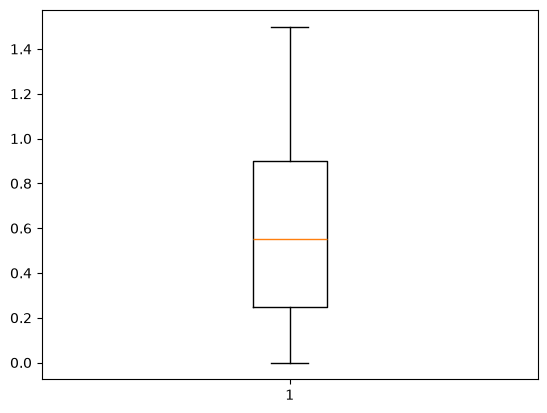

In [11]:
y = list(df.income)
plt.boxplot(y)
plt.show()

## 5. Reduced-activity days by gender

In [13]:
df.groupby(['gender', 'reduced']).mean(numeric_only=True)

Unnamed: 0    visits       age    income   illness    health
gender reduced                                                               
female 0        2524.038512  0.229322  0.465755  0.482735  1.462144  1.115098
       1        1985.768421  0.400000  0.325684  0.542105  2.242105  1.610526
       2        1622.618182  0.672727  0.391455  0.560182  2.236364  1.781818
       3         997.311111  1.333333  0.403111  0.516000  2.733333  1.733333
       4        1237.740741  0.851852  0.458889  0.466667  2.222222  2.074074
       5        1169.055556  1.444444  0.401667  0.614444  2.222222  2.500000
       6        1382.545455  1.363636  0.426364  0.622727  2.363636  1.363636
       7        1034.846154  1.384615  0.436154  0.473462  2.653846  2.230769
       8        1883.090909  1.090909  0.471818  0.404545  2.181818  4.000000
       9        1349.000000  0.500000  0.570000  0.825000  3.000000  1.000000
       10       1099.428571  2.142857  0.512857  0.421429  2.571429  2.000000
       12       1661.000000  2.000000  0.720000  0.250000  3.500000  5.500000
       13        906.000000  4.000000  0.720000  0.300000  4.500000  3.500000
       14       1392.112069  1.543103  0.551724  0.427586  2.534483  4.112069
male   0        3008.911019  0.136007  0.344703  0.694398  1.099585  0.924850
       1        2485.158537  0.304878  0.286220  0.676341  1.743902  1.256098
       2        2007.679245  0.471698  0.343585  0.653019  2.358491  1.547170
       3        1909.068966  0.724138  0.334138  0.741379  2.137931  1.689655
       4        1424.000000  0.722222  0.309444  0.869444  2.055556  2.000000
       5        1437.272727  1.136364  0.331818  0.570455  2.272727  2.818182
       6         562.000000  0.833333  0.340000  0.591667  2.500000  2.000000
       7        1716.750000  0.750000  0.314167  0.655000  2.583333  4.333333
       8         680.666667  1.333333  0.365000  0.833333  2.666667  2.000000
       9        1375.400000  2.200000  0.310000  0.392000  2.400000  2.000000
       10       1543.200000  1.800000  0.480000  0.590000  2.600000  4.600000
       11        355.500000  5.000000  0.320000  1.000000  1.500000  0.500000
       12        781.500000  2.000000  0.370000  0.515000  1.500000  1.000000
       13        508.666667  4.000000  0.510000  0.350000  3.333333  2.333333
       14       1236.069444  1.555556  0.476806  0.598611  2.375000  3.527778

## 6. Check for missing values

<Axes: >

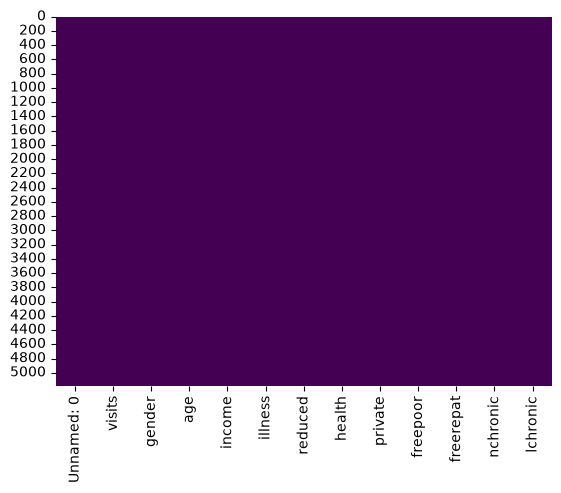

In [15]:
# Check where values are missing
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')

## 7. Correlations between the variables

<Axes: >

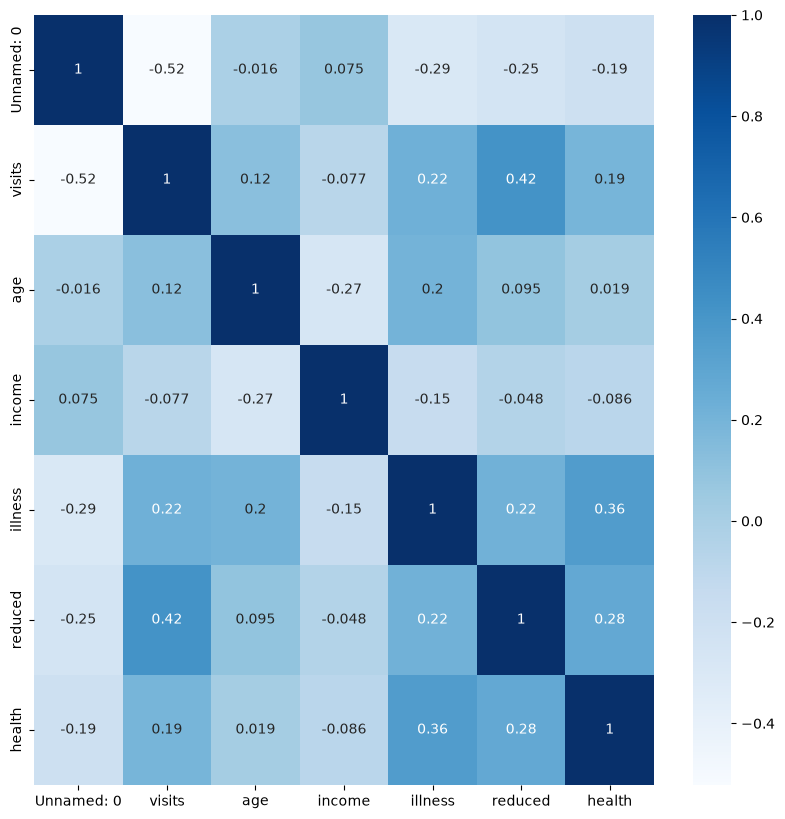

In [17]:
plt.figure(figsize=(10,10))
sns.heatmap(df.corr(numeric_only=True),cbar=True,annot=True,cmap='Blues')

## 8. Income and doctor visits

Text(0, 0.5, 'visits')

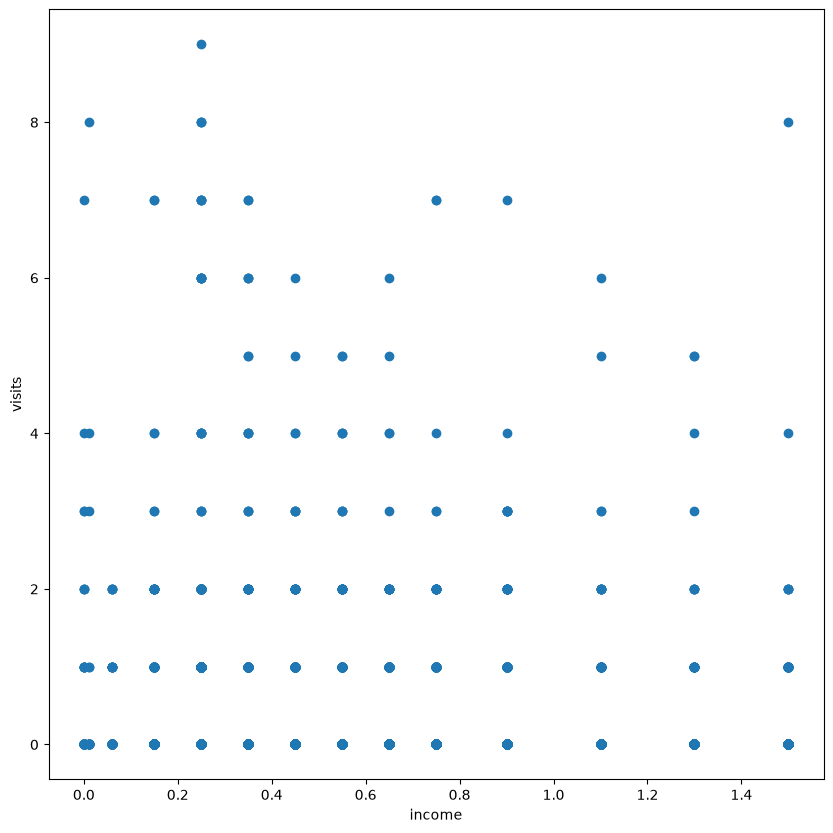

In [18]:
# Compare income with doctor visits
plt.figure(figsize=(10,10))
plt.scatter(x = 'income',y = 'visits',data = df)
plt.xlabel('income')
plt.ylabel('visits')

## 9. Gender distribution among respondents

<Axes: xlabel='gender', ylabel='Count'>

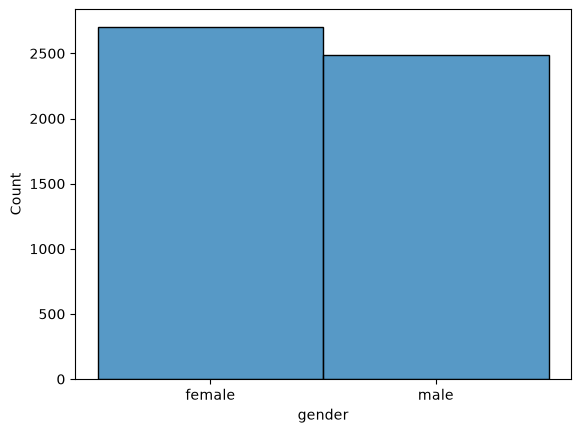

In [19]:
# Count respondents by gender
sns.histplot(df.gender,bins=2)

## 10. Health insurance coverage

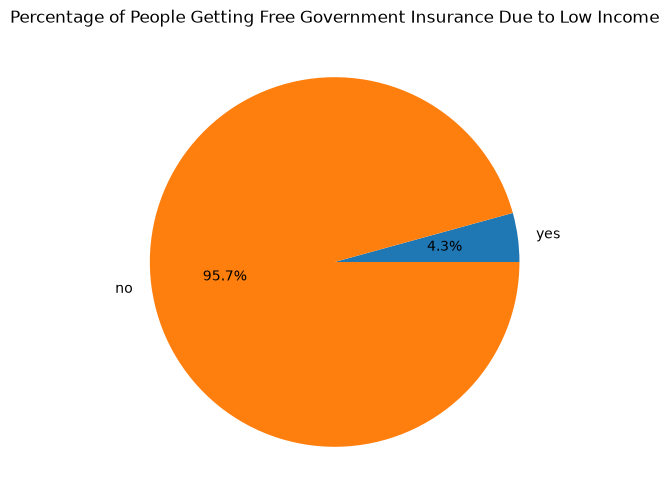

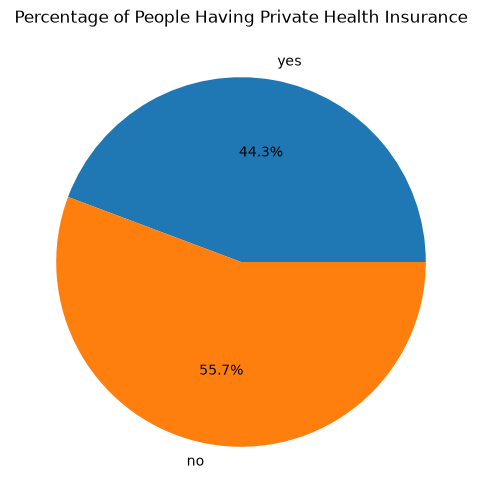

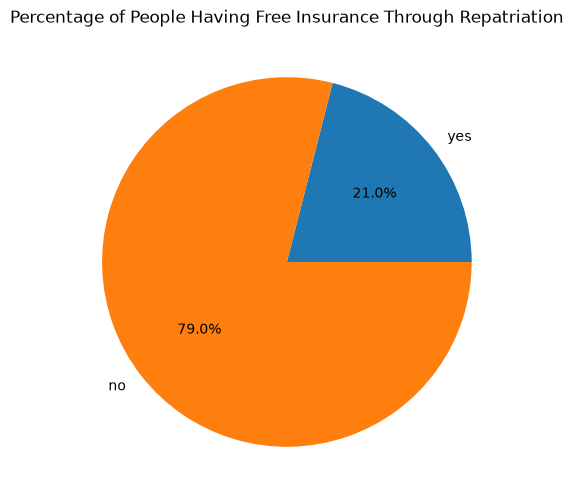

In [22]:

import matplotlib.pyplot as plt

# 1. Government health insurance due to low income
y = ['yes', 'no']
N = df[df['freepoor'] == 'yes']
X = df[df['freepoor'] == 'no']

x = [N.shape[0], X.shape[0]]

plt.figure(figsize=(6, 6))
plt.pie(x, labels=y, autopct='%.1f%%')
plt.title('Percentage of People Getting Free Government Insurance Due to Low Income')
plt.show()


# 2. Percentage of people having private health insurance
y = ['yes', 'no']
N = df[df['private'] == 'yes']
X = df[df['private'] == 'no']

x = [N.shape[0], X.shape[0]]

plt.figure(figsize=(6, 6))
plt.pie(x, labels=y, autopct='%.1f%%')
plt.title('Percentage of People Having Private Health Insurance')
plt.show()


# 3. Government insurance due to old age, disability,
# or veteran status
y = ['yes', 'no']
N = df[df['freerepat'] == 'yes']
X = df[df['freerepat'] == 'no']

x = [N.shape[0], X.shape[0]]

plt.figure(figsize=(6, 6))
plt.pie(x, labels=y, autopct='%.1f%%')
plt.title('Percentage of People Having Free Insurance Through Repatriation')
plt.show()


## 11. Reduced-activity days by gender

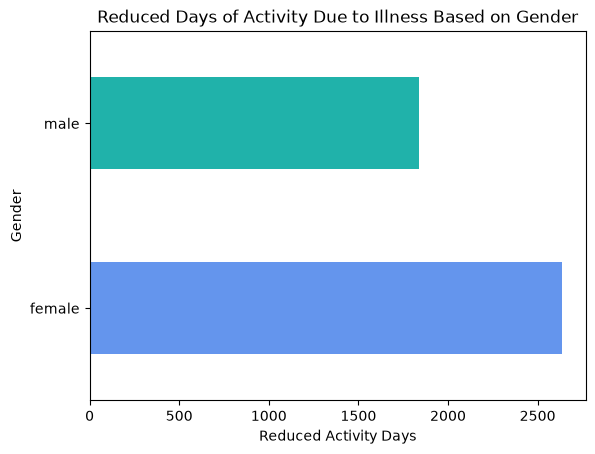

In [23]:

import matplotlib.pyplot as plt

# Add up reduced-activity days for each gender
df1 = df.groupby('gender')['reduced'].sum().to_frame().reset_index()

# Plot the totals as horizontal bars
df1.plot.barh(
    x='gender',
    y='reduced',
    color=['cornflowerblue', 'lightseagreen'],
    legend=False
)

# Label the chart
plt.title('Reduced Days of Activity Due to Illness Based on Gender')
plt.xlabel('Reduced Activity Days')
plt.ylabel('Gender')

plt.show()


## 12. Age group and doctor visits

Using the existing DataFrame `df`.
Data types:
age       float64
visits      int64
dtype: object
Age summary statistics:
count    5190.000000
mean        0.406385
std         0.204782
min         0.190000
25%         0.220000
50%         0.320000
75%         0.620000
max         0.720000
Name: age, dtype: float64

Minimum age value : 0.19
Maximum age value : 0.72
Unique age values : 12
Non-numeric entries converted to NaN: 0

First 10 unique values: [np.float64(0.19), np.float64(0.22), np.float64(0.27), np.float64(0.32), np.float64(0.37), np.float64(0.42), np.float64(0.47), np.float64(0.52), np.float64(0.57), np.float64(0.62)]
Max age = 0.72 (<= 1.5): looks like 'years divided by 100'. Multiplying by 100.
Missing values in the two columns used here:
age       0
visits    0
dtype: int64

Rows before: 5190 | rows used: 5190 | rows removed: 0
Negative visit values removed: 0
Observed age range: 19.0 to 72.0 years
Age groups used: ['10-19', '20-29', '30-39', '40-49', '50-59', '60-69', '70-

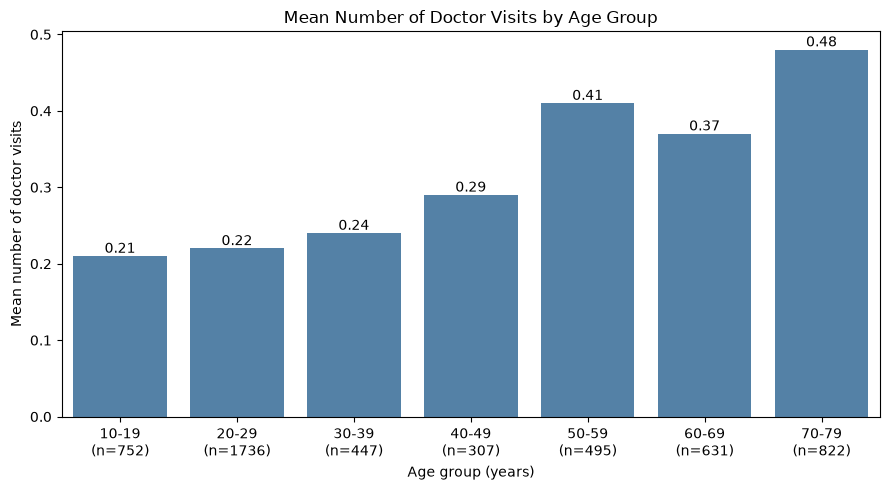

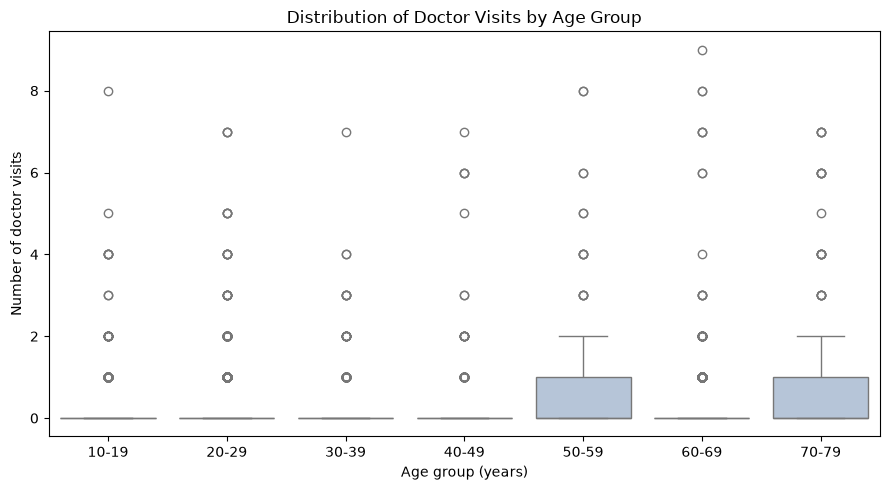

Highest mean visits: 70-79 years (mean = 0.48, n = 822)
The interval for 70-79 overlaps with 50-59 (next highest), so the data do NOT clearly show it is higher than the others.
Interpretation
--------------
- 5190 patients were analysed across 7 age groups (19.0 to 72.0 years).
- Mean visits range from 0.21 (10-19) to 0.48 (70-79).
- Median visits range from 0.0 to 0.0. Where the mean is well above the median, a minority of patients with many visits is pulling the mean up.
- The standard deviations (0.64 to 0.98) show how spread out visits are within each group.
- This is descriptive only: it shows how visits differ by age group in this sample, not why, and other factors (e.g. health status, income, insurance) are not controlled for.


In [11]:
# Age Group vs. Number of Doctor Visits
# Compare visit counts across age groups with summary statistics and plots.
# This is a descriptive analysis; it can't show that age causes differences in visit counts.

# Update these names if your dataset uses different column labels.
AGE_COL = "age"
VISITS_COL = "visits"

# Reuse `df` if it already exists in the notebook.
# Load the CSV only when `df` hasn't been created yet.
if "df" not in globals():
    df = pd.read_csv("DoctorVisits - DA.csv")
    print("df was not found, so the CSV was loaded.")
else:
    print("Using the existing DataFrame `df`.")

# %% Step 1: Check the columns exist and look at their types
missing_cols = [c for c in (AGE_COL, VISITS_COL) if c not in df.columns]
if missing_cols:
    raise KeyError(f"Column(s) not found: {missing_cols}. Available columns: {list(df.columns)}")

print("Data types:")
print(df[[AGE_COL, VISITS_COL]].dtypes)

# %% Step 2: Inspect the `age` column BEFORE converting anything
# Force numeric type; any non-numeric entry becomes NaN (and we report how many).
age_raw = pd.to_numeric(df[AGE_COL], errors="coerce")
n_coerced = age_raw.isna().sum() - df[AGE_COL].isna().sum()

print("Age summary statistics:")
print(age_raw.describe())
print(f"\nMinimum age value : {age_raw.min()}")
print(f"Maximum age value : {age_raw.max()}")
print(f"Unique age values : {age_raw.nunique()}")
print(f"Non-numeric entries converted to NaN: {n_coerced}")
print("\nFirst 10 unique values:", sorted(age_raw.dropna().unique())[:10])

# %% Step 3: Work out the age scale from the observed values
age_min, age_max = age_raw.min(), age_raw.max()

if age_min < 0:
    raise ValueError("Negative ages found - please clean the data before continuing.")
elif age_max <= 1.5:
    # Values like 0.19 or 0.72 suggest age stored as years / 100.
    age_scale = 100
    print(f"Max age = {age_max:.2f} (<= 1.5): looks like 'years divided by 100'. Multiplying by 100.")
elif age_max <= 120:
    age_scale = 1
    print(f"Max age = {age_max:.1f}: values already look like years. No conversion needed.")
else:
    raise ValueError(
        f"Max age = {age_max}: not a plausible value in years or years/100. "
        "Check the data dictionary (it could be months, days, or a coded category)."
    )
# Tip: confirm this against your dataset's documentation if you have one.

# %% Step 4: Remove rows that can't be analysed
# Only rows missing age or visits are removed, and only for THIS analysis.
# The original `df` is not changed. We cannot group a patient without age,
# and cannot average visits without a visit count.
n_before = len(df)
print("Missing values in the two columns used here:")
print(df[[AGE_COL, VISITS_COL]].isna().sum())

df_age = df[[AGE_COL, VISITS_COL]].copy()
df_age[AGE_COL] = pd.to_numeric(df_age[AGE_COL], errors="coerce")
df_age[VISITS_COL] = pd.to_numeric(df_age[VISITS_COL], errors="coerce")
df_age = df_age.dropna(subset=[AGE_COL, VISITS_COL])

# Visit counts cannot be negative; flag (and drop) any impossible values.
n_negative = (df_age[VISITS_COL] < 0).sum()
df_age = df_age[df_age[VISITS_COL] >= 0]

print(f"\nRows before: {n_before} | rows used: {len(df_age)} | rows removed: {n_before - len(df_age)}")
print(f"Negative visit values removed: {n_negative}")

# Convert to years (rounding avoids floating-point noise such as 19.000000000000004)
df_age["age_years"] = (df_age[AGE_COL] * age_scale).round(1)

# %% Step 5: Group ages using the range found in the data
# 10-year groups that cover the observed range, e.g. 20-29, 30-39, ...
lower = int(np.floor(df_age["age_years"].min() / 10) * 10)
upper = int(np.floor(df_age["age_years"].max() / 10) * 10) + 10
bin_edges = list(range(lower, upper + 1, 10))
bin_labels = [f"{start}-{start + 9}" for start in bin_edges[:-1]]

# right=False means each group includes its start age but not the next one (30 belongs to 30-39)
df_age["age_group"] = pd.cut(
    df_age["age_years"], bins=bin_edges, labels=bin_labels, right=False
)

print(f"Observed age range: {df_age['age_years'].min()} to {df_age['age_years'].max()} years")
print("Age groups used:", bin_labels)
print("Patients without a group (should be 0):", df_age["age_group"].isna().sum())

# %% Step 6: Summarise visits by age group
summary = (
    df_age.groupby("age_group", observed=True)[VISITS_COL]
    .agg(patients="count", mean_visits="mean", median_visits="median", std_visits="std")
    .round(2)
)

print("Doctor visits by age group")
print(summary)  # use display(summary) for a nicer look in Jupyter

# %% Step 7: Plot mean visits by age group
# Put the group size (n) under each label so readers can see how reliable each bar is.
plot_df = summary.reset_index()
plot_df["label"] = plot_df["age_group"].astype(str) + "\n(n=" + plot_df["patients"].astype(str) + ")"

plt.figure(figsize=(9, 5))
ax = sns.barplot(data=plot_df, x="label", y="mean_visits", color="steelblue")
for bar, value in zip(ax.patches, plot_df["mean_visits"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{value:.2f}",
            ha="center", va="bottom", fontsize=10)
ax.set_title("Mean Number of Doctor Visits by Age Group")
ax.set_xlabel("Age group (years)")
ax.set_ylabel("Mean number of doctor visits")
plt.tight_layout()
plt.show()

# %% Step 8: Compare visit distributions with a boxplot
plt.figure(figsize=(9, 5))
sns.boxplot(data=df_age, x="age_group", y=VISITS_COL, order=bin_labels, color="lightsteelblue")
plt.title("Distribution of Doctor Visits by Age Group")
plt.xlabel("Age group (years)")
plt.ylabel("Number of doctor visits")
plt.tight_layout()
plt.show()
# Visit counts are usually skewed (many low values, a few high ones), so points above
# the whiskers are expected and are real observations, not errors.

# %% Step 9: Find the highest mean and check how uncertain it is
top_group = summary["mean_visits"].idxmax()
top_row = summary.loc[top_group]

# Rough 95% interval for each mean: mean +/- 1.96 * standard error
summary["se"] = summary["std_visits"] / np.sqrt(summary["patients"])
summary["ci_low"] = summary["mean_visits"] - 1.96 * summary["se"]
summary["ci_high"] = summary["mean_visits"] + 1.96 * summary["se"]

others = summary.drop(index=top_group)
runner_up = others["mean_visits"].idxmax() if len(others) else None

print(f"Highest mean visits: {top_group} years (mean = {top_row['mean_visits']:.2f}, n = {int(top_row['patients'])})")

MIN_N = 30  # rule of thumb for a reasonably stable mean
if top_row["patients"] < MIN_N:
    print(f"Caution: this group has fewer than {MIN_N} patients, so its mean is not very stable.")

if runner_up is not None:
    overlap = summary.loc[top_group, "ci_low"] <= summary.loc[runner_up, "ci_high"]
    if overlap:
        print(f"The interval for {top_group} overlaps with {runner_up} (next highest), "
              "so the data do NOT clearly show it is higher than the others.")
    else:
        print(f"The interval for {top_group} does not overlap with {runner_up} (next highest), "
              "so the data support it having the highest mean in this sample.")

# %% Step 10: Summarise what the results show
low_group = summary["mean_visits"].idxmin()
print("Interpretation")
print("-" * 14)
print(f"- {len(df_age)} patients were analysed across {len(summary)} age groups "
      f"({df_age['age_years'].min()} to {df_age['age_years'].max()} years).")
print(f"- Mean visits range from {summary['mean_visits'].min():.2f} ({low_group}) "
      f"to {summary['mean_visits'].max():.2f} ({top_group}).")
print(f"- Median visits range from {summary['median_visits'].min():.1f} to "
      f"{summary['median_visits'].max():.1f}. Where the mean is well above the median, "
      "a minority of patients with many visits is pulling the mean up.")
print(f"- The standard deviations ({summary['std_visits'].min():.2f} to "
      f"{summary['std_visits'].max():.2f}) show how spread out visits are within each group.")
print("- This is descriptive only: it shows how visits differ by age group in this sample, "
      "not why, and other factors (e.g. health status, income, insurance) are not controlled for.") 

## 13. Reported illnesses and doctor visits


'illness' dtype: int64
Distinct values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Min: 0 | Max: 5
Looks like a non-negative whole-number count: True
Missing values in the columns used here:
illness    0
visits     0
dtype: int64

Rows before: 5190 | rows used: 5190 | rows removed: 0
Negative visit values removed: 0
Descriptive statistics
       illness  visits
count  5190.00  5190.0
mean      1.43     0.3
std       1.38     0.8
min       0.00     0.0
25%       0.00     0.0
50%       1.00     0.0
75%       2.00     0.0
max       5.00     9.0
Doctor visits by illness count (small_group = fewer than 30 patients)
         patients  mean_visits  median_visits  std_visits  small_group
illness                                                               
0            1554         0.08            0.0        0.32        False
1            1638         0.30            0.0        0.81        False
2             946         0.40            0.0        0.89    

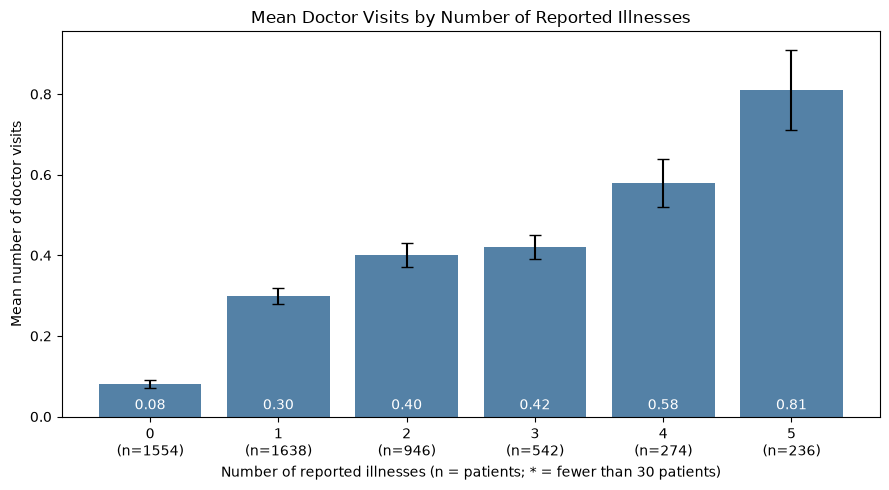

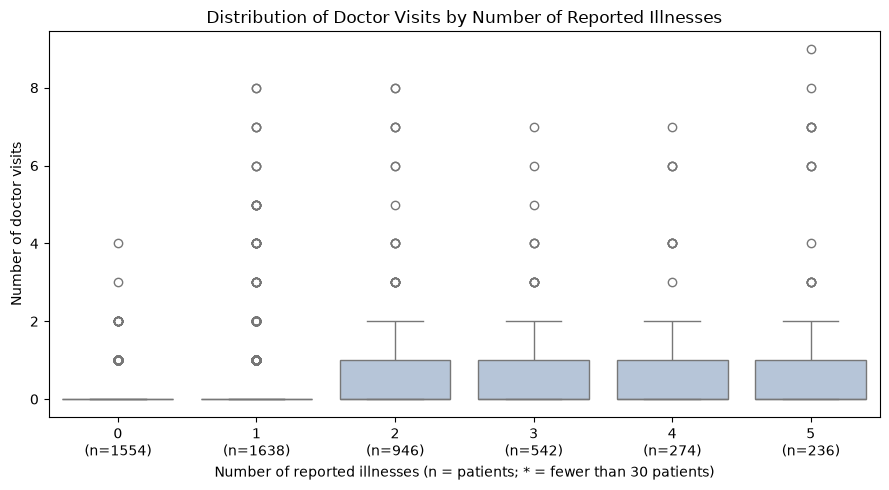

Spearman correlation (all 5190 patients): rho = 0.263, p-value < 0.001
Strength (rule of thumb): weak
Interpretation
--------------
- 5190 patients were analysed; 0 rows were excluded for missing/invalid values.
- Spearman rho = 0.263 (p < 0.001): a weak positive (more illnesses, more visits on average) association.
- Among groups with at least 30 patients, mean visits rose in 5 of 5 steps from one illness count to the next (0.08 at 0 illnesses to 0.81 at 5).
- The p-value suggests the association is unlikely to be due to chance alone in this sample, but with many patients even a small association can be 'significant'; rho shows how large it is.

Association vs. causation
- These results describe an ASSOCIATION between reported illness count and visits.
- They do not show that illnesses cause more visits (or that visits cause more reported illnesses).
- Other factors (age, income, insurance, chronic conditions) are not controlled for here,
  and illness counts are self-reported, which 

In [13]:
from scipy import stats
ILLNESS_COL = "illness"   # change here if your illness-count column has another name
VISITS_COL = "visits"
MIN_N = 30                # groups smaller than this are flagged as "small" (rule of thumb)
 
for col in (ILLNESS_COL, VISITS_COL):
    if col not in df.columns:
        raise KeyError(f"Column '{col}' not found. Choose from: {list(df.columns)}")
 
# Check that illness values are non-negative whole-number counts.
illness_num = pd.to_numeric(df[ILLNESS_COL], errors="coerce")
print(f"\n'{ILLNESS_COL}' dtype: {df[ILLNESS_COL].dtype}")
print("Distinct values:", sorted(illness_num.dropna().unique()))
print("Min:", illness_num.min(), "| Max:", illness_num.max())
is_count_like = (illness_num.dropna() % 1 == 0).all() and (illness_num.min() >= 0)
print("Looks like a non-negative whole-number count:", is_count_like)
if not is_count_like:
    raise ValueError(f"'{ILLNESS_COL}' does not look like an illness count - check your data dictionary.")
 
# %% Step 2: Handle missing values for this analysis only
n_before = len(df)
print("Missing values in the columns used here:")
print(df[[ILLNESS_COL, VISITS_COL]].isna().sum())
 
df_ill = df[[ILLNESS_COL, VISITS_COL]].copy()
df_ill[ILLNESS_COL] = pd.to_numeric(df_ill[ILLNESS_COL], errors="coerce")
df_ill[VISITS_COL] = pd.to_numeric(df_ill[VISITS_COL], errors="coerce")
 
# Rows missing either value can't be included in this comparison.
df_ill = df_ill.dropna(subset=[ILLNESS_COL, VISITS_COL])
n_negative = (df_ill[VISITS_COL] < 0).sum()          # visit counts cannot be negative
df_ill = df_ill[df_ill[VISITS_COL] >= 0]
df_ill[ILLNESS_COL] = df_ill[ILLNESS_COL].astype(int)
 
print(f"\nRows before: {n_before} | rows used: {len(df_ill)} | rows removed: {n_before - len(df_ill)}")
print(f"Negative visit values removed: {n_negative}")
 
# %% Step 3: Descriptive statistics for both variables
print("Descriptive statistics")
print(df_ill[[ILLNESS_COL, VISITS_COL]].describe().round(2))
 
# %% Step 4: Summary by illness count (with small-group flag)
summary = (
    df_ill.groupby(ILLNESS_COL)[VISITS_COL]
    .agg(patients="count", mean_visits="mean", median_visits="median", std_visits="std")
)
summary["std_error"] = summary["std_visits"] / np.sqrt(summary["patients"])
summary["small_group"] = summary["patients"] < MIN_N
summary = summary.round(2)
 
print(f"Doctor visits by illness count (small_group = fewer than {MIN_N} patients)")
print(summary[["patients", "mean_visits", "median_visits", "std_visits", "small_group"]])
 
small = summary[summary["small_group"]]
if len(small):
    print(f"\nCaution: illness count(s) {list(small.index)} have fewer than {MIN_N} patients. "
          "Their means and spreads are unstable (a standard deviation cannot be computed for a group of 1).")
else:
    print(f"\nAll groups have at least {MIN_N} patients.")
 
# Plot labels: "illnesses (n=...)", with * marking small groups
label_map = {
    k: f"{k}\n(n={int(r['patients'])}){'*' if r['small_group'] else ''}"
    for k, r in summary.iterrows()
}
label_order = [label_map[k] for k in summary.index]
df_ill["illness_label"] = df_ill[ILLNESS_COL].map(label_map)
 
# %% Step 5: Bar chart of mean visits by illness count
plot_df = summary.reset_index()
plot_df["label"] = plot_df[ILLNESS_COL].map(label_map)
 
plt.figure(figsize=(9, 5))
ax = sns.barplot(data=plot_df, x="label", y="mean_visits", order=label_order, color="steelblue")
# Error bars: mean +/- 1 standard error (missing for groups of 1, so shown as 0)
ax.errorbar(range(len(plot_df)), plot_df["mean_visits"], yerr=plot_df["std_error"].fillna(0),
            fmt="none", ecolor="black", capsize=4)
for i, v in enumerate(plot_df["mean_visits"]):
    ax.text(i, 0.01, f"{v:.2f}", ha="center", va="bottom", color="white", fontsize=10)
ax.set_title("Mean Doctor Visits by Number of Reported Illnesses")
ax.set_xlabel("Number of reported illnesses (n = patients; * = fewer than "
              f"{MIN_N} patients)")
ax.set_ylabel("Mean number of doctor visits")
plt.tight_layout()
plt.show()
 
# %% Step 6: Boxplot of visits for each illness count
plt.figure(figsize=(9, 5))
sns.boxplot(data=df_ill, x="illness_label", y=VISITS_COL, order=label_order, color="lightsteelblue")
plt.title("Distribution of Doctor Visits by Number of Reported Illnesses")
plt.xlabel(f"Number of reported illnesses (n = patients; * = fewer than {MIN_N} patients)")
plt.ylabel("Number of doctor visits")
plt.tight_layout()
plt.show()
# Visit counts are skewed with many low values, so points beyond the whiskers are expected.
 
# %% Step 7: Spearman correlation
# Spearman is a good fit here: both variables are counts, the data are skewed,
# and it only assumes a consistent upward/downward trend (not a straight line).
rho, p_value = stats.spearmanr(df_ill[ILLNESS_COL], df_ill[VISITS_COL])
 
def strength(r):
    r = abs(r)
    if r < 0.10: return "negligible"
    if r < 0.30: return "weak"
    if r < 0.50: return "moderate"
    return "strong"
 
p_text = "< 0.001" if p_value < 0.001 else f"= {p_value:.3f}"
print(f"Spearman correlation (all {len(df_ill)} patients): rho = {rho:.3f}, p-value {p_text}")
print(f"Strength (rule of thumb): {strength(rho)}")
 
# Sensitivity check: repeat without the small groups to see if the result depends on them.
reliable = df_ill[df_ill[ILLNESS_COL].isin(summary.index[~summary["small_group"]])]
if len(small) and reliable[ILLNESS_COL].nunique() > 1:
    rho_r, p_r = stats.spearmanr(reliable[ILLNESS_COL], reliable[VISITS_COL])
    p_r_text = "< 0.001" if p_r < 0.001 else f"= {p_r:.3f}"
    print(f"Without small groups ({len(reliable)} patients): rho = {rho_r:.3f}, p-value {p_r_text}")
else:
    rho_r = None
 
# %% Step 8: Interpretation based on the actual output above
reliable_means = summary.loc[~summary["small_group"], "mean_visits"]
steps = reliable_means.diff().dropna()
n_up, n_steps = int((steps > 0).sum()), len(steps)
direction = "positive (more illnesses, more visits on average)" if rho > 0 else \
            "negative (more illnesses, fewer visits on average)" if rho < 0 else "none"
 
print("Interpretation")
print("-" * 14)
print(f"- {len(df_ill)} patients were analysed; {n_before - len(df_ill)} rows were excluded for missing/invalid values.")
print(f"- Spearman rho = {rho:.3f} (p {p_text}): a {strength(rho)} {direction} association.")
if n_steps:
    print(f"- Among groups with at least {MIN_N} patients, mean visits rose in {n_up} of {n_steps} "
          f"steps from one illness count to the next "
          f"({reliable_means.iloc[0]:.2f} at {reliable_means.index[0]} illnesses to "
          f"{reliable_means.iloc[-1]:.2f} at {reliable_means.index[-1]}).")
if len(small):
    print(f"- Groups with {list(small.index)} illnesses are small, so their bars/boxes should not be over-interpreted.")
if rho_r is not None:
    print(f"- Excluding small groups gives rho = {rho_r:.3f}, "
          f"{'similar to' if abs(rho_r - rho) < 0.05 else 'different from'} the full-sample value.")
if p_value < 0.05:
    print("- The p-value suggests the association is unlikely to be due to chance alone in this sample, "
          "but with many patients even a small association can be 'significant'; rho shows how large it is.")
else:
    print("- The p-value does not provide clear evidence of an association in this sample.")
 
print("\nAssociation vs. causation")
print("- These results describe an ASSOCIATION between reported illness count and visits.")
print("- They do not show that illnesses cause more visits (or that visits cause more reported illnesses).")
print("- Other factors (age, income, insurance, chronic conditions) are not controlled for here,")
print("  and illness counts are self-reported, which may be influenced by how often a person sees a doctor.")
 

## 14. Chronic conditions and healthcare use

All columns: ['Unnamed: 0', 'visits', 'gender', 'age', 'income', 'illness', 'reduced', 'health', 'private', 'freepoor', 'freerepat', 'nchronic', 'lchronic']

--- nchronic ---
dtype: str
nchronic
no     3098
yes    2092
Name: count, dtype: int64

--- lchronic ---
dtype: str
lchronic
no     4585
yes     605
Name: count, dtype: int64
Documented meaning: (not entered - see Step 2)

[nchronic] rows: 5190 | used: 5190 | removed for missing values: 0 | removed for negative visits: 0

Doctor visits by nchronic (small_group = fewer than 30 patients)
       patients  mean_visits  median_visits  std_visits  pct_zero_visits  \
group                                                                      
no         3098         0.27            0.0        0.78            82.12   
yes        2092         0.35            0.0        0.82            76.34   

       small_group  
group               
no           False  
yes          False  


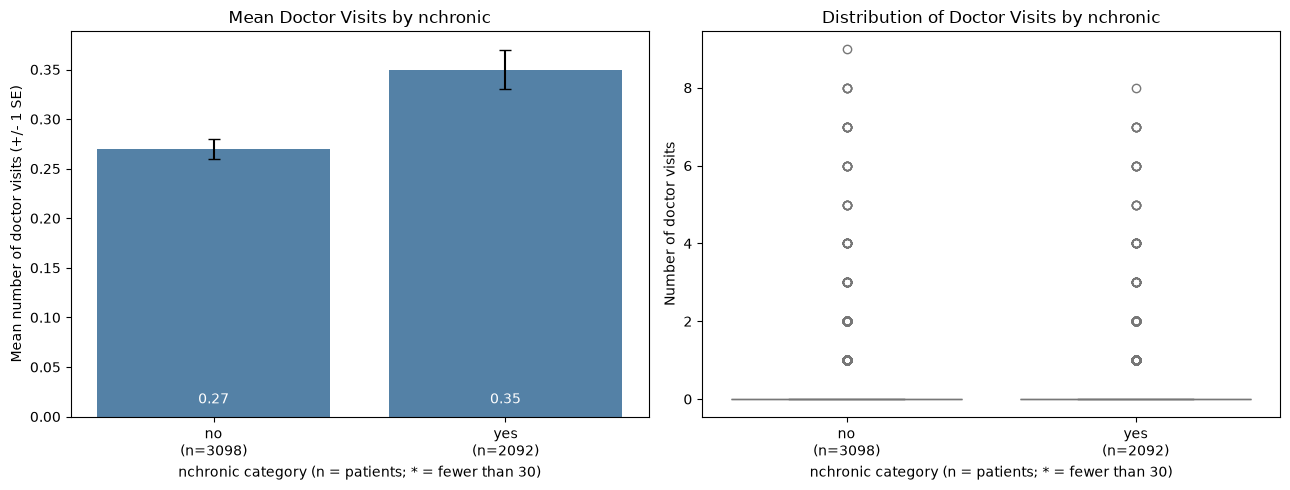

Assumption checks
  no               n=3098  skewness=  5.22   zero visits= 82.1%
  yes              n=2092  skewness=  4.12   zero visits= 76.3%
  Levene test for equal spread: p = 0.001

Mann-Whitney U test (yes vs no): p < 0.001
Cliff's delta = 0.057 (negligible) | Cohen's d = 0.092 (negligible)
Mean difference (yes - no) = 0.073, 95% CI [0.029, 0.118]
Welch t-test (sensitivity check): p = 0.001

Interpretation - nchronic
- Mean visits: 0.35 for 'yes' vs 0.27 for 'no' (difference +0.07, 95% CI +0.03 to +0.12).
- Mann-Whitney p < 0.001: a statistically significant difference in the visit distributions.
- Effect size: Cliff's delta = 0.06 (negligible). A randomly chosen 'yes' patient had more visits than a 'no' patient about 53% of the time (ties counted half).
- The Welch t-test (p = 0.001) gives the same conclusion.
- The medians are identical across the compared groups (visit counts are mostly low), so differences show up mainly in the means and the upper tail rather than the media

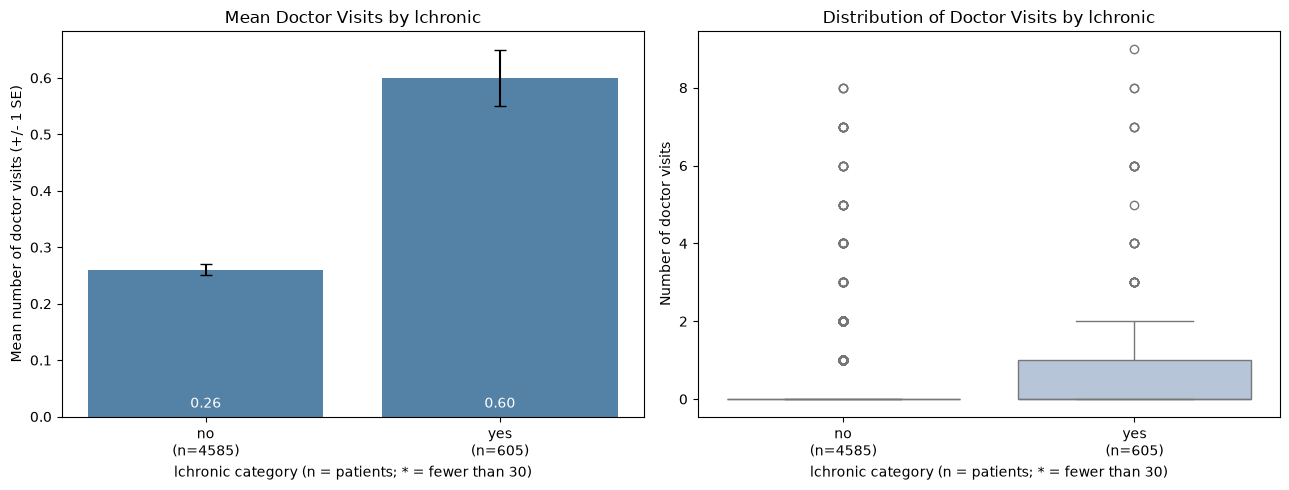

Assumption checks
  no               n=4585  skewness=  4.90   zero visits= 81.7%
  yes              n=605   skewness=  3.48   zero visits= 65.0%
  Levene test for equal spread: p < 0.001

Mann-Whitney U test (yes vs no): p < 0.001
Cliff's delta = 0.175 (small) | Cohen's d = 0.346 (small)
Mean difference (yes - no) = 0.341, 95% CI [0.244, 0.439]
Welch t-test (sensitivity check): p < 0.001

Interpretation - lchronic
- Mean visits: 0.60 for 'yes' vs 0.26 for 'no' (difference +0.34, 95% CI +0.24 to +0.44).
- Mann-Whitney p < 0.001: a statistically significant difference in the visit distributions.
- Effect size: Cliff's delta = 0.17 (small). A randomly chosen 'yes' patient had more visits than a 'no' patient about 59% of the time (ties counted half).
- The Welch t-test (p < 0.001) gives the same conclusion.
- The medians are identical across the compared groups (visit counts are mostly low), so differences show up mainly in the means and the upper tail rather than the median.
- This descr

In [16]:
#  Chronic Conditions and Healthcare Utilization
# Compare doctor visits across `nchronic` and `lchronic`; if both
# are yes/no flags, also compare people with both conditions against everyone else.
# These results describe associations; they don't establish cause and effect.
N_COL = "nchronic"
L_COL = "lchronic"
VISITS_COL = "visits"

MIN_N = 30        # groups smaller than this are flagged as "small" (unstable means)
MIN_TEST_N = 5    # groups smaller than this are left out of statistical tests
ALPHA = 0.05      # significance threshold

# %% Step 1: Check the columns and their recorded values
print("All columns:", list(df.columns))
for col in (N_COL, L_COL, VISITS_COL):
    if col not in df.columns:
        raise KeyError(f"Column '{col}' not found. Choose from: {list(df.columns)}")

for col in (N_COL, L_COL):
    print(f"\n--- {col} ---")
    print("dtype:", df[col].dtype)
    print(df[col].value_counts(dropna=False))

# %% Step 2: Record the variable definitions from your documentation
# Enter the documented meanings from your data dictionary. The code won't infer them.
# These descriptions appear in the printed interpretation, for example: "Chronic condition (yes/no)".
DEFINITIONS = {
    N_COL: "",   # <- write the documented meaning of nchronic here
    L_COL: "",   # <- write the documented meaning of lchronic here
}

# For the "both conditions" analysis the code needs to know which value means the condition is present.
# Leave as None to auto-detect ('yes', or '1' for a 0/1 column). Set e.g. "yes" or "1" to override.
POSITIVE_VALUES = {N_COL: None, L_COL: None}

for col, text in DEFINITIONS.items():
    if not text.strip():
        print(f"WARNING: no documented definition entered for '{col}'. "
              "Interpretation below describes data patterns only; confirm what the variable means "
              "before writing conclusions.")

# %% Step 3: Helper functions (reused for both variables)
def to_category(series):
    """Convert a column to clean text categories: 1.0 -> '1', ' Yes' -> 'yes'. Missing stays missing."""
    s = series.copy()
    if pd.api.types.is_bool_dtype(s):
        s = s.astype(int)
    num = pd.to_numeric(s, errors="coerce")
    if num.notna().sum() == s.notna().sum():           # every non-missing value is a number
        s = num.map(lambda v: np.nan if pd.isna(v) else (str(int(v)) if float(v).is_integer() else str(v)))
    else:
        s = s.astype("string").str.strip().str.lower()
    return s.astype(object)


def category_order(values):
    """Sensible display order: numeric ascending, or no -> yes, otherwise alphabetical."""
    values = list(values)
    try:
        return sorted(values, key=float)
    except ValueError:
        if set(values) <= {"no", "yes"}:
            return [v for v in ("no", "yes") if v in values]
        return sorted(values)


def prepare(col):
    """Return a clean table with the group (category) and visits; report what was dropped."""
    d = pd.DataFrame({"group": to_category(df[col]),
                      "visits": pd.to_numeric(df[VISITS_COL], errors="coerce")})
    n_before = len(d)
    d = d.dropna()                                       # missing category or visits -> cannot be used
    n_negative = int((d["visits"] < 0).sum())
    d = d[d["visits"] >= 0]                              # visit counts cannot be negative
    print(f"[{col}] rows: {n_before} | used: {len(d)} | removed for missing values: "
          f"{n_before - len(d) - n_negative} | removed for negative visits: {n_negative}")
    return d


def summarise(d, order):
    """Group size, mean, median, standard deviation (plus % of patients with zero visits)."""
    s = d.groupby("group")["visits"].agg(
        patients="count", mean_visits="mean", median_visits="median", std_visits="std").reindex(order)
    s["pct_zero_visits"] = d.groupby("group")["visits"].apply(lambda x: (x == 0).mean() * 100).reindex(order)
    s["std_error"] = s["std_visits"] / np.sqrt(s["patients"])
    s["small_group"] = s["patients"] < MIN_N
    return s.round(2)


def plot_groups(d, s, order, name):
    """Bar chart (mean +/- 1 standard error) and boxplot side by side."""
    labels = {g: f"{g}\n(n={int(s.loc[g, 'patients'])}){'*' if s.loc[g, 'small_group'] else ''}" for g in order}
    label_order = [labels[g] for g in order]
    plot_d = d.assign(label=d["group"].map(labels))
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    sns.barplot(x=label_order, y=s["mean_visits"].to_numpy(), order=label_order, color="steelblue", ax=axes[0])
    axes[0].errorbar(range(len(order)), s["mean_visits"], yerr=s["std_error"].fillna(0),
                     fmt="none", ecolor="black", capsize=4)
    for i, v in enumerate(s["mean_visits"]):
        axes[0].text(i, 0.01, f"{v:.2f}", ha="center", va="bottom", color="white", fontsize=10)
    axes[0].set_title(f"Mean Doctor Visits by {name}")
    axes[0].set_ylabel("Mean number of doctor visits (+/- 1 SE)")

    sns.boxplot(data=plot_d, x="label", y="visits", order=label_order, color="lightsteelblue", ax=axes[1])
    axes[1].set_title(f"Distribution of Doctor Visits by {name}")
    axes[1].set_ylabel("Number of doctor visits")

    for ax in axes:
        ax.set_xlabel(f"{name} category (n = patients; * = fewer than {MIN_N})")
    plt.tight_layout()
    plt.show()


def size_label(value, kind):
    """Rule-of-thumb wording for effect sizes (guidelines, not strict cut-offs)."""
    v = abs(value)
    cuts = {"delta": (0.147, 0.33, 0.474), "eps2": (0.01, 0.06, 0.14), "d": (0.2, 0.5, 0.8)}[kind]
    return "negligible" if v < cuts[0] else "small" if v < cuts[1] else "medium" if v < cuts[2] else "large"


def fmt_p(p):
    return "< 0.001" if p < 0.001 else f"= {p:.3f}"


def compare_groups(d, order, name):
    """Choose and run a suitable test after checking sample sizes and assumptions."""
    counts = d["group"].value_counts()
    usable = [g for g in order if counts.get(g, 0) >= MIN_TEST_N]
    dropped = [g for g in order if g not in usable]
    if dropped:
        print(f"Left out of the test (fewer than {MIN_TEST_N} patients): {dropped}")
    if len(usable) < 2:
        print("Not enough usable groups for a statistical test.")
        return None

    samples = {g: d.loc[d["group"] == g, "visits"].to_numpy() for g in usable}

    # Assumption checks: visit counts are discrete and typically skewed with many zeros,
    # which makes t-tests/ANOVA a poor primary choice. We therefore use rank-based tests
    # and show a Welch t-test only as a sensitivity check.
    print("Assumption checks")
    for g, x in samples.items():
        print(f"  {g:<16} n={len(x):<5} skewness={stats.skew(x):6.2f}   zero visits={np.mean(x == 0) * 100:5.1f}%")
    try:
        lev = stats.levene(*samples.values(), center="median")
        print(f"  Levene test for equal spread: p {fmt_p(lev.pvalue)}")
    except Exception:
        print("  Levene test could not be computed.")

    if len(usable) == 2:
        g0, g1 = usable
        x, y = samples[g1], samples[g0]                  # positive effect = g1 has MORE visits than g0
        u = stats.mannwhitneyu(x, y, alternative="two-sided")
        cl = u.statistic / (len(x) * len(y))             # P(random g1 patient has more visits), ties count half
        delta = 2 * cl - 1                               # Cliff's delta (rank-biserial correlation)
        welch = stats.ttest_ind(x, y, equal_var=False)
        diff = x.mean() - y.mean()
        v1, v2 = x.var(ddof=1) / len(x), y.var(ddof=1) / len(y)
        dof = (v1 + v2) ** 2 / (v1 ** 2 / (len(x) - 1) + v2 ** 2 / (len(y) - 1))
        half = stats.t.ppf(0.975, dof) * np.sqrt(v1 + v2)
        cohen_d = diff / np.sqrt((x.var(ddof=1) + y.var(ddof=1)) / 2)
        res = dict(kind="two", g0=g0, g1=g1, p=u.pvalue, cl=cl, delta=delta, welch_p=welch.pvalue,
                   diff=diff, ci=(diff - half, diff + half), cohen_d=cohen_d, dropped=dropped)
        print(f"\nMann-Whitney U test ({g1} vs {g0}): p {fmt_p(u.pvalue)}")
        print(f"Cliff's delta = {delta:.3f} ({size_label(delta, 'delta')}) | "
              f"Cohen's d = {cohen_d:.3f} ({size_label(cohen_d, 'd')})")
        print(f"Mean difference ({g1} - {g0}) = {diff:.3f}, 95% CI [{res['ci'][0]:.3f}, {res['ci'][1]:.3f}]")
        print(f"Welch t-test (sensitivity check): p {fmt_p(welch.pvalue)}")
        return res

    h = stats.kruskal(*samples.values())
    n_total = sum(len(x) for x in samples.values())
    eps2 = h.statistic / (n_total - 1)                   # epsilon-squared effect size for Kruskal-Wallis
    res = dict(kind="multi", p=h.pvalue, H=h.statistic, eps2=eps2, usable=usable, dropped=dropped, pairs=None)
    print(f"\nKruskal-Wallis test across {len(usable)} groups: H = {h.statistic:.2f}, p {fmt_p(h.pvalue)}")
    print(f"Epsilon-squared = {eps2:.3f} ({size_label(eps2, 'eps2')})")
    if h.pvalue < ALPHA:
        k = len(usable) * (len(usable) - 1) // 2         # number of pairwise comparisons (Bonferroni)
        rows = []
        for a, b in combinations(usable, 2):
            r = stats.mannwhitneyu(samples[b], samples[a], alternative="two-sided")
            dl = 2 * r.statistic / (len(samples[b]) * len(samples[a])) - 1
            rows.append({"comparison": f"{b} vs {a}", "p_raw": r.pvalue,
                         "p_bonferroni": min(1.0, r.pvalue * k), "cliffs_delta": dl,
                         "effect_size": size_label(dl, "delta")})
        res["pairs"] = pd.DataFrame(rows).round(4)
        print("\nPairwise Mann-Whitney tests (Bonferroni-adjusted; positive delta = first group has more visits):")
        print(res["pairs"].to_string(index=False))
    else:
        print("Overall test not significant, so pairwise comparisons are not run.")
    return res


def interpret(name, res, s):
    """Print an interpretation built from the actual results."""
    print(f"\nInterpretation - {name}")
    if res is None:
        print("- No statistical test was possible, so only the descriptive table applies.")
        return
    if res["kind"] == "two":
        g0, g1 = res["g0"], res["g1"]
        print(f"- Mean visits: {s.loc[g1, 'mean_visits']:.2f} for '{g1}' vs {s.loc[g0, 'mean_visits']:.2f} for '{g0}' "
              f"(difference {res['diff']:+.2f}, 95% CI {res['ci'][0]:+.2f} to {res['ci'][1]:+.2f}).")
        sig = "a statistically significant" if res["p"] < ALPHA else "no statistically significant"
        print(f"- Mann-Whitney p {fmt_p(res['p'])}: {sig} difference in the visit distributions.")
        print(f"- Effect size: Cliff's delta = {res['delta']:.2f} ({size_label(res['delta'], 'delta')}). "
              f"A randomly chosen '{g1}' patient had more visits than a '{g0}' patient about "
              f"{res['cl'] * 100:.0f}% of the time (ties counted half).")
        agree = (res["p"] < ALPHA) == (res["welch_p"] < ALPHA)
        print(f"- The Welch t-test (p {fmt_p(res['welch_p'])}) {'gives the same conclusion' if agree else 'gives a different conclusion'}.")
    else:
        sig = "differences" if res["p"] < ALPHA else "no clear differences"
        print(f"- Kruskal-Wallis p {fmt_p(res['p'])}: {sig} in visit distributions across groups; "
              f"epsilon-squared = {res['eps2']:.3f} ({size_label(res['eps2'], 'eps2')}).")
        ranked = s.loc[res["usable"], "mean_visits"].sort_values(ascending=False)
        print(f"- Mean visits from highest to lowest: " + ", ".join(f"{g} ({v:.2f})" for g, v in ranked.items()) + ".")
        if res["pairs"] is not None:
            sig_pairs = res["pairs"][res["pairs"]["p_bonferroni"] < ALPHA]["comparison"].tolist()
            print(f"- Pairs still significant after Bonferroni adjustment: {sig_pairs or 'none'}.")
    if s.loc[[g for g in s.index if g in (res.get('usable') or [res.get('g0'), res.get('g1')])], "median_visits"].nunique() == 1:
        print("- The medians are identical across the compared groups (visit counts are mostly low), "
              "so differences show up mainly in the means and the upper tail rather than the median.")
    if s["small_group"].any():
        print(f"- Small group(s) (fewer than {MIN_N} patients): {list(s.index[s['small_group']])}. Treat their results cautiously.")
    print("- This describes an association only; it does not show that the condition changes visit numbers.")


def analyze_variable(col):
    """Run the full analysis for one variable."""
    print(f"Documented meaning: {DEFINITIONS[col] or '(not entered - see Step 2)'}\n")
    d = prepare(col)
    order = category_order(d["group"].unique())
    s = summarise(d, order)
    print(f"\nDoctor visits by {col} (small_group = fewer than {MIN_N} patients)")
    print(s[["patients", "mean_visits", "median_visits", "std_visits", "pct_zero_visits", "small_group"]])
    plot_groups(d, s, order, col)
    res = compare_groups(d, order, col)
    interpret(col, res, s)
    return d, s, res

# %% Step 4: nchronic vs. doctor visits
d_n, summary_n, res_n = analyze_variable(N_COL)

# %% Step 5: lchronic vs. doctor visits
d_l, summary_l, res_l = analyze_variable(L_COL)

# %% Step 6: Patients with both conditions vs. everyone else
# This only works if each variable is a two-value flag where we know which value means "present".
def detect_positive(col):
    cats = set(to_category(df[col]).dropna().unique())
    override = POSITIVE_VALUES.get(col)
    if override is not None:
        return str(override).lower(), cats
    if len(cats) == 2 and "yes" in cats:
        return "yes", cats
    if cats == {"0", "1"}:
        print(f"Note: '{col}' is coded 0/1; treating '1' as 'condition present'. "
              "Confirm this against your documentation (or set POSITIVE_VALUES).")
        return "1", cats
    return None, cats

pos_n, cats_n = detect_positive(N_COL)
pos_l, cats_l = detect_positive(L_COL)

if pos_n is None or pos_l is None or len(cats_n) != 2 or len(cats_l) != 2:
    print("Skipping the combined analysis: both variables must be two-value flags with a known 'present' value.")
    print(f"  {N_COL} categories: {sorted(cats_n)} | {L_COL} categories: {sorted(cats_l)}")
    print("  Set POSITIVE_VALUES in Step 2 if the variables are flags that were not auto-detected.")
else:
    both_df = pd.DataFrame({N_COL: to_category(df[N_COL]), L_COL: to_category(df[L_COL]),
                            "visits": pd.to_numeric(df[VISITS_COL], errors="coerce")})
    n_before = len(both_df)
    both_df = both_df.dropna()                           # need both flags and visits (complete cases)
    both_df = both_df[both_df["visits"] >= 0]
    print(f"Complete cases: {len(both_df)} of {n_before} rows (rows missing either flag or visits are excluded).")

    has_n, has_l = both_df[N_COL] == pos_n, both_df[L_COL] == pos_l
    both_df["cell"] = np.select(
        [~has_n & ~has_l, has_n & ~has_l, ~has_n & has_l, has_n & has_l],
        ["neither", f"{N_COL} only", f"{L_COL} only", "both"], default="unclassified")
    cell_order = ["neither", f"{N_COL} only", f"{L_COL} only", "both"]

    print(f"\nHow the two variables overlap (rows = {N_COL}, columns = {L_COL}):")
    print(pd.crosstab(both_df[N_COL], both_df[L_COL], margins=True))

    if (both_df["cell"] == "both").sum() == 0:
        print("\nNo patient has both flags positive. The two variables may be mutually exclusive categories "
              "(check the documentation), so a 'both' comparison is not possible.")
    else:
        present = [c for c in cell_order if (both_df["cell"] == c).any()]
        both_df = both_df.rename(columns={"cell": "group"})

        # Four-way comparison
        summary_cells = summarise(both_df, present)
        print("\nDoctor visits by combination of conditions")
        print(summary_cells[["patients", "mean_visits", "median_visits", "std_visits", "pct_zero_visits", "small_group"]])
        plot_groups(both_df, summary_cells, present, "condition combination")
        res_cells = compare_groups(both_df, present, "combination")
        interpret("condition combination", res_cells, summary_cells)

        # Both vs. everyone else
        both_df["group"] = np.where(both_df["group"] == "both", "both", "not both")
        summary_both = summarise(both_df, ["not both", "both"])
        print("\nPatients with BOTH conditions vs. all other patients")
        print(summary_both[["patients", "mean_visits", "median_visits", "std_visits", "pct_zero_visits", "small_group"]])
        res_both = compare_groups(both_df, ["not both", "both"], "both vs not both")
        interpret("both vs. all other patients", res_both, summary_both)

# %% Step 7: Limitations
print("Limitations and cautions")
print("-" * 24)
print("- Association only: this is observational data, so nothing here shows that chronic conditions cause more or fewer visits.")
print("- No adjustment for other factors (age, income, insurance, illness count, health status) that may drive both the")
print("  conditions and visits; unadjusted differences can shrink or change once these are accounted for.")
print("- Definitions matter: results are only as meaningful as the documented meaning of nchronic and lchronic")
print("  (e.g. whether they are separate or overlapping conditions). Confirm them in Step 2.")
print("- Self-reported variables and an unknown visit-counting period can introduce reporting differences.")
print("- Many tests were run across this section and p-values were not adjusted across analyses; treat borderline results cautiously.")
print("- Statistical significance is not the same as practical importance: look at the effect sizes and group sizes.")
print("- Mann-Whitney / Kruskal-Wallis compare whole distributions, not only medians, and small groups give unstable estimates.")

## 15. Insurance status and doctor visits

All columns: ['Unnamed: 0', 'visits', 'gender', 'age', 'income', 'illness', 'reduced', 'health', 'private', 'freepoor', 'freerepat', 'nchronic', 'lchronic']

--- private ---
dtype: str
private
no     2892
yes    2298
Name: count, dtype: int64

--- freepoor ---
dtype: str
freepoor
no     4968
yes     222
Name: count, dtype: int64

--- freerepat ---
dtype: str
freerepat
no     4099
yes    1091
Name: count, dtype: int64

Possible documentation files in the working folder: none found
df.attrs (metadata stored with the DataFrame): empty

Value treated as 'present': {'private': 'yes', 'freepoor': 'yes', 'freerepat': 'yes'}
Patient counts and percentages per indicator
indicator  present  absent  missing  % present (of non-missing)
  private     2298    2892        0                        44.3
 freepoor      222    4968        0                         4.3
freerepat     1091    4099        0                        21.0

Overlap check uses 5190 of 5190 rows with all indicators recorded.
Number

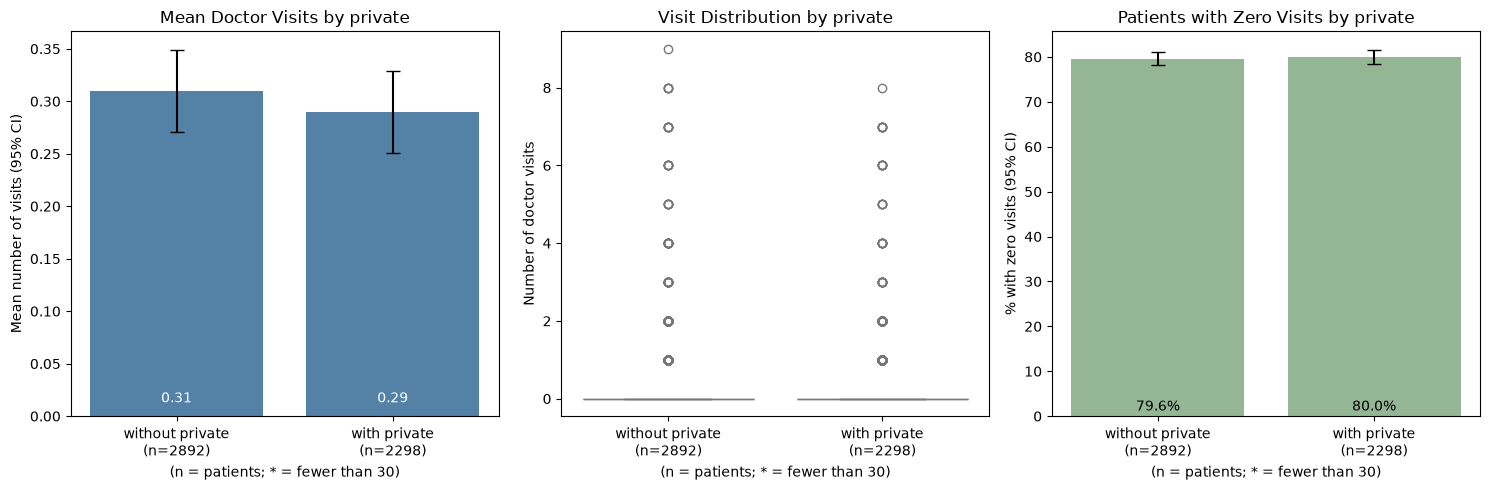

Assumption checks (visit counts are discrete and usually skewed, so rank-based tests are primary)
  without  n=2892  skewness=  4.81   zero visits= 79.6%
  with     n=2298  skewness=  4.63   zero visits= 80.0%
  Levene test for equal spread: p = 0.566

Mann-Whitney U (with vs without): p = 0.762
Cliff's delta = -0.003 (negligible) | Cohen's d = -0.016 (negligible)
Mean difference (with - without) = -0.013, 95% CI [-0.056, 0.031]
Welch t-test (sensitivity check): p = 0.564

Zero visits: 80.0% (with) vs 79.6% (without) -> Chi-square test: p = 0.756
Difference = +0.3 percentage points, 95% CI [-1.8, +2.5]; odds ratio = 1.02

Interpretation - private
- Documented meaning: (not entered - see Step 2)
- Mean visits: 0.29 (with, n=2298) vs 0.31 (without, n=2892); medians 0 vs 0.
- Mann-Whitney p = 0.762: no statistically significant difference. Cliff's delta = -0.00 (negligible); mean difference -0.01 (95% CI -0.06 to +0.03).
- The Welch t-test agrees (p = 0.564).
- Share with zero visits does

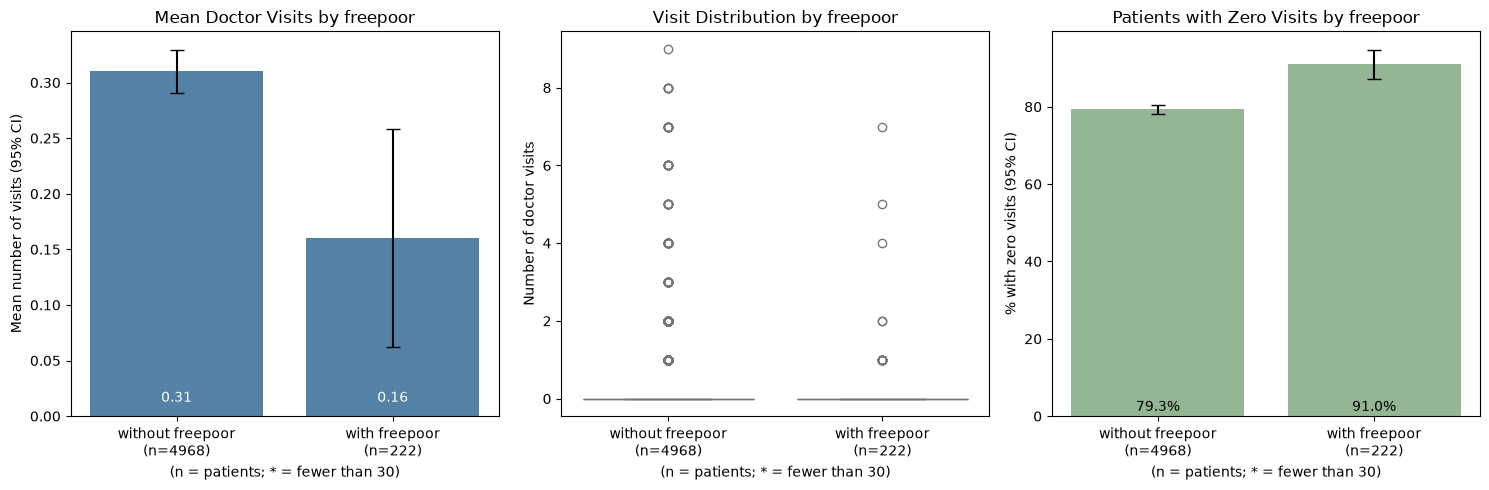

Assumption checks (visit counts are discrete and usually skewed, so rank-based tests are primary)
  without  n=4968  skewness=  4.68   zero visits= 79.3%
  with     n=222   skewness=  6.84   zero visits= 91.0%
  Levene test for equal spread: p = 0.006

Mann-Whitney U (with vs without): p < 0.001
Cliff's delta = -0.117 (negligible) | Cohen's d = -0.200 (small)
Mean difference (with - without) = -0.151, 95% CI [-0.245, -0.056]
Welch t-test (sensitivity check): p = 0.002

Zero visits: 91.0% (with) vs 79.3% (without) -> Chi-square test: p < 0.001
Difference = +11.7 percentage points, 95% CI [+7.8, +15.6]; odds ratio = 2.64

Interpretation - freepoor
- Documented meaning: (not entered - see Step 2)
- Mean visits: 0.16 (with, n=222) vs 0.31 (without, n=4968); medians 0 vs 0.
- Mann-Whitney p < 0.001: a statistically significant difference. Cliff's delta = -0.12 (negligible); mean difference -0.15 (95% CI -0.25 to -0.06).
- The Welch t-test agrees (p = 0.002).
- Share with zero visits differs

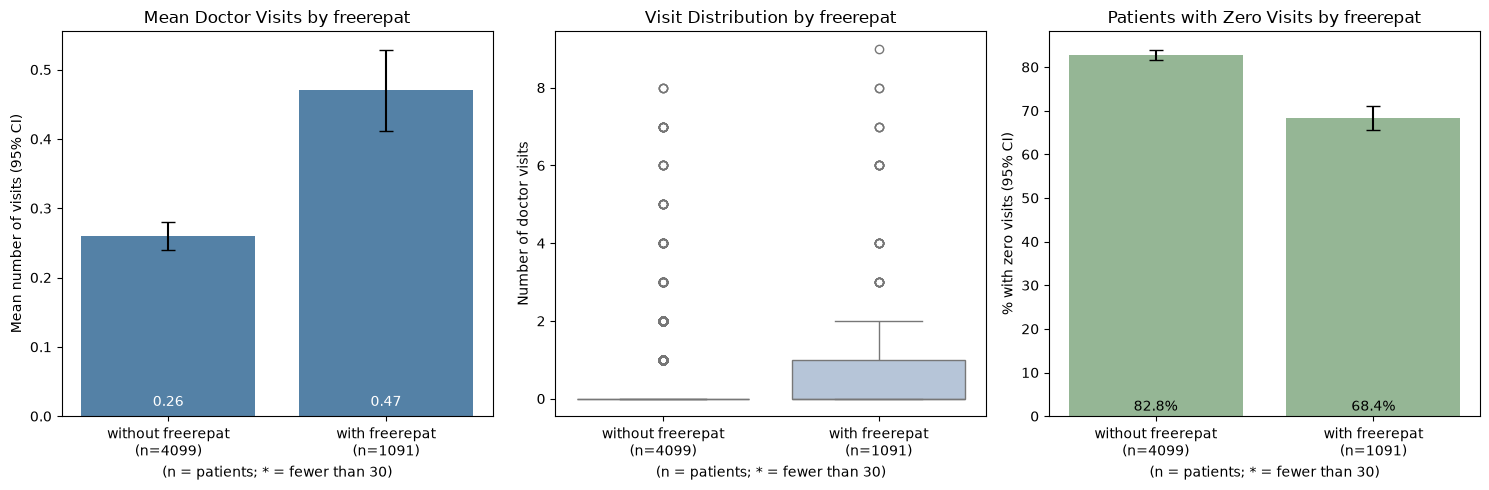

Assumption checks (visit counts are discrete and usually skewed, so rank-based tests are primary)
  without  n=4099  skewness=  4.98   zero visits= 82.8%
  with     n=1091  skewness=  4.07   zero visits= 68.4%
  Levene test for equal spread: p < 0.001

Mann-Whitney U (with vs without): p < 0.001
Cliff's delta = 0.144 (negligible) | Cohen's d = 0.243 (small)
Mean difference (with - without) = 0.209, 95% CI [0.147, 0.270]
Welch t-test (sensitivity check): p < 0.001

Zero visits: 68.4% (with) vs 82.8% (without) -> Chi-square test: p < 0.001
Difference = -14.4 percentage points, 95% CI [-17.4, -11.5]; odds ratio = 0.45

Interpretation - freerepat
- Documented meaning: (not entered - see Step 2)
- Mean visits: 0.47 (with, n=1091) vs 0.26 (without, n=4099); medians 0 vs 0.
- Mann-Whitney p < 0.001: a statistically significant difference. Cliff's delta = 0.14 (negligible); mean difference +0.21 (95% CI +0.15 to +0.27).
- The Welch t-test agrees (p < 0.001).
- Share with zero visits differs si

In [18]:

# Health insurance and doctor visits
# Compare visit frequency across `private`, `freepoor`, and `freerepat`.
# Each indicator is analysed separately. The indicators are NOT assumed to be mutually exclusive:
# Check their overlap before interpreting the results.
# These results describe associations; they don't establish cause and effect.

import glob
from itertools import combinations

INS_COLS = ["private", "freepoor", "freerepat"]
VISITS_COL = "visits"

MIN_N = 30        # groups smaller than this are flagged as "small" (unstable estimates)
MIN_TEST_N = 5    # groups smaller than this are not tested
ALPHA = 0.05

# Your notebook already has an insurance coverage percentage analysis. A compact count/percent table is
# still printed in Step 3 because the requirements ask for it and group sizes are needed as context.
# Set this to False to skip it.
SHOW_COVERAGE_TABLE = True

# %% Step 1: Check the columns and their recorded values
print("All columns:", list(df.columns))
for col in INS_COLS + [VISITS_COL]:
    if col not in df.columns:
        raise KeyError(f"Column '{col}' not found. Choose from: {list(df.columns)}")

for col in INS_COLS:
    print(f"\n--- {col} ---")
    print("dtype:", df[col].dtype)
    print(df[col].value_counts(dropna=False))

doc_hits = [f for pattern in ("*readme*", "*dictionary*", "*codebook*", "*description*", "*metadata*")
            for f in glob.glob(pattern) + glob.glob(pattern.upper())]
print("\nPossible documentation files in the working folder:", sorted(set(doc_hits)) or "none found")
print("df.attrs (metadata stored with the DataFrame):", df.attrs or "empty")

# %% Step 2: Record the documented meanings, then define helper functions
# Fill these in from your data dictionary or notebook. The code doesn't guess what they mean;
# the text is only used in the printed interpretation.
DEFINITIONS = {
    "private":   "",   # <- documented meaning of private
    "freepoor":  "",   # <- documented meaning of freepoor
    "freerepat": "",   # <- documented meaning of freerepat
}

# Which value means the indicator is present? None = auto-detect ('yes', or '1' for a 0/1 column).
POSITIVE_VALUES = {"private": None, "freepoor": None, "freerepat": None}

for col, text in DEFINITIONS.items():
    if not text.strip():
        print(f"WARNING: no documented definition entered for '{col}'. Interpretation will describe "
              "data patterns only; confirm what the variable means before drawing conclusions.")


def ins_to_category(series):
    """Convert a column to clean text categories: 1.0 -> '1', ' Yes' -> 'yes'. Missing stays missing."""
    s = series.copy()
    if pd.api.types.is_bool_dtype(s):
        s = s.astype(int)
    num = pd.to_numeric(s, errors="coerce")
    if num.notna().sum() == s.notna().sum():
        s = num.map(lambda v: np.nan if pd.isna(v) else (str(int(v)) if float(v).is_integer() else str(v)))
    else:
        s = s.astype("string").str.strip().str.lower()
    return s.astype(object)


def ins_positive_value(col):
    """Return the value meaning 'present' for a two-value indicator, or None if it can't be determined."""
    cats = set(ins_to_category(df[col]).dropna().unique())
    override = POSITIVE_VALUES.get(col)
    if override is not None:
        return str(override).lower(), cats
    if len(cats) == 2 and "yes" in cats:
        return "yes", cats
    if cats == {"0", "1"}:
        print(f"Note: '{col}' is coded 0/1; treating '1' as 'present'. "
              "Confirm against your documentation (or set POSITIVE_VALUES).")
        return "1", cats
    return None, cats


def fmt_p(p):
    return "< 0.001" if p < 0.001 else f"= {p:.3f}"


def size_label(value, kind):
    """Rule-of-thumb wording for effect sizes (guidelines, not strict cut-offs)."""
    v = abs(value)
    cuts = {"delta": (0.147, 0.33, 0.474), "d": (0.2, 0.5, 0.8)}[kind]
    return "negligible" if v < cuts[0] else "small" if v < cuts[1] else "medium" if v < cuts[2] else "large"


POSITIVE = {}
for col in INS_COLS:
    pos, cats = ins_positive_value(col)
    if pos is None or len(cats) != 2:
        print(f"'{col}' is not a two-value indicator with a known 'present' value "
              f"(categories found: {sorted(cats)}). It will be skipped; set POSITIVE_VALUES if needed.")
    else:
        POSITIVE[col] = pos
print("\nValue treated as 'present':", POSITIVE)

# %% Step 3: Counts and percentages for each indicator + overlap check
if SHOW_COVERAGE_TABLE:
    rows = []
    for col, pos in POSITIVE.items():
        cat = ins_to_category(df[col])
        n_present, n_absent, n_missing = int((cat == pos).sum()), int(((cat != pos) & cat.notna()).sum()), int(cat.isna().sum())
        n_valid = n_present + n_absent
        rows.append({"indicator": col, "present": n_present, "absent": n_absent, "missing": n_missing,
                     "% present (of non-missing)": round(n_present / n_valid * 100, 1) if n_valid else np.nan})
    print("Patient counts and percentages per indicator")
    print(pd.DataFrame(rows).to_string(index=False))

# Overlap: the indicators are NOT assumed to be exclusive, so count each combination of coverage.
flags = pd.DataFrame({c: ins_to_category(df[c]) == POSITIVE[c] for c in POSITIVE})
valid_rows = pd.concat([ins_to_category(df[c]) for c in POSITIVE], axis=1).notna().all(axis=1)
flags = flags[valid_rows]
print(f"\nOverlap check uses {len(flags)} of {len(df)} rows with all indicators recorded.")

n_present_per_patient = flags.sum(axis=1)
overlap_exists = bool((n_present_per_patient >= 2).any())
print("Number of indicators present per patient:")
print(n_present_per_patient.value_counts().sort_index().rename("patients").to_frame()
      .assign(percent=lambda t: (t["patients"] / t["patients"].sum() * 100).round(1)))
print("\nOverlap between indicators exists:", overlap_exists,
      "| patients with no indicator present:", int((n_present_per_patient == 0).sum()))

# %% Step 4: Helper functions for the group comparisons
def ins_prepare(col):
    """Clean table for one indicator: group 'with' (present) vs 'without' (absent), plus visits."""
    d = pd.DataFrame({"flag": ins_to_category(df[col]),
                      "visits": pd.to_numeric(df[VISITS_COL], errors="coerce")})
    n_before = len(d)
    d = d.dropna()                                       # missing indicator or visits -> cannot be compared
    n_negative = int((d["visits"] < 0).sum())
    d = d[d["visits"] >= 0]                              # visit counts cannot be negative
    d["group"] = np.where(d["flag"] == POSITIVE[col], "with", "without")
    print(f"[{col}] rows: {n_before} | used: {len(d)} | removed for missing values: "
          f"{n_before - len(d) - n_negative} | removed for negative visits: {n_negative}")
    return d


def ins_summarise(d, order=("without", "with")):
    s = d.groupby("group")["visits"].agg(
        patients="count", mean_visits="mean", median_visits="median", std_visits="std").reindex(list(order))
    zero = d.groupby("group")["visits"].apply(lambda x: (x == 0).mean() * 100).reindex(list(order))
    s["pct_zero_visits"] = zero
    s["se_mean"] = s["std_visits"] / np.sqrt(s["patients"])
    s["small_group"] = s["patients"] < MIN_N
    return s.round(2)


def ins_compare_visits(d):
    """Mann-Whitney U (primary), Welch t-test (sensitivity), with effect sizes."""
    x, y = d.loc[d["group"] == "with", "visits"].to_numpy(), d.loc[d["group"] == "without", "visits"].to_numpy()
    if min(len(x), len(y)) < MIN_TEST_N:
        print(f"A group has fewer than {MIN_TEST_N} patients, so no test is run.")
        return None
    print("Assumption checks (visit counts are discrete and usually skewed, so rank-based tests are primary)")
    for name, v in (("without", y), ("with", x)):
        print(f"  {name:<8} n={len(v):<5} skewness={stats.skew(v):6.2f}   zero visits={np.mean(v == 0) * 100:5.1f}%")
    print(f"  Levene test for equal spread: p {fmt_p(stats.levene(x, y, center='median').pvalue)}")

    u = stats.mannwhitneyu(x, y, alternative="two-sided")
    cl = u.statistic / (len(x) * len(y))                 # P(random 'with' patient has more visits), ties half
    delta = 2 * cl - 1                                   # Cliff's delta
    welch = stats.ttest_ind(x, y, equal_var=False)
    diff = x.mean() - y.mean()
    v1, v2 = x.var(ddof=1) / len(x), y.var(ddof=1) / len(y)
    dof = (v1 + v2) ** 2 / (v1 ** 2 / (len(x) - 1) + v2 ** 2 / (len(y) - 1))
    half = stats.t.ppf(0.975, dof) * np.sqrt(v1 + v2)
    cohen_d = diff / np.sqrt((x.var(ddof=1) + y.var(ddof=1)) / 2)
    res = dict(p=u.pvalue, cl=cl, delta=delta, welch_p=welch.pvalue, diff=diff,
               ci=(diff - half, diff + half), cohen_d=cohen_d)
    print(f"\nMann-Whitney U (with vs without): p {fmt_p(u.pvalue)}")
    print(f"Cliff's delta = {delta:.3f} ({size_label(delta, 'delta')}) | "
          f"Cohen's d = {cohen_d:.3f} ({size_label(cohen_d, 'd')})")
    print(f"Mean difference (with - without) = {diff:.3f}, 95% CI [{res['ci'][0]:.3f}, {res['ci'][1]:.3f}]")
    print(f"Welch t-test (sensitivity check): p {fmt_p(welch.pvalue)}")
    return res


def ins_compare_zero(d):
    """Compare the proportion of patients with zero visits (chi-square, or Fisher if counts are small)."""
    n1, n0 = int((d["group"] == "with").sum()), int((d["group"] == "without").sum())
    z1 = int(((d["group"] == "with") & (d["visits"] == 0)).sum())
    z0 = int(((d["group"] == "without") & (d["visits"] == 0)).sum())
    if z0 + z1 == 0 or z0 + z1 == n0 + n1 or min(n0, n1) < MIN_TEST_N:
        print("Zero-visit comparison skipped (no variation in zero/non-zero status, or a group is too small).")
        return None
    table = [[z1, n1 - z1], [z0, n0 - z0]]               # rows: with / without; columns: zero / non-zero
    chi2, p_chi, _, expected = stats.chi2_contingency(table, correction=False)
    if expected.min() < 5:
        odds, p = stats.fisher_exact(table)
        test = "Fisher exact test (small expected counts)"
    else:
        p = p_chi
        odds = (z1 * (n0 - z0)) / ((n1 - z1) * z0) if (n1 - z1) * z0 > 0 else np.inf
        test = "Chi-square test"
    p1, p0 = z1 / n1, z0 / n0
    se = np.sqrt(p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0)
    diff = p1 - p0
    res = dict(test=test, p=p, odds=odds, diff_pp=diff * 100, ci_pp=((diff - 1.96 * se) * 100, (diff + 1.96 * se) * 100))
    print(f"Zero visits: {p1 * 100:.1f}% (with) vs {p0 * 100:.1f}% (without) -> {test}: p {fmt_p(p)}")
    print(f"Difference = {res['diff_pp']:+.1f} percentage points, 95% CI [{res['ci_pp'][0]:+.1f}, {res['ci_pp'][1]:+.1f}]; "
          f"odds ratio = {odds:.2f}")
    return res


def ins_plot(d, s, col, show_zero):
    """Mean visits (95% CI), boxplot, and (if zeros exist) % with zero visits (95% CI)."""
    order = ["without", "with"]
    labels = {g: f"{g} {col}\n(n={int(s.loc[g, 'patients'])}){'*' if s.loc[g, 'small_group'] else ''}" for g in order}
    label_order = [labels[g] for g in order]
    plot_d = d.assign(label=d["group"].map(labels))
    ncols = 3 if show_zero else 2
    fig, axes = plt.subplots(1, ncols, figsize=(5 * ncols, 5))

    sns.barplot(x=label_order, y=s["mean_visits"].to_numpy(), order=label_order, color="steelblue", ax=axes[0])
    axes[0].errorbar(range(2), s["mean_visits"], yerr=1.96 * s["se_mean"].fillna(0),
                     fmt="none", ecolor="black", capsize=5)
    for i, v in enumerate(s["mean_visits"]):
        axes[0].text(i, 0.01, f"{v:.2f}", ha="center", va="bottom", color="white", fontsize=10)
    axes[0].set_title(f"Mean Doctor Visits by {col}")
    axes[0].set_ylabel("Mean number of visits (95% CI)")

    sns.boxplot(data=plot_d, x="label", y="visits", order=label_order, color="lightsteelblue", ax=axes[1])
    axes[1].set_title(f"Visit Distribution by {col}")
    axes[1].set_ylabel("Number of doctor visits")

    if show_zero:
        pct = s["pct_zero_visits"].to_numpy()
        n = s["patients"].to_numpy()
        se_pct = np.sqrt((pct / 100) * (1 - pct / 100) / n) * 100
        sns.barplot(x=label_order, y=pct, order=label_order, color="darkseagreen", ax=axes[2])
        axes[2].errorbar(range(2), pct, yerr=1.96 * se_pct, fmt="none", ecolor="black", capsize=5)
        for i, v in enumerate(pct):
            axes[2].text(i, 0.5, f"{v:.1f}%", ha="center", va="bottom", fontsize=10)
        axes[2].set_title(f"Patients with Zero Visits by {col}")
        axes[2].set_ylabel("% with zero visits (95% CI)")

    for ax in axes:
        ax.set_xlabel(f"(n = patients; * = fewer than {MIN_N})")
    plt.tight_layout()
    plt.show()


def ins_interpret(col, s, rv, rz):
    print(f"\nInterpretation - {col}")
    print(f"- Documented meaning: {DEFINITIONS[col] or '(not entered - see Step 2)'}")
    print(f"- Mean visits: {s.loc['with', 'mean_visits']:.2f} (with, n={int(s.loc['with', 'patients'])}) vs "
          f"{s.loc['without', 'mean_visits']:.2f} (without, n={int(s.loc['without', 'patients'])}); "
          f"medians {s.loc['with', 'median_visits']:.0f} vs {s.loc['without', 'median_visits']:.0f}.")
    if rv:
        sig = "a statistically significant" if rv["p"] < ALPHA else "no statistically significant"
        print(f"- Mann-Whitney p {fmt_p(rv['p'])}: {sig} difference. Cliff's delta = {rv['delta']:.2f} "
              f"({size_label(rv['delta'], 'delta')}); mean difference {rv['diff']:+.2f} "
              f"(95% CI {rv['ci'][0]:+.2f} to {rv['ci'][1]:+.2f}).")
        agree = (rv["p"] < ALPHA) == (rv["welch_p"] < ALPHA)
        print(f"- The Welch t-test {'agrees' if agree else 'does not agree'} (p {fmt_p(rv['welch_p'])}).")
    if rz:
        sig = "differs significantly" if rz["p"] < ALPHA else "does not differ significantly"
        print(f"- Share with zero visits {sig} (p {fmt_p(rz['p'])}): {rz['diff_pp']:+.1f} percentage points, "
              f"odds ratio {rz['odds']:.2f}.")
    if s["small_group"].any():
        print(f"- Small group warning (fewer than {MIN_N} patients): {list(s.index[s['small_group']])}.")
    print("- This is an association only; it does not show that coverage changes how often people see a doctor.")


# Do zero visits occur at all?
zero_visits_occur = bool((pd.to_numeric(df[VISITS_COL], errors="coerce") == 0).any())
print("Zero visits occur in the dataset:", zero_visits_occur)

# %% Step 5: Analyse each indicator separately
results = {}
for col in POSITIVE:
    print("\n" + "=" * 70)
    print(f"{col.upper()}: patients WITH vs WITHOUT")
    print("=" * 70)
    d = ins_prepare(col)
    if d["group"].nunique() < 2:
        print("Only one group present after cleaning; nothing to compare.")
        continue
    s = ins_summarise(d)
    print(f"\nDoctor visits by {col} (small_group = fewer than {MIN_N} patients)")
    print(s[["patients", "mean_visits", "median_visits", "std_visits", "pct_zero_visits", "small_group"]])
    ins_plot(d, s, col, zero_visits_occur)
    rv = ins_compare_visits(d)
    print()
    rz = ins_compare_zero(d) if zero_visits_occur else None
    ins_interpret(col, s, rv, rz)
    results[col] = dict(summary=s, visits=rv, zero=rz)

# %% Step 6: Side-by-side summary (Bonferroni-adjusted across the indicators tested)
rows = []
k = len(results)                                         # number of indicators tested
for col, r in results.items():
    s, rv, rz = r["summary"], r["visits"], r["zero"]
    rows.append({
        "indicator": col,
        "n_with": int(s.loc["with", "patients"]), "n_without": int(s.loc["without", "patients"]),
        "mean_with": s.loc["with", "mean_visits"], "mean_without": s.loc["without", "mean_visits"],
        "mean_diff": round(rv["diff"], 3) if rv else np.nan,
        "p_visits": rv["p"] if rv else np.nan,
        "p_visits_bonf": min(1, rv["p"] * k) if rv else np.nan,
        "cliffs_delta": round(rv["delta"], 3) if rv else np.nan,
        "pct_zero_with": s.loc["with", "pct_zero_visits"], "pct_zero_without": s.loc["without", "pct_zero_visits"],
        "p_zero": rz["p"] if rz else np.nan,
    })
overview = pd.DataFrame(rows)
for c in ("p_visits", "p_visits_bonf", "p_zero"):
    overview[c] = overview[c].round(4)
print(f"Overview of all indicators (Bonferroni adjustment uses k = {k})")
print(overview.to_string(index=False))

# %% Step 7: Descriptive look at overlapping coverage (no tests - groups would be too fragmented)
combo = pd.DataFrame({c: ins_to_category(df[c]) for c in POSITIVE})
combo["visits"] = pd.to_numeric(df[VISITS_COL], errors="coerce")
combo = combo.dropna()
combo = combo[combo["visits"] >= 0]
present_names = pd.DataFrame({c: np.where(combo[c] == POSITIVE[c], c, "") for c in POSITIVE}, index=combo.index)
combo["pattern"] = present_names.apply(lambda r: " + ".join([x for x in r if x]) or "none of the three", axis=1)

pattern_summary = (combo.groupby("pattern")["visits"]
                   .agg(patients="count", mean_visits="mean", median_visits="median", std_visits="std")
                   .assign(pct_zero_visits=combo.groupby("pattern")["visits"].apply(lambda x: (x == 0).mean() * 100))
                   .round(2).sort_values("patients", ascending=False))
pattern_summary["small_group"] = pattern_summary["patients"] < MIN_N
print(f"Visits by combination of coverage indicators ({len(combo)} complete cases; descriptive only)")
print(pattern_summary)
if overlap_exists:
    print("\nBecause some patients have more than one indicator, the 'without' group in each comparison above "
          "mixes patients with other kinds of coverage, and the three comparisons are not independent of each other.")
else:
    print("\nNo patient has more than one indicator present in the complete cases.")

# %% Step 8: Overall interpretation and limitations
print("Overall interpretation (from the results above)")
print("-" * 46)
for col, r in results.items():
    rv = r["visits"]
    if rv is None:
        print(f"- {col}: no visit-count test could be run.")
        continue
    direction = "higher" if rv["diff"] > 0 else "lower" if rv["diff"] < 0 else "equal"
    sig = "significant" if rv["p"] < ALPHA else "not significant"
    sig_adj = "still significant" if min(1, rv["p"] * k) < ALPHA else "not significant"
    print(f"- {col}: mean visits {direction} among patients with it ({rv['diff']:+.2f}); "
          f"raw p {fmt_p(rv['p'])} ({sig}), {sig_adj} after Bonferroni; "
          f"Cliff's delta {rv['delta']:.2f} ({size_label(rv['delta'], 'delta')}).")

print("\nLimitations")
print("-" * 11)
print("- Association only: observational data cannot show that insurance status causes more or fewer visits.")
print("  People with different coverage differ in age, income, health and access, none of which are adjusted for here.")
print("- Overlap: the indicators are not assumed to be exclusive. Where they overlap, each 'without' group is a mix of")
print("  other coverage types, so these comparisons are NOT the same as comparing one insurance type with another.")
print("- Definitions: conclusions depend on the documented meaning of each indicator (see Step 2).")
print("- Missing values: rows missing an indicator or visits were dropped per analysis, so sample sizes differ slightly.")
print("- Visit counts are skewed with many zeros; rank-based tests compare whole distributions, not just medians.")
print("- Three indicators were each tested on two outcomes; Bonferroni adjusts the visit-count tests only.")
print("- Statistical significance is not practical importance: check the effect sizes, confidence intervals and group sizes.")

## 16. Does the income–visit pattern differ by age and gender?

All columns: ['Unnamed: 0', 'visits', 'gender', 'age', 'income', 'illness', 'reduced', 'health', 'private', 'freepoor', 'freerepat', 'nchronic', 'lchronic']

--- income --- dtype: float64 | missing: 0

--- age --- dtype: float64 | missing: 0

--- gender --- dtype: str | missing: 0

--- visits --- dtype: int64 | missing: 0

Income summary:
count    5190.000
mean        0.583
std         0.369
min         0.000
25%         0.250
50%         0.550
75%         0.900
max         1.500
Name: income, dtype: float64
Negative values: 0 | zeros: 79 | distinct values: 14 | skewness: 0.73
Income units are not stored in the data. This code uses the values exactly as they are.

Age summary:
count    5190.000
mean        0.406
std         0.205
min         0.190
25%         0.220
50%         0.320
75%         0.620
max         0.720
Name: age, dtype: float64
Max age = 0.72 (<= 1.5): looks like 'years divided by 100'. Will multiply by 100.

Gender categories:
gender
female    2702
male      2488
Name:

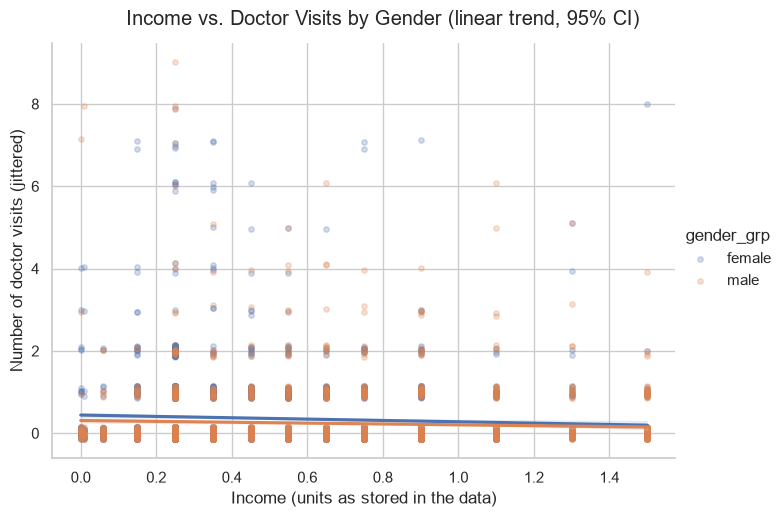

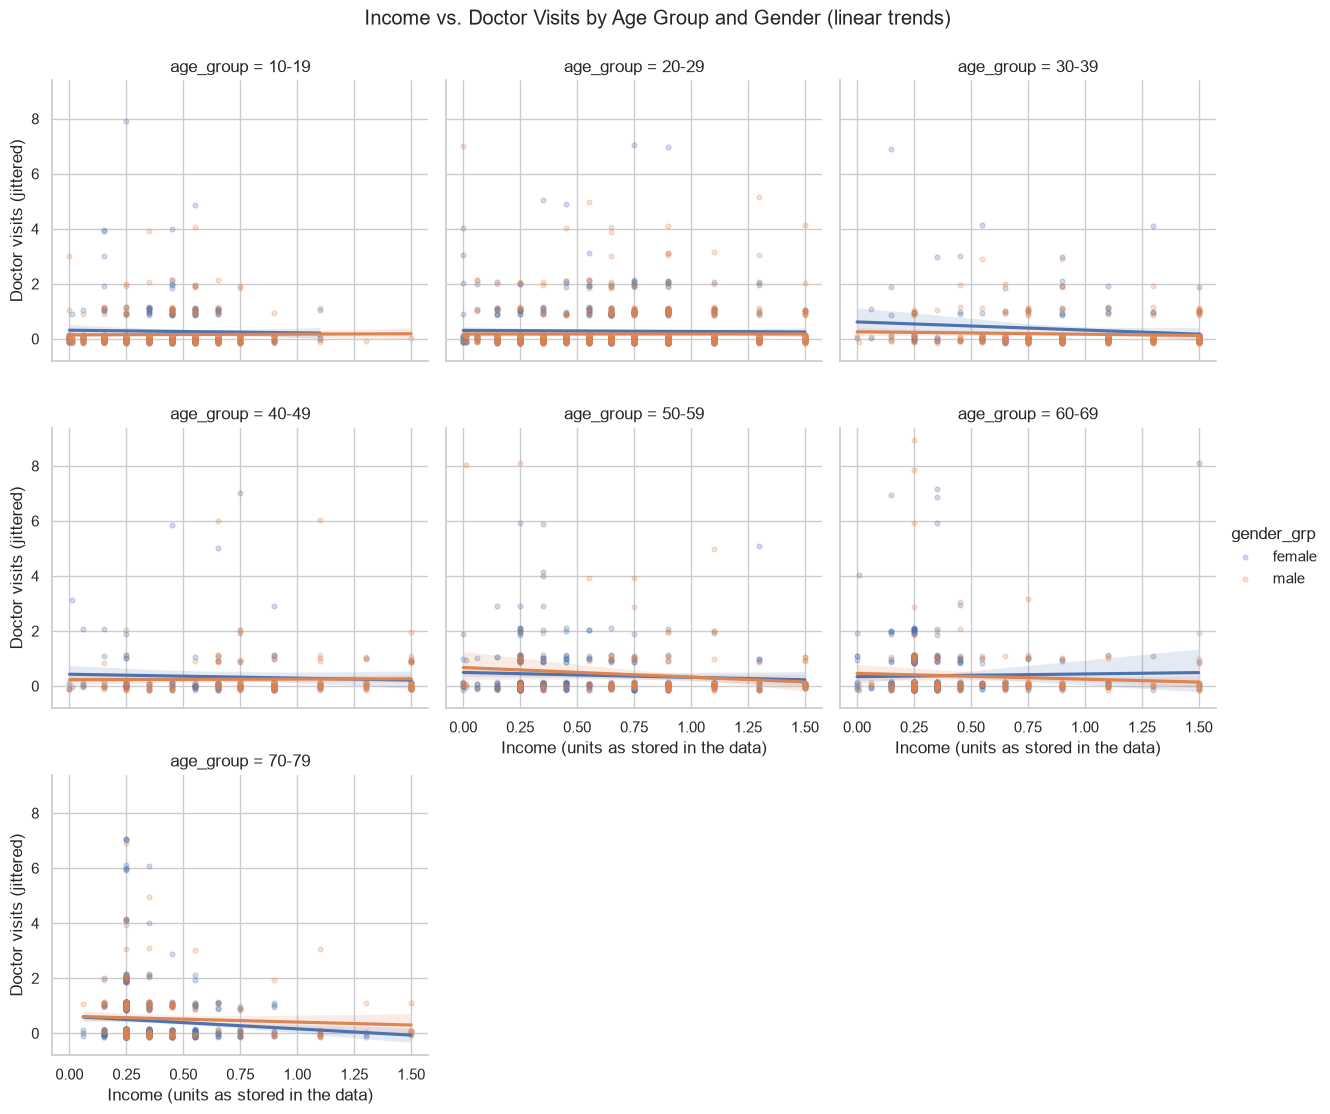

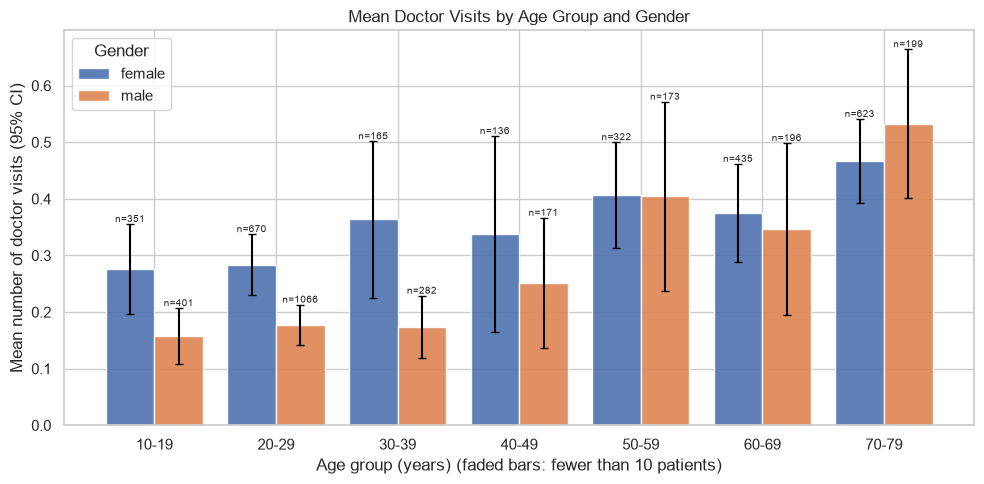

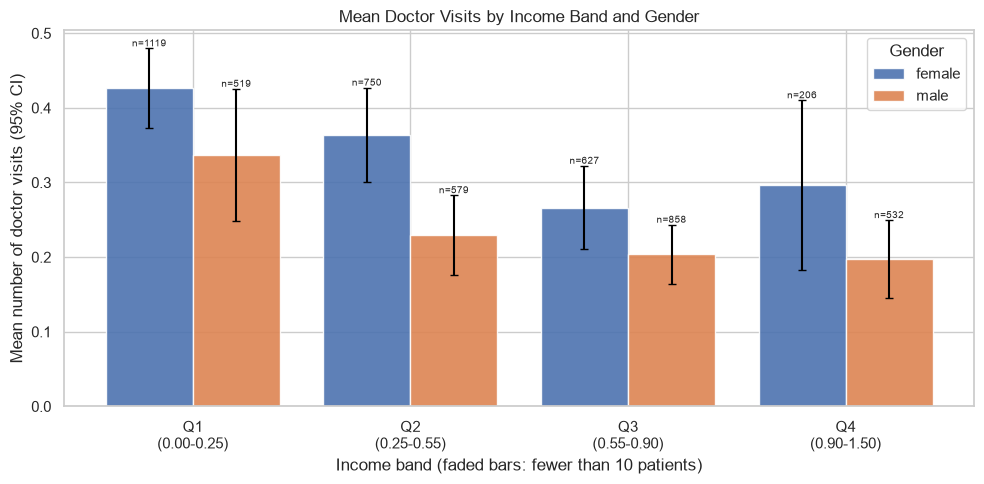

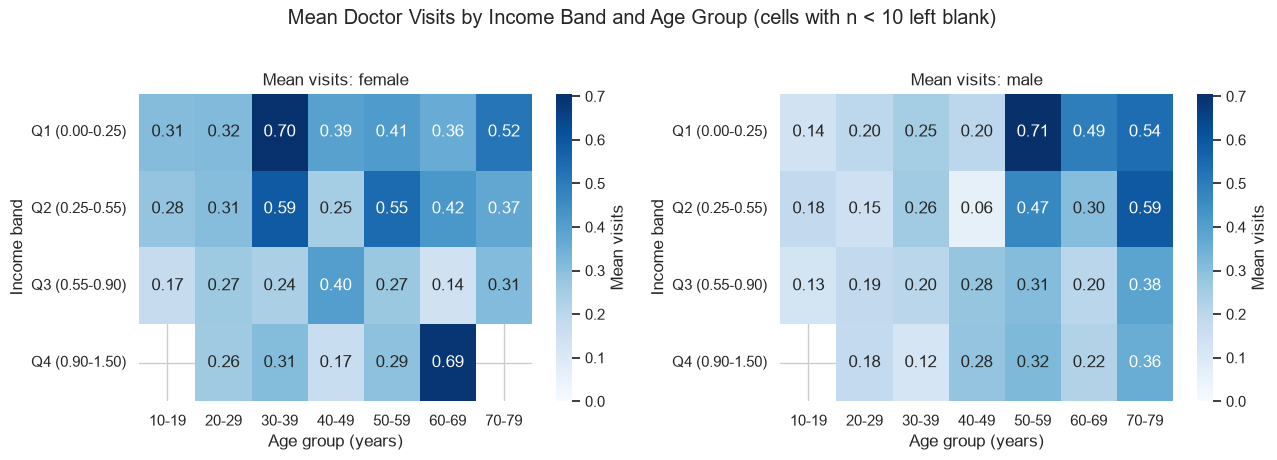

MODEL 1 - main effects only (rate ratios, robust SEs)
                       rate_ratio  ci_low  ci_high  p_value
Intercept                  0.3142  0.2830   0.3488   0.0000
C(gender_grp)[T.male]      0.8060  0.6793   0.9563   0.0134
income_z                   0.9028  0.8242   0.9889   0.0277
age10_c                    1.1318  1.0909   1.1742   0.0000

MODEL 2 - with income x gender and income x age interactions
                                rate_ratio  ci_low  ci_high  p_value
Intercept                           0.3152  0.2813   0.3531   0.0000
C(gender_grp)[T.male]               0.8007  0.6781   0.9454   0.0087
income_z                            0.9441  0.8256   1.0797   0.4010
income_z:C(gender_grp)[T.male]      0.9217  0.7702   1.1030   0.3735
age10_c                             1.1264  1.0804   1.1744   0.0000
income_z:age10_c                    0.9812  0.9325   1.0325   0.4654

Interaction terms in Model 2 (a rate ratio different from 1 means the income effect changes):
      

In [19]:
# Does the income–visit relationship vary by age and gender?
# Compare the income–visit pattern across age groups
# and gender, using summaries first and then a regression model with interaction terms.
# This is an observational analysis: it shows statistical associations, not causes.

import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats

sns.set_theme(style="whitegrid")

INCOME_COL, AGE_COL, GENDER_COL, VISITS_COL = "income", "age", "gender", "visits"
INCOME_LABEL = "Income (units as stored in the data)"   # edit once you know the units from your documentation
AGE_BIN_WIDTH = 10        # width of age groups in years
N_INCOME_BANDS = 4        # income quartiles (fewer if the data cannot support them)
MIN_N = 30                # groups smaller than this are flagged as small / not tested
MIN_CELL = 10             # cells smaller than this are hidden in the charts
ALPHA = 0.05
GENDER_LABELS = None      # optional, e.g. {"0": "Female", "1": "Male"} once confirmed in your documentation

# %% Step 1: Inspect the four columns and verify their encodings
print("All columns:", list(df.columns))
for col in (INCOME_COL, AGE_COL, GENDER_COL, VISITS_COL):
    if col not in df.columns:
        raise KeyError(f"Column '{col}' not found. Choose from: {list(df.columns)}")
    print(f"\n--- {col} --- dtype: {df[col].dtype} | missing: {df[col].isna().sum()}")

# income: numeric? negative? how skewed?
income_num = pd.to_numeric(df[INCOME_COL], errors="coerce")
print("\nIncome summary:")
print(income_num.describe().round(3))
print(f"Negative values: {(income_num < 0).sum()} | zeros: {(income_num == 0).sum()} | "
      f"distinct values: {income_num.nunique()} | skewness: {income_num.skew():.2f}")
print("Income units are not stored in the data. This code uses the values exactly as they are.")

# age: verify the scale before converting (same logic as the age-group section)
age_num = pd.to_numeric(df[AGE_COL], errors="coerce")
print("\nAge summary:")
print(age_num.describe().round(3))
age_min, age_max = age_num.min(), age_num.max()
if age_min < 0:
    raise ValueError("Negative ages found - clean the data first.")
elif age_max <= 1.5:
    AGE_SCALE = 100
    print(f"Max age = {age_max:.2f} (<= 1.5): looks like 'years divided by 100'. Will multiply by 100.")
elif age_max <= 120:
    AGE_SCALE = 1
    print(f"Max age = {age_max:.1f}: values already look like years.")
else:
    raise ValueError(f"Max age = {age_max}: not plausible as years or years/100. Check your data dictionary.")

# gender: which categories exist?
print("\nGender categories:")
print(df[GENDER_COL].value_counts(dropna=False))
print("Confirm in your documentation what each category means (set GENDER_LABELS if the values are 0/1).")

# visits: should be non-negative whole numbers (a count)
visits_num = pd.to_numeric(df[VISITS_COL], errors="coerce")
visits_ok = bool((visits_num.dropna() % 1 == 0).all() and visits_num.min() >= 0)
print(f"\nVisits: min {visits_num.min()}, max {visits_num.max()}, "
      f"zeros {(visits_num == 0).mean() * 100:.1f}% | non-negative whole numbers: {visits_ok}")
if not visits_ok:
    raise ValueError("'visits' does not look like a count; the models below assume counts.")

# %% Step 2: Clean ONLY the relevant columns and report missing values
def to_category(series):
    """Clean text categories: 1.0 -> '1', ' Male' -> 'male'. Missing stays missing."""
    s = series.copy()
    if pd.api.types.is_bool_dtype(s):
        s = s.astype(int)
    num = pd.to_numeric(s, errors="coerce")
    if num.notna().sum() == s.notna().sum():
        s = num.map(lambda v: np.nan if pd.isna(v) else (str(int(v)) if float(v).is_integer() else str(v)))
    else:
        s = s.astype("string").str.strip().str.lower()
    return s.astype(object)

raw = pd.DataFrame({
    "income": income_num, "age_raw": age_num,
    "gender_cat": to_category(df[GENDER_COL]), "visits": visits_num})

missing_table = pd.DataFrame({"missing": raw.isna().sum(), "percent": (raw.isna().mean() * 100).round(2)})
print("Missing values in the relevant columns:")
print(missing_table)

n_before = len(raw)
dat = raw.dropna().copy()                    # complete cases only; the original df is not changed
n_missing_removed = n_before - len(dat)
dat = dat[dat["visits"] >= 0]                # visit counts cannot be negative
print(f"\nRows before: {n_before} | removed for missing values: {n_missing_removed} | "
      f"removed for negative visits: {n_before - n_missing_removed - len(dat)} | rows used: {len(dat)}")
if (dat["income"] < 0).any():
    print(f"Warning: {(dat['income'] < 0).sum()} negative income value(s) kept - check whether they are valid.")
if dat["income"].nunique() < 2:
    raise ValueError("Income has no variation after cleaning.")

# Age in years + age groups based on the verified scale
dat["age_years"] = (dat["age_raw"] * AGE_SCALE).round(1)
lower = int(np.floor(dat["age_years"].min() / AGE_BIN_WIDTH) * AGE_BIN_WIDTH)
upper = int(np.floor(dat["age_years"].max() / AGE_BIN_WIDTH) * AGE_BIN_WIDTH) + AGE_BIN_WIDTH
edges = list(range(lower, upper + 1, AGE_BIN_WIDTH))
age_labels = [f"{a}-{a + AGE_BIN_WIDTH - 1}" for a in edges[:-1]]
dat["age_group"] = pd.cut(dat["age_years"], bins=edges, labels=age_labels, right=False)
age_order = [g for g in age_labels if (dat["age_group"] == g).any()]

# Gender labels (numeric codes are NOT interpreted unless you supply GENDER_LABELS)
gender_map = {}
for v in sorted(dat["gender_cat"].unique()):
    if GENDER_LABELS and v in GENDER_LABELS:
        gender_map[v] = GENDER_LABELS[v]
    else:
        gender_map[v] = f"{GENDER_COL}={v}" if v.lstrip("-").replace(".", "").isdigit() else v
dat["gender_grp"] = dat["gender_cat"].map(gender_map)
gender_order = list(gender_map.values())

# Income bands (quartiles of the pooled data) for the descriptive tables
if dat["income"].nunique() <= 6:
    dat["income_band"] = pd.Categorical(dat["income"].astype(str),
                                        categories=[str(v) for v in sorted(dat["income"].unique())], ordered=True)
else:
    _, bins = pd.qcut(dat["income"], N_INCOME_BANDS, retbins=True, duplicates="drop")
    band_labels = [f"Q{i + 1} ({bins[i]:.2f}-{bins[i + 1]:.2f})" for i in range(len(bins) - 1)]
    dat["income_band"] = pd.qcut(dat["income"], N_INCOME_BANDS, labels=band_labels, duplicates="drop")
band_order = list(dat["income_band"].cat.categories)

# Standardised predictors for the regression (so main effects are readable)
income_mean, income_sd = dat["income"].mean(), dat["income"].std()
age_mean = dat["age_years"].mean()
dat["income_z"] = (dat["income"] - income_mean) / income_sd     # 1 unit = 1 standard deviation of income
dat["age10_c"] = (dat["age_years"] - age_mean) / 10             # 1 unit = 10 years above the average age

print(f"\nAge range used: {dat['age_years'].min()} to {dat['age_years'].max()} years | age groups: {age_order}")
print(f"Gender groups: {gender_order}")
print(f"Income bands: {band_order}")

# %% Step 3: Summary tables (mean, median, n) across income, age group and gender
def summarise_by(keys):
    g = dat.groupby(keys, observed=True)["visits"]
    t = g.agg(patients="count", mean_visits="mean", median_visits="median", std_visits="std")
    t["pct_zero_visits"] = g.apply(lambda x: (x == 0).mean() * 100)
    t["small_group"] = t["patients"] < MIN_N
    return t.round(2)

for title, keys in [("Income band", ["income_band"]), ("Age group", ["age_group"]),
                    ("Gender", ["gender_grp"]), ("Age group x gender", ["age_group", "gender_grp"]),
                    ("Income band x gender", ["income_band", "gender_grp"])]:
    print(f"\nDoctor visits by {title} (small_group = fewer than {MIN_N} patients)")
    print(summarise_by(keys).to_string())

print("\nMean visits: income band (rows) x age group (columns)")
mean_piv = dat.pivot_table(index="income_band", columns="age_group", values="visits",
                           aggfunc="mean", observed=False).reindex(columns=age_order).round(2)
print(mean_piv.to_string())
print("\nMedian visits: income band x age group")
print(dat.pivot_table(index="income_band", columns="age_group", values="visits",
                      aggfunc="median", observed=False).reindex(columns=age_order).to_string())
print("\nPatients per cell: income band x age group")
n_piv = dat.pivot_table(index="income_band", columns="age_group", values="visits",
                        aggfunc="count", observed=False).reindex(columns=age_order).fillna(0).astype(int)
print(n_piv.to_string())

# %% Step 4: Income-visits association inside each subgroup (descriptive, before modelling)
# Spearman correlation suits skewed counts. Subgroups with fewer than MIN_N patients are skipped.
rows = []
def add_row(label, sub):
    if len(sub) < MIN_N or sub["income"].nunique() < 2 or sub["visits"].nunique() < 2:
        rows.append({"subgroup": label, "patients": len(sub), "spearman_rho": np.nan, "p_value": np.nan})
        return
    rho, p = stats.spearmanr(sub["income"], sub["visits"])
    rows.append({"subgroup": label, "patients": len(sub), "spearman_rho": rho, "p_value": p})

add_row("All patients", dat)
for gname in gender_order:
    add_row(f"gender: {gname}", dat[dat["gender_grp"] == gname])
for a in age_order:
    add_row(f"age: {a}", dat[dat["age_group"] == a])
for a in age_order:
    for gname in gender_order:
        add_row(f"age {a} | {gname}", dat[(dat["age_group"] == a) & (dat["gender_grp"] == gname)])

sub_tbl = pd.DataFrame(rows)
k_tests = int(sub_tbl["p_value"].notna().sum()) - 1        # exclude the 'All patients' row
sub_tbl["p_bonferroni"] = (sub_tbl["p_value"] * max(k_tests, 1)).clip(upper=1)
sub_tbl.loc[sub_tbl["subgroup"] == "All patients", "p_bonferroni"] = np.nan
print(f"Spearman correlation between income and visits within subgroups (Bonferroni uses k = {k_tests})")
print(sub_tbl.round(4).to_string(index=False))
print("Subgroups with NaN were skipped (too small or no variation).")

# %% Step 5: Scatterplots of income vs. visits with gender as hue
# Visit counts are whole numbers, so points sit on horizontal lines. A little vertical jitter
# (y_jitter) is added to the DOTS ONLY, so overlapping points can be seen. Trend lines use the real data.
g1 = sns.lmplot(data=dat, x="income", y="visits", hue="gender_grp", hue_order=gender_order,
                height=5, aspect=1.4, y_jitter=0.15, ci=95, scatter_kws={"alpha": 0.25, "s": 15})
g1.set_axis_labels(INCOME_LABEL, "Number of doctor visits (jittered)")
g1.fig.suptitle("Income vs. Doctor Visits by Gender (linear trend, 95% CI)", y=1.03)
plt.show()

# Same plot split by age group (this is the meaningful comparison: does the slope change with age?)
cell_n = dat.groupby(["age_group", "gender_grp"], observed=True)["visits"].transform("count")
plot_dat = dat[cell_n >= MIN_CELL].copy()
hidden = sorted(set(map(tuple, dat.loc[cell_n < MIN_CELL, ["age_group", "gender_grp"]].astype(str).values)))
if hidden:
    print(f"Cells with fewer than {MIN_CELL} patients are left out of the faceted plot: {hidden}")
facet_groups = [a for a in age_order if a in set(plot_dat["age_group"].astype(str))]
plot_dat["age_group"] = plot_dat["age_group"].astype(str)
g2 = sns.lmplot(data=plot_dat, x="income", y="visits", hue="gender_grp", hue_order=gender_order,
                col="age_group", col_order=facet_groups, col_wrap=min(3, len(facet_groups)),
                height=3.6, aspect=1.15, y_jitter=0.15, ci=95, scatter_kws={"alpha": 0.25, "s": 12})
g2.set_axis_labels(INCOME_LABEL, "Doctor visits (jittered)")
g2.fig.suptitle("Income vs. Doctor Visits by Age Group and Gender (linear trends)", y=1.03)
plt.show()
# Straight lines are only a rough summary of count data; the regression in Step 7 is the proper model.

# %% Step 6: Grouped bar charts and heatmaps of average visits
def grouped_bars(x_col, x_order, title, xlabel):
    """Mean visits (95% CI) for each x category, with one bar per gender."""
    t = dat.groupby([x_col, "gender_grp"], observed=True)["visits"].agg(["mean", "std", "count"])
    t["ci"] = 1.96 * t["std"] / np.sqrt(t["count"])
    means = t["mean"].unstack("gender_grp").reindex(x_order)[gender_order]
    cis = t["ci"].unstack("gender_grp").reindex(x_order)[gender_order]
    ns = t["count"].unstack("gender_grp").reindex(x_order)[gender_order]
    width = 0.8 / len(gender_order)
    fig, ax = plt.subplots(figsize=(10, 5))
    for j, gname in enumerate(gender_order):
        xs = np.arange(len(x_order)) + j * width - 0.4 + width / 2
        small = (ns[gname] < MIN_CELL).fillna(True).to_numpy()
        bars = ax.bar(xs, means[gname].fillna(0), width, label=gname, alpha=0.9)
        for b, is_small in zip(bars, small):
            if is_small:
                b.set_alpha(0.35)                       # faded = fewer than MIN_CELL patients
        ax.errorbar(xs, means[gname].fillna(0), yerr=cis[gname].fillna(0), fmt="none", ecolor="black", capsize=3)
        for x, m, c, n in zip(xs, means[gname].fillna(0), cis[gname].fillna(0), ns[gname].fillna(0)):
            ax.text(x, m + c, f"n={int(n)}", ha="center", va="bottom", fontsize=7)
    ax.set_xticks(np.arange(len(x_order)))
    ax.set_xticklabels([str(x).replace(" (", "\n(") for x in x_order])
    ax.set_title(title)
    ax.set_xlabel(xlabel + f" (faded bars: fewer than {MIN_CELL} patients)")
    ax.set_ylabel("Mean number of doctor visits (95% CI)")
    ax.legend(title="Gender")
    plt.tight_layout()
    plt.show()

grouped_bars("age_group", age_order, "Mean Doctor Visits by Age Group and Gender", "Age group (years)")
grouped_bars("income_band", band_order, "Mean Doctor Visits by Income Band and Gender", "Income band")

# Heatmaps: income band x age group, one panel per gender (cells below MIN_CELL are hidden)
fig, axes = plt.subplots(1, len(gender_order), figsize=(6.5 * len(gender_order), 4.5), squeeze=False)
vmax = dat.groupby(["income_band", "age_group", "gender_grp"], observed=True)["visits"].mean().max()
for ax, gname in zip(axes[0], gender_order):
    sub = dat[dat["gender_grp"] == gname]
    m = sub.pivot_table(index="income_band", columns="age_group", values="visits",
                        aggfunc="mean", observed=False).reindex(index=band_order, columns=age_order)
    n = sub.pivot_table(index="income_band", columns="age_group", values="visits",
                        aggfunc="count", observed=False).reindex(index=band_order, columns=age_order).fillna(0)
    sns.heatmap(m, annot=True, fmt=".2f", mask=(n < MIN_CELL) | m.isna(), cmap="Blues",
                vmin=0, vmax=vmax, cbar_kws={"label": "Mean visits"}, ax=ax)
    ax.set_title(f"Mean visits: {gname}")
    ax.set_xlabel("Age group (years)")
    ax.set_ylabel("Income band")
plt.suptitle(f"Mean Doctor Visits by Income Band and Age Group (cells with n < {MIN_CELL} left blank)", y=1.02)
plt.tight_layout()
plt.show()

# %% Step 7: Regression with interaction terms
# Assumptions (read these before trusting the output):
#  1. Visits are counts, so a Poisson-type model with a log link is used. Coefficients become RATE RATIOS
#     (e.g. 1.10 = 10% more visits on average per 1 standard deviation of income, other things equal).
#  2. Robust (HC1) standard errors are used, so the model does not need the strict Poisson
#     'variance = mean' condition, which is often violated by visit data (overdispersion).
#  3. Income is assumed to act on the log of the average visit count in a straight-line way.
#  4. Patients are treated as independent observations.
#  5. Interaction terms ask whether the income slope DIFFERS by gender or age; they do not explain why.
#  6. Missing rows were dropped (complete cases), which assumes missingness is not strongly related to the outcome.

def fit_poisson(formula, data):
    return smf.glm(formula, data=data, family=sm.families.Poisson()).fit(cov_type="HC1")

def rate_ratio_table(res):
    ci = res.conf_int()
    out = pd.DataFrame({"rate_ratio": np.exp(res.params), "ci_low": np.exp(ci[0]),
                        "ci_high": np.exp(ci[1]), "p_value": res.pvalues})
    return out.round(4)

def joint_wald(res, names):
    """Joint test that all listed coefficients are zero."""
    R = np.zeros((len(names), len(res.params)))
    for i, nm in enumerate(names):
        R[i, list(res.params.index).index(nm)] = 1
    w = res.wald_test(R, scalar=True)
    return float(np.squeeze(w.statistic)), float(np.squeeze(w.pvalue))

def income_rr(res, extra=None):
    """Rate ratio for +1 SD of income, optionally with extra interaction terms switched on."""
    c = np.zeros(len(res.params))
    c[list(res.params.index).index("income_z")] = 1
    for nm, val in (extra or {}).items():
        c[list(res.params.index).index(nm)] = val
    tt = res.t_test(c)
    eff = float(np.squeeze(tt.effect))
    lo, hi = np.squeeze(tt.conf_int())
    return np.exp(eff), np.exp(lo), np.exp(hi), float(np.squeeze(tt.pvalue))

# Model 1: no interactions (baseline)
f1 = "visits ~ income_z + C(gender_grp) + age10_c"
m1 = fit_poisson(f1, dat)
print("MODEL 1 - main effects only (rate ratios, robust SEs)")
print(rate_ratio_table(m1).to_string())

# Model 2: income x gender and income x age (continuous, per 10 years)
f2 = "visits ~ income_z * C(gender_grp) + income_z * age10_c"
m2 = fit_poisson(f2, dat)
print("\nMODEL 2 - with income x gender and income x age interactions")
print(rate_ratio_table(m2).to_string())

inter_names = [n for n in m2.params.index if n.startswith("income_z:")]
print("\nInteraction terms in Model 2 (a rate ratio different from 1 means the income effect changes):")
print(rate_ratio_table(m2).loc[inter_names].to_string())
stat_all, p_all = joint_wald(m2, inter_names)
print(f"Joint Wald test that ALL interactions are zero: chi-square = {stat_all:.2f}, p {'< 0.001' if p_all < 0.001 else f'= {p_all:.3f}'}")

# Overdispersion check (a plain Poisson fit is used just to compute this ratio)
plain = smf.glm(f2, data=dat, family=sm.families.Poisson()).fit()
dispersion = plain.pearson_chi2 / plain.df_resid
print(f"\nDispersion (Pearson chi-square / df) = {dispersion:.2f}  (about 1 = Poisson-like; well above 1 = overdispersed)")
print(f"Share of zero visits = {(dat['visits'] == 0).mean() * 100:.1f}% (robust SEs are used because of this).")

# Sensitivity check: OLS on raw visit counts with heteroskedasticity-robust (HC3) SEs
ols = smf.ols(f2, data=dat).fit(cov_type="HC3")
print("\nSensitivity check - OLS (effects in visits per SD of income, HC3 robust SEs): interaction terms")
sens = pd.DataFrame({"ols_coef": ols.params[inter_names], "ols_p": ols.pvalues[inter_names],
                     "poisson_p": m2.pvalues[inter_names]}).round(4)
sens["same_conclusion"] = (sens["ols_p"] < ALPHA) == (sens["poisson_p"] < ALPHA)
print(sens.to_string())

# Model 3 (supplementary): income x age GROUP (categorical), only age groups with enough patients
big_groups = [a for a in age_order if (dat["age_group"] == a).sum() >= MIN_N]
d3 = dat[dat["age_group"].isin(big_groups)].copy()
d3["age_group"] = d3["age_group"].astype(str)
m3, p_age_group, age_inter_names = None, np.nan, []
if len(big_groups) >= 2:
    m3 = fit_poisson("visits ~ income_z * C(age_group) + C(gender_grp)", d3)
    age_inter_names = [n for n in m3.params.index if n.startswith("income_z:C(age_group)")]
    stat3, p_age_group = joint_wald(m3, age_inter_names)
    print(f"\nMODEL 3 - income x age group (groups used: {big_groups}; reference = {big_groups[0]})")
    print(rate_ratio_table(m3).loc[["income_z"] + age_inter_names].to_string())
    print(f"Joint Wald test of income x age group: chi-square = {stat3:.2f}, "
          f"p {'< 0.001' if p_age_group < 0.001 else f'= {p_age_group:.3f}'}")
else:
    print("\nModel 3 skipped: fewer than two age groups have enough patients.")

# %% Step 8: Income effect by gender and age (from Model 2) + interpretation
age_p25, age_p75 = dat["age_years"].quantile([0.25, 0.75])
age_int_name = "income_z:age10_c"
gender_int_names = {n: lvl for lvl in gender_order for n in inter_names if f"[T.{lvl}]" in n}

effects = []
overall = income_rr(m1)
effects.append({"scenario": "All patients (Model 1)", "rate_ratio_per_SD_income": overall[0],
                "ci_low": overall[1], "ci_high": overall[2], "p": overall[3]})
for lvl in gender_order:                                  # at the average age
    extra = {n: 1 for n, l in gender_int_names.items() if l == lvl}
    r = income_rr(m2, extra)
    effects.append({"scenario": f"{lvl}, at average age ({age_mean:.0f})", "rate_ratio_per_SD_income": r[0],
                    "ci_low": r[1], "ci_high": r[2], "p": r[3]})
for label, age_val in (("25th percentile", age_p25), ("75th percentile", age_p75)):
    r = income_rr(m2, {age_int_name: (age_val - age_mean) / 10})
    effects.append({"scenario": f"reference gender at age {age_val:.0f} ({label})",
                    "rate_ratio_per_SD_income": r[0], "ci_low": r[1], "ci_high": r[2], "p": r[3]})
effects = pd.DataFrame(effects).round(4)
print(f"Estimated rate ratio for +1 SD of income ({income_sd:.3f} income units), robust 95% CI")
print(effects.to_string(index=False))
print(f"(Reference gender in the model: {gender_order[0]}. Rate ratio > 1 = more visits on average at higher income.)")

def p_text(p):
    return "< 0.001" if p < 0.001 else f"= {p:.3f}"

print("\nInterpretation (based on the results above)")
print("-" * 43)
print(f"- {len(dat)} patients were analysed ({n_missing_removed} rows removed for missing values).")
bm = summarise_by(["income_band"])["mean_visits"]
print(f"- Mean visits by income band run from {bm.iloc[0]:.2f} ({bm.index[0]}) to {bm.iloc[-1]:.2f} ({bm.index[-1]}).")
am = summarise_by(["age_group"])["mean_visits"]
print(f"- Highest mean visits by age group: {am.idxmax()} ({am.max():.2f}); lowest: {am.idxmin()} ({am.min():.2f}).")
valid_rho = sub_tbl.dropna(subset=["spearman_rho"]).iloc[1:]
if len(valid_rho):
    print(f"- Within subgroups with at least {MIN_N} patients, the income-visits Spearman rho ranged from "
          f"{valid_rho['spearman_rho'].min():.2f} to {valid_rho['spearman_rho'].max():.2f}.")
print(f"- Model 1: each +1 SD of income is associated with {(overall[0] - 1) * 100:+.1f}% visits on average "
      f"(rate ratio {overall[0]:.2f}, 95% CI {overall[1]:.2f}-{overall[2]:.2f}, p {p_text(overall[3])}), "
      "holding gender and age fixed.")
for n in inter_names:
    r = rate_ratio_table(m2).loc[n]
    what = f"gender ({gender_int_names.get(n, '?')} vs {gender_order[0]})" if n in gender_int_names else "age (per +10 years)"
    verdict = "evidence that the income association differs" if r["p_value"] < ALPHA else "no clear evidence that the income association differs"
    print(f"- Income x {what}: rate-ratio multiplier {r['rate_ratio']:.2f} (95% CI {r['ci_low']:.2f}-{r['ci_high']:.2f}, "
          f"p {p_text(r['p_value'])}) -> {verdict}.")
print(f"- Joint test of all interactions: p {p_text(p_all)} "
      f"({'at least one interaction is statistically significant' if p_all < ALPHA else 'no overall evidence that the income association varies by age or gender'}).")
if m3 is not None:
    print(f"- Income x age group (categorical): joint p {p_text(p_age_group)}.")
if dispersion > 1.5:
    print(f"- Visit counts are overdispersed (dispersion {dispersion:.2f}); that is why robust standard errors were used.")
if not sens["same_conclusion"].all():
    print("- The OLS sensitivity check disagrees with Poisson for some interaction terms, so treat those findings as fragile.")
print("\nAssociation, not causation")
print("- These results describe how visits differ with income across groups. They do not show that changing income,")
print("  age or gender would change visit numbers. Health status, insurance, chronic conditions and access to care are")
print("  not controlled for here and could explain or distort the patterns.")
print("- Income may be linked to health, insurance and occupation, and visits are only counted over an unknown period.")
print("- Several tests were run (subgroups and interactions); with many comparisons some small p-values can arise by chance.")
print("- A non-significant interaction does not prove the slopes are equal; it may mean the sample is too small to detect a difference.")

## 17. Statistical hypothesis tests

Outcome column : visits
Gender              : gender
Chronic condition   : nchronic
Private insurance   : private
=== Dtypes ===
visits      int64
gender        str
nchronic      str
private       str
dtype: object 

=== Missing values ===
          n_missing  pct
visits            0  0.0
gender            0  0.0
nchronic          0  0.0
private           0  0.0 

=== Gender (column 'gender') level counts, incl. NaN ===
           n
gender      
female  2702
male    2488 

=== Chronic condition (column 'nchronic') level counts, incl. NaN ===
             n
nchronic      
no        3098
yes       2092 

=== Private insurance (column 'private') level counts, incl. NaN ===
            n
private      
no       2892
yes      2298 

=== Outcome 'visits' ===
Non-numeric / missing values: 0
n                              5190
min                               0
max                               9
mean                       0.301734
median                          0.0
variance                  

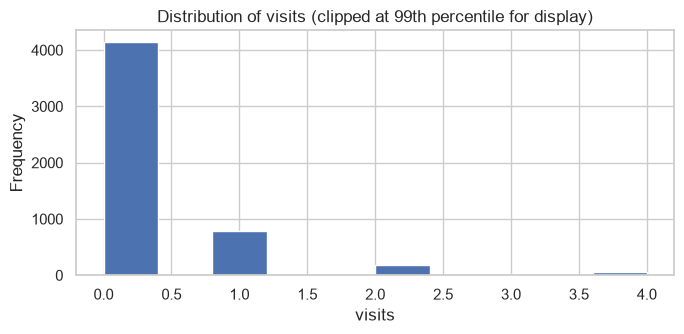

GENDER  (column 'gender')
H0: Visit distributions are the same across gender groups.
H1: Visit distributions differ across gender groups.
α = 0.05

Rows: 5190 total | missing/non-numeric outcome: 0 | missing group: 0 | excluded levels []: 0 | analysed (complete cases): 5190

Group summary:
           n   mean     sd  median   q1   q3  min  max  pct_zero   skew
gender                                                                 
female  2702  0.362  0.858     0.0  0.0  0.0    0    8    75.574  4.296
male    2488  0.236  0.722     0.0  0.0  0.0    0    9    84.365  5.422

Assumption checks
  Independence of observations : cannot be tested from data; assumed from the study design (one row per person, no repeated measures/clustering). Verify this.
  Shapiro-Wilk p (per group; <0.05 = non-normal): female: 1.65e-67, male: 6.29e-69
    (with large n, normality tests reject for trivial departures; the skew/zero-inflation shown above is the more informative evidence.)
  Levene/Brown-Forsythe

Question,Gender,Chronic condition,Private insurance
Groups,female vs male,no vs yes,no vs yes
n per group,2702 / 2488,3098 / 2092,2892 / 2298
Mean visits,0.36 / 0.24,0.27 / 0.35,0.31 / 0.29
Median visits,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0
Test,Mann-Whitney U,Mann-Whitney U,Mann-Whitney U
Statistic,3655194.5,3055466.0,3334282.5
p (raw),<0.0001,<0.0001,0.7615
p (Holm),<0.0001,<0.0001,0.7615
Sig. raw (α=0.05),Yes,Yes,No
Sig. Holm (α=0.05),Yes,Yes,No


--- Gender ---
We compared visits for 'female' (n=2702, mean 0.36, median 0.0) with 'male' (n=2488, mean 0.24, median 0.0).
Statistically, the data are inconsistent with 'no difference' (p = <0.0001; still below 0.05 after Holm correction, p = <0.0001).
Size of the difference: a randomly chosen person from 'female' has more visits than one from 'male' with probability about 0.54 (ties counted half; 0.50 = no difference). Rank-biserial r = 0.09, conventionally 'negligible'. Average visits differ by 0.13 (95% CI 0.08 to 0.17), a ratio of 1.53.
The medians are identical, so the test is detecting differences elsewhere in the distribution (for example the share of people with several visits), not a median shift.
Practical note: statistically detectable but very small. With large samples tiny differences become significant, so this may not matter in practice.
Caution: this is an unadjusted, observational comparison. Differences may reflect other factors (age, income, health status) and do no

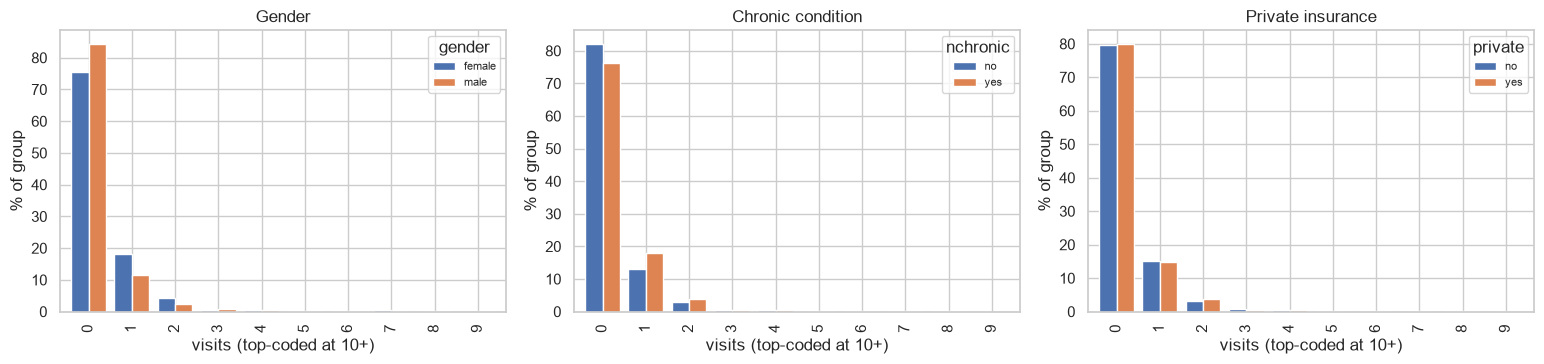

In [20]:
# %% [markdown]
# # Hypothesis Testing: Doctor Visits
#

# **Conventions used throughout**
# - Significance level α = 0.05: if H0 were true, we would see a result at least this extreme
#   about 5% of the time by chance alone. It is *not* the probability that H0 is true, and a
#   small p-value says nothing about how large or important an effect is.
# - All comparisons are **unadjusted and observational**. Nothing here establishes causation.
# - This section expects a DataFrame called `df` to already exist in the notebook.

import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests

ALPHA = 0.05          # significance level
N_BOOT = 2000         # bootstrap resamples for confidence intervals
RNG_SEED = 42         # reproducibility
MIN_GROUP_N = 30      # warn if a group is smaller than this
HARD_MIN_N = 5        # refuse to test if a group is smaller than this

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

# ## 1. Configuration: map your columns
#
# Column names are auto-detected from common names. **If detection fails or picks the wrong
# column, set the names explicitly below.** Optionally list category levels to exclude
# (for example `"unknown"` or `"not reported"`) in `EXCLUDE_LEVELS`.

# %%
OUTCOME = None  # e.g. "visits"
COLS = {"gender": None, "chronic": None, "private": None}  # e.g. {"gender": "gender", ...}

EXCLUDE_LEVELS = {  # levels that are NOT valid comparison groups, per variable key
    "gender": [],
    "chronic": [],
    "private": [],
}

LABELS = {"gender": "Gender", "chronic": "Chronic condition", "private": "Private insurance"}

CANDIDATES = {
    "outcome": ["visits", "doctor_visits", "doctorvisits", "n_visits", "num_visits", "number_of_visits"],
    "gender": ["gender", "sex"],
    "chronic": ["nchronic", "chronic", "chronic_condition", "chronic_status", "has_chronic"],
    "private": ["private", "private_insurance", "has_private_insurance", "insurance_private"],
}


def find_col(frame, candidates):
    lookup = {str(c).lower().strip().replace(" ", "_"): c for c in frame.columns}
    for cand in candidates:
        if cand in lookup:
            return lookup[cand]
    return None


if OUTCOME is None:
    OUTCOME = find_col(df, CANDIDATES["outcome"])
for key in COLS:
    if COLS[key] is None:
        COLS[key] = find_col(df, CANDIDATES[key])

missing_cfg = [k for k, v in {"outcome": OUTCOME, **COLS}.items() if v is None]
if missing_cfg:
    raise ValueError(
        f"Could not auto-detect columns for {missing_cfg}. Set OUTCOME / COLS manually.\n"
        f"Available columns: {list(df.columns)}"
    )

print("Outcome column :", OUTCOME)
for k, v in COLS.items():
    print(f"{LABELS[k]:<20}:", v)

# ## 2. Inspect encodings, missing values and the outcome distribution
#
# Check that each grouping variable has sensible levels and that the outcome behaves like a count.

# %%
print("=== Dtypes ===")
print(df[[OUTCOME] + list(COLS.values())].dtypes, "\n")

print("=== Missing values ===")
print(df[[OUTCOME] + list(COLS.values())].isna().sum().to_frame("n_missing")
      .assign(pct=lambda t: (t["n_missing"] / len(df) * 100).round(2)), "\n")

for key, col in COLS.items():
    print(f"=== {LABELS[key]} (column '{col}') level counts, incl. NaN ===")
    print(df[col].value_counts(dropna=False).to_frame("n"), "\n")

y_all = pd.to_numeric(df[OUTCOME], errors="coerce")
print(f"=== Outcome '{OUTCOME}' ===")
print("Non-numeric / missing values:", int(y_all.isna().sum()))
yy = y_all.dropna()
is_count = bool((yy >= 0).all() and np.allclose(yy, np.round(yy)))
print(pd.Series({
    "n": len(yy), "min": yy.min(), "max": yy.max(), "mean": yy.mean(), "median": yy.median(),
    "variance": yy.var(), "variance/mean": yy.var() / yy.mean() if yy.mean() else np.nan,
    "% zeros": (yy == 0).mean() * 100, "skewness": stats.skew(yy),
    "non-negative integers?": is_count,
}).to_string())
print("\nNote: variance/mean well above 1, many zeros and strong right skew are typical of visit counts. "
      "They argue against a t-test as the primary test and for rank-based tests.")

fig, ax = plt.subplots(figsize=(7, 3.5))
yy.clip(upper=yy.quantile(0.99)).plot(kind="hist", bins=min(30, int(yy.nunique())), ax=ax, edgecolor="white")
ax.set_title(f"Distribution of {OUTCOME} (clipped at 99th percentile for display)")
ax.set_xlabel(OUTCOME)
plt.tight_layout()
plt.show()
## 3. Hypotheses and test choice
#
# | Question | H0 | H1 |
# |---|---|---|
# | Gender | Visit distributions are the same in the gender groups (neither group tends to have higher visits). | Visit distributions differ (one group tends to have higher visits). |
# | Chronic condition | Visit distributions are the same with and without a chronic condition. | Visit distributions differ. |
# | Private insurance | Visit distributions are the same with and without private insurance. | Visit distributions differ. |
#
# **Primary test: Mann–Whitney U (two-sided).** Visits are non-negative, discrete, zero-heavy and
# skewed, so a rank-based test is more defensible than a t-test. It assesses whether a random
# person from one group tends to have more visits than a random person from the other. It can be read as a
# comparison of medians only if the two distribution shapes are similar, and with many ties at
# 0/1 the medians may be identical even when the test is significant.
# If a variable has more than two valid levels, the code switches to **Kruskal–Wallis** with
# Holm-corrected pairwise Mann–Whitney post-hoc tests.
#
# **Sensitivity checks (for two groups):** Welch t-test (mean difference), and a Poisson model with
# robust standard errors, whose coefficient gives the ratio of mean visits (valid for counts even if
# the Poisson variance assumption fails).
#
# **Effect sizes:** rank-biserial correlation *r* (−1 to 1) and the probability of superiority
# P(A > B) + 0.5·P(A = B); mean and median differences with bootstrap CIs; Cohen's *d*;
# ε² for Kruskal–Wallis.

# %%
HYPOTHESES = {
    "gender": ("Visit distributions are the same across gender groups.",
               "Visit distributions differ across gender groups."),
    "chronic": ("Visit distributions are the same with and without a chronic condition.",
                "Visit distributions differ by chronic-condition status."),
    "private": ("Visit distributions are the same with and without private insurance.",
                "Visit distributions differ by private-insurance status."),
}


def sorted_levels(series):
    vals = list(series.dropna().unique())
    try:
        return sorted(vals)
    except TypeError:
        return sorted(vals, key=str)


def describe_groups(d, g, y):
    q1 = lambda x: x.quantile(0.25)
    q3 = lambda x: x.quantile(0.75)
    zero = lambda x: (x == 0).mean() * 100
    skew = lambda x: stats.skew(x) if len(x) > 2 else np.nan
    out = d.groupby(g)[y].agg(n="count", mean="mean", sd="std", median="median",
                              q1=q1, q3=q3, min="min", max="max",
                              pct_zero=zero, skew=skew)
    return out.round(3)


def check_assumptions(d, g, y, groups):
    rng = np.random.default_rng(RNG_SEED)
    samples = [d.loc[d[g] == lv, y].to_numpy(float) for lv in groups]
    info = {}
    # Levene / Brown-Forsythe (median-centred): similar spread is needed to read MWU as a location shift
    info["levene_p"] = stats.levene(*samples, center="median").pvalue
    sh = {}
    for lv, x in zip(groups, samples):
        if np.ptp(x) == 0 or len(x) < 3:
            sh[lv] = np.nan
        else:
            xs = rng.choice(x, size=min(len(x), 5000), replace=False)
            sh[lv] = stats.shapiro(xs).pvalue
    info["shapiro_p"] = sh
    info["sd_ratio"] = max(np.std(s, ddof=1) for s in samples) / max(min(np.std(s, ddof=1) for s in samples), 1e-12)
    info["tie_share"] = 1 - d[y].nunique() / len(d)
    return info, samples


def bootstrap_ci(a, b, n_boot=N_BOOT, seed=RNG_SEED):
    rng = np.random.default_rng(seed)
    n1, n2 = len(a), len(b)
    md, mdn, rb = [], [], []
    for _ in range(n_boot):
        ra, rb_ = rng.choice(a, n1), rng.choice(b, n2)
        md.append(ra.mean() - rb_.mean())
        mdn.append(np.median(ra) - np.median(rb_))
        ranks = stats.rankdata(np.concatenate([ra, rb_]))
        u = ranks[:n1].sum() - n1 * (n1 + 1) / 2
        rb.append(2 * u / (n1 * n2) - 1)
    lo, hi = 100 * ALPHA / 2, 100 * (1 - ALPHA / 2)
    pct = lambda x: (float(np.percentile(x, lo)), float(np.percentile(x, hi)))
    return pct(md), pct(mdn), pct(rb)


def poisson_ratio(a, b):
    """Ratio of mean visits (A/B) from a Poisson GLM with robust (HC0) SEs."""
    y = np.concatenate([a, b])
    x = np.concatenate([np.ones(len(a)), np.zeros(len(b))])
    fit = sm.GLM(y, sm.add_constant(x), family=sm.families.Poisson()).fit(cov_type="HC0")
    ci = np.exp(fit.conf_int()[1])
    return float(np.exp(fit.params[1])), (float(ci[0]), float(ci[1])), float(fit.pvalues[1])


def magnitude_rank_biserial(r):
    r = abs(r)
    return "negligible" if r < 0.1 else "small" if r < 0.3 else "medium" if r < 0.5 else "large"


def magnitude_epsilon2(e):
    return "negligible" if e < 0.01 else "small" if e < 0.06 else "medium" if e < 0.14 else "large"


def analyze(key):
    col, label = COLS[key], LABELS[key]
    h0, h1 = HYPOTHESES[key]
    print("=" * 100)
    print(f"{label.upper()}  (column '{col}')")
    print("=" * 100)
    print(f"H0: {h0}\nH1: {h1}\nα = {ALPHA}\n")

    d = df[[OUTCOME, col]].copy()
    d[OUTCOME] = pd.to_numeric(d[OUTCOME], errors="coerce")
    d[col] = d[col].astype(object)
    n_total = len(d)
    n_miss_y, n_miss_g = int(d[OUTCOME].isna().sum()), int(d[col].isna().sum())
    d = d.dropna()
    excl = EXCLUDE_LEVELS.get(key, [])
    n_excl = int(d[col].isin(excl).sum())
    d = d[~d[col].isin(excl)]
    print(f"Rows: {n_total} total | missing/non-numeric outcome: {n_miss_y} | missing group: {n_miss_g} | "
          f"excluded levels {excl}: {n_excl} | analysed (complete cases): {len(d)}")

    groups = sorted_levels(d[col])
    k = len(groups)
    if k < 2:
        print("Fewer than two valid groups: test not possible.\n")
        return None
    desc = describe_groups(d, col, OUTCOME)
    print("\nGroup summary:")
    print(desc.to_string())
    if (desc["n"] < HARD_MIN_N).any():
        print(f"\nA group has fewer than {HARD_MIN_N} observations: test skipped.\n")
        return None
    if (desc["n"] < MIN_GROUP_N).any():
        print(f"\nWARNING: a group has fewer than {MIN_GROUP_N} observations; interpret cautiously.")

    info, samples = check_assumptions(d, col, OUTCOME, groups)
    print("\nAssumption checks")
    print("  Independence of observations : cannot be tested from data; assumed from the study design "
          "(one row per person, no repeated measures/clustering). Verify this.")
    print(f"  Shapiro-Wilk p (per group; <{ALPHA} = non-normal): "
          + ", ".join(f"{lv}: {p:.3g}" for lv, p in info["shapiro_p"].items()))
    print("    (with large n, normality tests reject for trivial departures; the skew/zero-inflation shown "
          "above is the more informative evidence.)")
    print(f"  Levene/Brown-Forsythe p (equal spread): {info['levene_p']:.3g}; SD ratio (max/min): {info['sd_ratio']:.2f}")
    print(f"  Share of tied values: {info['tie_share']:.1%} (handled by the tie-corrected normal approximation)")
    print("  Rank tests need no normality. Reading the result as a 'median shift' additionally needs similar "
          "distribution shapes; otherwise read it as 'one group tends to have higher values'.")

    res = {"key": key, "label": label, "col": col, "groups": groups, "k": k, "desc": desc,
           "n_analysed": len(d), "data": d, "h0": h0, "h1": h1, "assumptions": info}

    if k == 2:
        a, b = samples
        A, B = groups
        n1, n2 = len(a), len(b)
        mw = stats.mannwhitneyu(a, b, alternative="two-sided")
        u1 = float(mw.statistic)
        cles = u1 / (n1 * n2)
        rbc = 2 * cles - 1
        (md_ci, mdn_ci, rb_ci) = bootstrap_ci(a, b)
        welch = stats.ttest_ind(a, b, equal_var=False)
        sp = np.sqrt(((n1 - 1) * a.var(ddof=1) + (n2 - 1) * b.var(ddof=1)) / (n1 + n2 - 2))
        cohen_d = (a.mean() - b.mean()) / sp if sp > 0 else np.nan
        try:
            ratio, ratio_ci, ratio_p = poisson_ratio(a, b)
        except Exception as exc:  # model failure should not stop the notebook
            ratio, ratio_ci, ratio_p = np.nan, (np.nan, np.nan), np.nan
            warnings.warn(f"Poisson sensitivity model failed: {exc}")

        print(f"\nPrimary test: Mann-Whitney U, two-sided")
        print(f"  U (for {A}) = {u1:,.1f}, p = {mw.pvalue:.4g}")
        print(f"  Rank-biserial r = {rbc:.3f}  (95% bootstrap CI {rb_ci[0]:.3f} to {rb_ci[1]:.3f}); "
              f"positive means '{A}' tends to be higher than '{B}'")
        print(f"  P({A} > {B}) + 0.5*P(tie) = {cles:.3f}  (0.5 = no difference)")
        print(f"  Mean difference ({A} - {B}) = {a.mean() - b.mean():.3f} "
              f"(95% CI {md_ci[0]:.3f} to {md_ci[1]:.3f})")
        print(f"  Median difference ({A} - {B}) = {np.median(a) - np.median(b):.3f} "
              f"(95% CI {mdn_ci[0]:.3f} to {mdn_ci[1]:.3f})")
        print("Sensitivity checks")
        print(f"  Welch t-test: t = {welch.statistic:.3f}, p = {welch.pvalue:.4g}; Cohen's d = {cohen_d:.3f}")
        print(f"  Poisson (robust SE) ratio of mean visits {A}/{B} = {ratio:.3f} "
              f"(95% CI {ratio_ci[0]:.3f} to {ratio_ci[1]:.3f}), p = {ratio_p:.4g}")

        res.update(test="Mann-Whitney U", statistic=u1, p=float(mw.pvalue),
                   effect_name="rank-biserial r", effect=rbc, effect_ci=rb_ci,
                   magnitude=magnitude_rank_biserial(rbc), cles=cles,
                   mean_diff=float(a.mean() - b.mean()), mean_diff_ci=md_ci,
                   median_diff=float(np.median(a) - np.median(b)), median_diff_ci=mdn_ci,
                   welch_p=float(welch.pvalue), cohen_d=float(cohen_d),
                   ratio=ratio, ratio_ci=ratio_ci, ratio_p=ratio_p, posthoc=None)
    else:
        kw = stats.kruskal(*samples)
        n = len(d)
        eps2 = max(0.0, (kw.statistic - k + 1) / (n - k))
        print(f"\nPrimary test: Kruskal-Wallis across {k} groups")
        print(f"  H = {kw.statistic:.3f}, df = {k - 1}, p = {kw.pvalue:.4g}, epsilon-squared = {eps2:.4f}")
        pairs, raw = [], []
        for i in range(k):
            for j in range(i + 1, k):
                p = stats.mannwhitneyu(samples[i], samples[j], alternative="two-sided").pvalue
                pairs.append(f"{groups[i]} vs {groups[j]}")
                raw.append(p)
        adj = multipletests(raw, alpha=ALPHA, method="holm")[1]
        post = pd.DataFrame({"pair": pairs, "p_raw": raw, "p_holm": adj})
        print("  Post-hoc pairwise Mann-Whitney (Holm-adjusted):")
        print(post.round(4).to_string(index=False))
        res.update(test="Kruskal-Wallis", statistic=float(kw.statistic), p=float(kw.pvalue),
                   effect_name="epsilon-squared", effect=float(eps2), effect_ci=(np.nan, np.nan),
                   magnitude=magnitude_epsilon2(eps2), cles=np.nan, mean_diff=np.nan,
                   mean_diff_ci=(np.nan, np.nan), median_diff=np.nan, median_diff_ci=(np.nan, np.nan),
                   welch_p=np.nan, cohen_d=np.nan, ratio=np.nan, ratio_ci=(np.nan, np.nan),
                   ratio_p=np.nan, posthoc=post)
    print()
    return res

# ## 4. Run the three tests

# %%
results = {}
for key in ["gender", "chronic", "private"]:
    r = analyze(key)
    if r is not None:
        results[key] = r

# ## 5. Multiple-comparison correction
#
# Three questions are tested on the same outcome, so the chance of at least one false positive
# across the family exceeds 5% if each test uses α = 0.05 on its own. Two standard corrections
# of the family-wise error rate are shown:
# - **Bonferroni**: multiply each p by the number of tests (simple, conservative).
# - **Holm**: uniformly at least as powerful as Bonferroni with the same guarantee (**preferred here**).
#
# If the three questions are viewed as separate, pre-specified analyses, the raw p-values may be
# defended; reporting both is the transparent choice.

# %%
keys = list(results)
p_raw = np.array([results[k]["p"] for k in keys])
if len(p_raw):
    holm = multipletests(p_raw, alpha=ALPHA, method="holm")[1]
    bonf = multipletests(p_raw, alpha=ALPHA, method="bonferroni")[1]
    for k, h, b in zip(keys, holm, bonf):
        results[k]["p_holm"], results[k]["p_bonf"] = float(h), float(b)

# ## 6. Summary table

# %%
def fmt_ci(ci, nd=3):
    return "" if ci is None or np.isnan(ci[0]) else f"({ci[0]:.{nd}f}, {ci[1]:.{nd}f})"


def fmt_p(p):
    return "" if p is None or (isinstance(p, float) and np.isnan(p)) else ("<0.0001" if p < 1e-4 else f"{p:.4f}")


rows = []
for k in keys:
    r = results[k]
    d = r["desc"]
    rows.append({
        "Question": r["label"],
        "Groups": " vs ".join(map(str, r["groups"])),
        "n per group": " / ".join(str(int(x)) for x in d["n"]),
        "Mean visits": " / ".join(f"{x:.2f}" for x in d["mean"]),
        "Median visits": " / ".join(f"{x:.1f}" for x in d["median"]),
        "Test": r["test"],
        "Statistic": round(r["statistic"], 3),
        "p (raw)": fmt_p(r["p"]),
        "p (Holm)": fmt_p(r["p_holm"]),
        f"Sig. raw (α={ALPHA})": "Yes" if r["p"] < ALPHA else "No",
        f"Sig. Holm (α={ALPHA})": "Yes" if r["p_holm"] < ALPHA else "No",
        "Effect size": f"{r['effect_name']} = {r['effect']:.3f} {fmt_ci(r['effect_ci'])}".strip(),
        "Magnitude (rule of thumb)": r["magnitude"],
        "Mean diff (CI)": "" if np.isnan(r["mean_diff"]) else f"{r['mean_diff']:.3f} {fmt_ci(r['mean_diff_ci'])}",
        "Mean-visit ratio (CI)": "" if np.isnan(r["ratio"]) else f"{r['ratio']:.3f} {fmt_ci(r['ratio_ci'])}",
    })
summary = pd.DataFrame(rows)
summary_t = summary.set_index("Question")
try:
    from IPython.display import display
    display(summary_t.T)
except ImportError:
    print(summary_t.T.to_string())

# ## 7. Plain-language interpretation
#
# Text is generated from the computed values, so it changes with your data.
# "Significant" means only that the data are hard to reconcile with H0 at α = 0.05.
# "Not significant" means there is insufficient evidence of a difference, **not** proof of equality.

# %%
def explain(r):
    lines = [f"--- {r['label']} ---"]
    sig_raw, sig_holm = r["p"] < ALPHA, r["p_holm"] < ALPHA
    if r["k"] == 2:
        A, B = r["groups"]
        d = r["desc"]
        lines.append(
            f"We compared visits for '{A}' (n={int(d.loc[A, 'n'])}, mean {d.loc[A, 'mean']:.2f}, median "
            f"{d.loc[A, 'median']:.1f}) with '{B}' (n={int(d.loc[B, 'n'])}, mean {d.loc[B, 'mean']:.2f}, "
            f"median {d.loc[B, 'median']:.1f}).")
        if sig_raw and sig_holm:
            lines.append(f"Statistically, the data are inconsistent with 'no difference' (p = {fmt_p(r['p'])}; "
                         f"still below {ALPHA} after Holm correction, p = {fmt_p(r['p_holm'])}).")
        elif sig_raw:
            lines.append(f"The raw p-value ({fmt_p(r['p'])}) is below {ALPHA}, but it is not after Holm correction "
                         f"({fmt_p(r['p_holm'])}), so the evidence is weaker once we account for running three tests.")
        else:
            lines.append(f"We did not find enough evidence of a difference (p = {fmt_p(r['p'])}). "
                         "This does not prove the groups are the same.")
        lines.append(
            f"Size of the difference: a randomly chosen person from '{A}' has more visits than one from '{B}' "
            f"with probability about {r['cles']:.2f} "
            f"(ties counted half; 0.50 = no difference). Rank-biserial r = {r['effect']:.2f}, "
            f"conventionally '{r['magnitude']}'. Average visits differ by {r['mean_diff']:.2f} "
            f"(95% CI {r['mean_diff_ci'][0]:.2f} to {r['mean_diff_ci'][1]:.2f}), a ratio of {r['ratio']:.2f}.")
        if sig_raw and r["median_diff"] == 0:
            lines.append("The medians are identical, so the test is detecting differences elsewhere in the "
                         "distribution (for example the share of people with several visits), not a median shift.")
        if sig_raw and r["magnitude"] == "negligible":
            lines.append("Practical note: statistically detectable but very small. With large samples tiny "
                         "differences become significant, so this may not matter in practice.")
        elif sig_raw:
            lines.append(f"Practical note: the effect is not trivially small, but whether {abs(r['mean_diff']):.2f} "
                         "visits on average matters is a clinical/operational judgement for domain experts.")
        elif not sig_raw and r["mean_diff_ci"][0] * r["mean_diff_ci"][1] < 0:
            lines.append("The mean-difference confidence interval spans zero, consistent with the test result.")
    else:
        lines.append(f"Kruskal-Wallis across {r['k']} groups: p = {fmt_p(r['p'])}, epsilon-squared = "
                     f"{r['effect']:.3f} ('{r['magnitude']}'). See the post-hoc table for which pairs differ.")
    lines.append("Caution: this is an unadjusted, observational comparison. Differences may reflect other "
                 "factors (age, income, health status) and do not show that the variable causes the difference.")
    return "\n".join(lines)


for k in keys:
    print(explain(results[k]), "\n")

# ## 8. Visual check of the distributions
#
# Because visits are discrete and zero-heavy, bars of the share of people at each visit count
# (top-coded) are more informative than box plots.

# %%
CAP = 10
fig, axes = plt.subplots(1, len(keys), figsize=(5.2 * len(keys), 3.8), squeeze=False)
for ax, k in zip(axes[0], keys):
    r = results[k]
    d = r["data"]
    tab = pd.crosstab(d[r["col"]], d[OUTCOME].clip(upper=CAP), normalize="index") * 100
    tab.T.plot(kind="bar", ax=ax, width=0.8)
    ax.set_title(r["label"])
    ax.set_xlabel(f"{OUTCOME} (top-coded at {CAP}+)")
    ax.set_ylabel("% of group")
    ax.legend(title=r["col"], fontsize=8)
plt.tight_layout()
plt.show()


## 18. Self-reported health and doctor visits

dtypes:
 health    int64
visits    int64 

Missing values:
 health    0
visits    0 

Rows before: 5190 | dropped for missing/non-numeric in either column: 0 | analysed: 5190
health integer-valued: True | range: (np.int64(0), np.int64(12)) | documented range: (0, 12)
visits non-negative integers: True | range: (np.int64(0), np.int64(9))

Overall visits: mean = 0.302, median = 0.0, SD = 0.798, % with 0 visits = 79.8%
Health scale direction used in this analysis: higher score = WORSE health
                 n  percent  cumulative_percent sparse (n<30)
health score                                                 
0             3026    58.30               58.30              
1              823    15.86               74.16              
2              446     8.59               82.75              
3              273     5.26               88.01              
4              187     3.60               91.61              
5              132     2.54               94.15              
6         

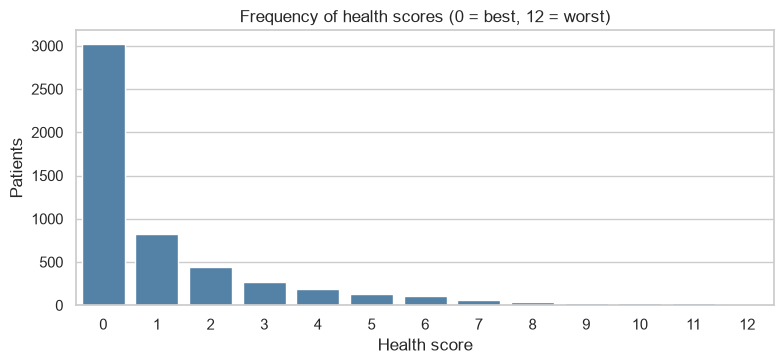

Pooled categories: {'9–10': [9, 10], '11–12': [11, 12]}
Per original health score:
        patients  mean_visits  median_visits  sd_visits  pct_any_visit sparse
health                                                                       
0           3026        0.199            0.0      0.593         15.036       
1            823        0.335            0.0      0.787         23.451       
2            446        0.381            0.0      0.878         24.439       
3            273        0.418            0.0      0.952         25.641       
4            187        0.535            0.0      1.258         27.807       
5            132        0.530            0.0      1.226         28.030       
6            104        0.625            0.0      1.142         39.423       
7             61        0.918            0.0      1.487         49.180       
8             42        0.476            0.0      0.862         30.952       
9             32        0.656            0.0      1.035    

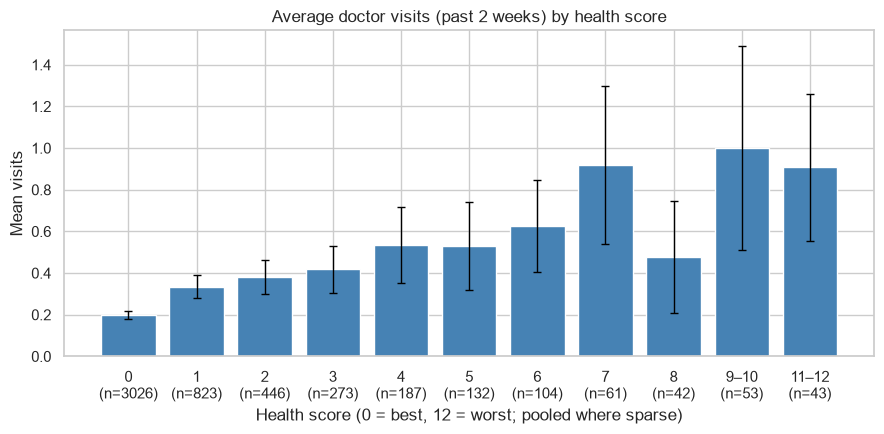

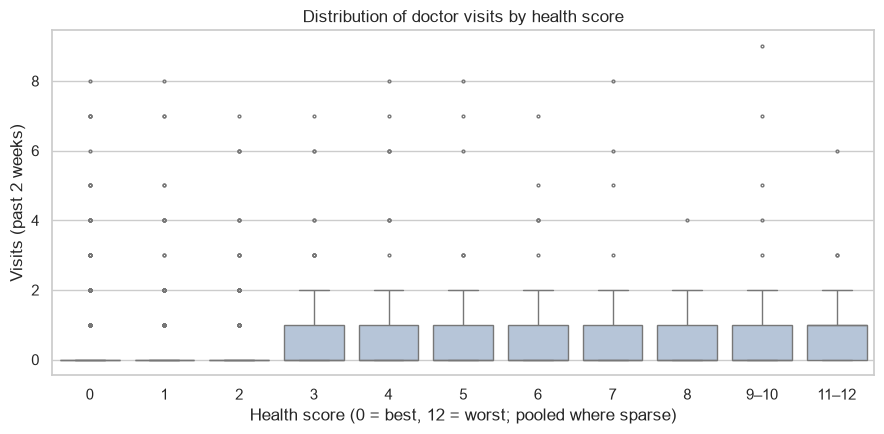

Reading note: most people have 0 visits, so in many categories the box collapses to a flat line at 0 and the larger values are drawn as outlier points. Use the 'pct_any_visit' column above for a clearer view.
n = 5190
Spearman rho = 0.178  (95% bootstrap CI 0.148 to 0.205),  p = 5.22e-38
Kendall tau-b = 0.161,  p = 1.69e-37
Conventional strength label (rule of thumb): weak
Scale meaning: higher score = WORSE health; visits = doctor consultations in the past 2 weeks.

Pattern: the Spearman correlation is positive (rho = 0.18, 95% CI 0.15 to 0.20, p = 5.22e-38),
a 'weak' monotonic association. Under the verified scale direction, people with HIGHER scores
(worse reported health) tend to have more visits.
Mean visits move from 0.20 in the lowest category (0, n=3026)
to 0.91 in the highest (11–12, n=43);
the share with at least one visit moves from 15.0% to 58.1%.
The increase is not perfectly steady; the mean dips between: 4 -> 5, 7 -> 8, 9–10 -> 11–12.
10 of 11 categories have a median of

In [21]:
# %% [markdown]
# # Self-Reported Health and Doctor Visits
#
# **Question:** Is health score related to the number of doctor visits?
#
# ## Verifying what `health` and `visits` mean
# The column names suggest this is the Australian Health Survey 1977–78 data
# (Cameron, Trivedi, Milne & Piggott, 1988; 5,190 single adults, young and old oversampled).
# I checked the published documentation for this data, where the health variable is called `hscore`:
#
# - **`health`** = *General Health Questionnaire score using Goldberg's method*, integer **0–12**,
#   where **a HIGH score indicates BAD health** (so 0 = best, 12 = worst).
#   It is a symptom/distress checklist score reported by the respondent, not a clinician rating and
#   not a "1 = poor … 5 = excellent" rating.
# - **`visits`** = number of doctor consultations in the **past 2 weeks** (a non-negative count).
#
# Caveat: the documentation I checked uses the original variable names (`hscore`, `doctorco`), while this
# CSV uses `health` and `visits`. The mapping rests on matching content (n = 5,190; integer range 0–12).
# If your notebook or data dictionary says otherwise, change `HEALTH_DIRECTION` below.
#
# The analysis below describes an **observational association**. It can't show that poor health
# *causes* doctor visits, or that visits cause poor health.

# %%
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

assert "df" in globals(), "Please load your data into a DataFrame named `df` first."

HEALTH_COL, VISITS_COL = "health", "visits"
HEALTH_DIRECTION = "higher score = WORSE health"  # verified from documentation (see above)
DOC_RANGE = (0, 12)        # documented range of the GHQ score
MIN_CATEGORY_N = 30        # categories smaller than this are pooled for tables/plots
N_BOOT, SEED, ALPHA = 2000, 42, 0.05

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)

# %% [markdown]
# ## 1. Inspect and clean the two columns

# %%
for c in (HEALTH_COL, VISITS_COL):
    assert c in df.columns, f"Column '{c}' not found. Available: {list(df.columns)}"

raw = df[[HEALTH_COL, VISITS_COL]].copy()
print("dtypes:\n", raw.dtypes.to_string(), "\n")
print("Missing values:\n", raw.isna().sum().to_string(), "\n")

raw[HEALTH_COL] = pd.to_numeric(raw[HEALTH_COL], errors="coerce")
raw[VISITS_COL] = pd.to_numeric(raw[VISITS_COL], errors="coerce")

n_before = len(raw)
data = raw.dropna().copy()
print(f"Rows before: {n_before} | dropped for missing/non-numeric in either column: {n_before - len(data)} "
      f"| analysed: {len(data)}")

# Validity checks (warn, do not silently alter data)
h, v = data[HEALTH_COL], data[VISITS_COL]
print("health integer-valued:", bool(np.allclose(h, h.round())),
      "| range:", (h.min(), h.max()), "| documented range:", DOC_RANGE)
if h.min() < DOC_RANGE[0] or h.max() > DOC_RANGE[1]:
    print("WARNING: health values fall outside the documented range. Check coding before interpreting.")
print("visits non-negative integers:", bool((v >= 0).all() and np.allclose(v, v.round())),
      "| range:", (v.min(), v.max()))
data[HEALTH_COL] = h.round().astype(int)
data[VISITS_COL] = v.round().astype(int)

print("\nOverall visits: mean = {:.3f}, median = {:.1f}, SD = {:.3f}, % with 0 visits = {:.1f}%".format(
    data[VISITS_COL].mean(), data[VISITS_COL].median(), data[VISITS_COL].std(),
    (data[VISITS_COL] == 0).mean() * 100))
print(f"Health scale direction used in this analysis: {HEALTH_DIRECTION}")

# %% [markdown]
# ## 2. Frequency distribution of health scores

# %%
freq = data[HEALTH_COL].value_counts().sort_index().to_frame("n")
freq["percent"] = (freq["n"] / freq["n"].sum() * 100).round(2)
freq["cumulative_percent"] = freq["percent"].cumsum().round(2)
freq["sparse (n<%d)" % MIN_CATEGORY_N] = np.where(freq["n"] < MIN_CATEGORY_N, "yes", "")
freq.index.name = "health score"
print(freq.to_string())

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.barplot(x=freq.index, y=freq["n"], color="steelblue", ax=ax)
ax.set(title="Frequency of health scores (0 = best, 12 = worst)", xlabel="Health score", ylabel="Patients")
plt.tight_layout()
plt.show()

# %% [markdown]
# ## 3. Handling sparse categories
# Very small categories give unstable means and wide intervals. For **tables-by-category and plots**
# neighbouring scores are pooled until each group has at least `MIN_CATEGORY_N` patients (starting from the
# thinly populated end). The **Spearman correlation uses the original, unpooled scores**, so pooling does not
# affect it.

# %%
def pool_sparse_levels(counts: pd.Series, min_n: int):
    """Greedy pooling of adjacent ordered levels from the highest level downward."""
    levels = list(counts.index)[::-1]
    bins, cur, cur_n = [], [], 0
    for lv in levels:
        cur.append(lv)
        cur_n += counts[lv]
        if cur_n >= min_n:
            bins.append(cur)
            cur, cur_n = [], 0
    if cur:  # leftover sparse group at the low end: merge into previous bin
        if bins:
            bins[-1].extend(cur)
        else:
            bins.append(cur)
    bins = [sorted(b) for b in bins][::-1]
    mapping, labels = {}, []
    for b in bins:
        label = str(b[0]) if len(b) == 1 else f"{b[0]}–{b[-1]}"
        labels.append(label)
        for lv in b:
            mapping[lv] = label
    return mapping, labels


mapping, label_order = pool_sparse_levels(data[HEALTH_COL].value_counts().sort_index(), MIN_CATEGORY_N)
data["health_group"] = pd.Categorical(data[HEALTH_COL].map(mapping), categories=label_order, ordered=True)
pooled = {lab: [k for k, val in mapping.items() if val == lab] for lab in label_order if "–" in lab}
print("Pooled categories:", pooled if pooled else "none needed")

# %% [markdown]
# ## 4. Visits by health category

# %%
def summarise(frame, group_col):
    g = frame.groupby(group_col, observed=True)[VISITS_COL]
    out = g.agg(patients="count", mean_visits="mean", median_visits="median", sd_visits="std")
    out["pct_any_visit"] = g.apply(lambda s: (s > 0).mean() * 100)
    sem = out["sd_visits"] / np.sqrt(out["patients"])
    tcrit = stats.t.ppf(1 - ALPHA / 2, (out["patients"] - 1).clip(lower=1))
    out["ci_low"] = out["mean_visits"] - tcrit * sem
    out["ci_high"] = out["mean_visits"] + tcrit * sem
    return out.round(3)


print("Per original health score:")
by_score = summarise(data, HEALTH_COL)
by_score["sparse"] = np.where(by_score["patients"] < MIN_CATEGORY_N, "yes", "")
print(by_score.drop(columns=["ci_low", "ci_high"]).to_string())

print("\nPer analysis category (sparse scores pooled):")
by_group = summarise(data, "health_group")
print(by_group.to_string())

# %%
# Bar chart: mean visits (95% t-based CI) by analysis category
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(by_group))
ax.bar(x, by_group["mean_visits"], color="steelblue", edgecolor="white")
ax.errorbar(x, by_group["mean_visits"],
            yerr=[by_group["mean_visits"] - by_group["ci_low"], by_group["ci_high"] - by_group["mean_visits"]],
            fmt="none", ecolor="black", capsize=3, lw=1)
ax.set_xticks(x)
ax.set_xticklabels([f"{lab}\n(n={n})" for lab, n in zip(by_group.index, by_group["patients"])])
ax.set(title="Average doctor visits (past 2 weeks) by health score",
       xlabel="Health score (0 = best, 12 = worst; pooled where sparse)", ylabel="Mean visits")
plt.tight_layout()
plt.show()

# %%
# Boxplot: visits by analysis category
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=data, x="health_group", y=VISITS_COL, color="lightsteelblue", fliersize=2, ax=ax)
ax.set(title="Distribution of doctor visits by health score",
       xlabel="Health score (0 = best, 12 = worst; pooled where sparse)", ylabel="Visits (past 2 weeks)")
plt.tight_layout()
plt.show()
print("Reading note: most people have 0 visits, so in many categories the box collapses to a flat line at 0 "
      "and the larger values are drawn as outlier points. Use the 'pct_any_visit' column above for a clearer view.")

# %% [markdown]
# ## 5. Spearman rank correlation
# Spearman is appropriate because `health` is an ordered integer score, `visits` is a skewed, zero-heavy count,
# and the question is about a monotonic association, not a straight-line one. Ties are handled with average
# ranks. A bootstrap CI and Kendall's tau-b (another tie-aware rank measure) are shown as robustness checks.

# %%
rho, p = stats.spearmanr(data[HEALTH_COL], data[VISITS_COL])
tau, p_tau = stats.kendalltau(data[HEALTH_COL], data[VISITS_COL], variant="b")

rng = np.random.default_rng(SEED)
hv, vv = data[HEALTH_COL].to_numpy(), data[VISITS_COL].to_numpy()
boot = []
for _ in range(N_BOOT):
    idx = rng.integers(0, len(hv), len(hv))
    boot.append(stats.spearmanr(hv[idx], vv[idx])[0])
ci = np.percentile(boot, [100 * ALPHA / 2, 100 * (1 - ALPHA / 2)])


def rho_strength(r):
    r = abs(r)
    return "negligible" if r < 0.1 else "weak" if r < 0.3 else "moderate" if r < 0.5 else "strong"


print(f"n = {len(data)}")
print(f"Spearman rho = {rho:.3f}  (95% bootstrap CI {ci[0]:.3f} to {ci[1]:.3f}),  p = {p:.3g}")
print(f"Kendall tau-b = {tau:.3f},  p = {p_tau:.3g}")
print(f"Conventional strength label (rule of thumb): {rho_strength(rho)}")

# %% [markdown]
# ## 6. Interpretation (generated from the output above)

# %%
first, last = by_group.iloc[0], by_group.iloc[-1]
drops = [(by_group.index[i - 1], by_group.index[i]) for i in range(1, len(by_group))
         if by_group["mean_visits"].iloc[i] < by_group["mean_visits"].iloc[i - 1]]
medians_zero = int((by_group["median_visits"] == 0).sum())
sign = "positive" if rho > 0 else "negative"
toward = "more" if rho > 0 else "fewer"

print(f"""Scale meaning: {HEALTH_DIRECTION}; visits = doctor consultations in the past 2 weeks.

Pattern: the Spearman correlation is {sign} (rho = {rho:.2f}, 95% CI {ci[0]:.2f} to {ci[1]:.2f}, p = {p:.3g}),
a '{rho_strength(rho)}' monotonic association. Under the verified scale direction, people with HIGHER scores
(worse reported health) tend to have {toward} visits.
Mean visits move from {first['mean_visits']:.2f} in the lowest category ({by_group.index[0]}, n={int(first['patients'])})
to {last['mean_visits']:.2f} in the highest ({by_group.index[-1]}, n={int(last['patients'])});
the share with at least one visit moves from {first['pct_any_visit']:.1f}% to {last['pct_any_visit']:.1f}%.
{'The increase is not perfectly steady; the mean dips between: ' + ', '.join(f'{a} -> {b}' for a, b in drops) + '.' if drops else 'The category means rise at every step.'}
{medians_zero} of {len(by_group)} categories have a median of 0 visits, so the median alone is not informative here; the
means and the share with any visit show the difference better. Intervals at the high-score end are wide because those
groups are small.

Statistical vs practical size: p < {ALPHA} only says the association is unlikely to be exactly zero in the population
sampled. The effect size (rho) and the absolute differences in mean visits show how much it matters.
""")

# %% [markdown]
# ## 7. Limitations
#
# - **No causal claim.** This is a cross-sectional association. Worse health may lead to more visits, visits may
#   result in diagnoses that affect reported health, and other factors (age, chronic conditions, insurance, income) may
#   influence both. No adjustment is made here.
# - **What the score measures.** It is a questionnaire symptom/distress score (GHQ, Goldberg scoring), so it
#   partly reflects psychological distress rather than physical illness, and it is self-reported.
# - **Short window.** `visits` covers only the past 2 weeks, so it is a noisy proxy for care use.
#   Most respondents report 0, so differences are mainly in the share with any visit.
# - **Sparse high scores.** Scores at the high end have few patients, so their means are unstable. Pooling was
#   used for tables and plots only.
# - **Dated, specific sample.** The survey is from 1977–78, covers single adults, and oversampled young and old people.
#   Unweighted results may not generalise, and the insurance system has changed.
# - **Ordinal, non-linear scale.** The gap between scores is not guaranteed to be equal, so Spearman treats the
#   scale as an ordering only. It does not show a linear or per-point effect.
# - **Suggested next step.** A count model (Poisson/negative binomial) adjusting for age, sex, income,
#   insurance and chronic conditions would show whether the association remains after accounting for these.

## 19. Illness burden and reduced activity

Data types:
 illness    int64
reduced    int64
health     int64 

Missing values before cleaning:
 illness    0
reduced    0
health     0 

Rows in df: 5190 | dropped (missing illness or reduced): 0 | analysed: 5190
illness  observed range 0 to 5 | documented 0 to 5 | outside range: 0 | whole numbers: True
reduced  observed range 0 to 14 | documented 0 to 14 | outside range: 0 | whole numbers: True
health   observed range 0 to 12 | documented 0 to 12 | outside range: 0 | whole numbers: True
reduced = 0 days        :  4454 (85.8%)
reduced = 1 to 13 days    :   548 (10.6%)
reduced = 14 days (whole window):   188 (3.6%)

People with illness = 0: 1554; of these, 11 (0.7%) report reduced activity days.
Reminder: 'reduced' also covers injury, so this can happen. The data alone cannot tell us why.
illness = 5 is a top-coded group ('5 or more').
                   illness (illness count)  reduced (days reduced activity)
n                                 5190.000                         5190.00

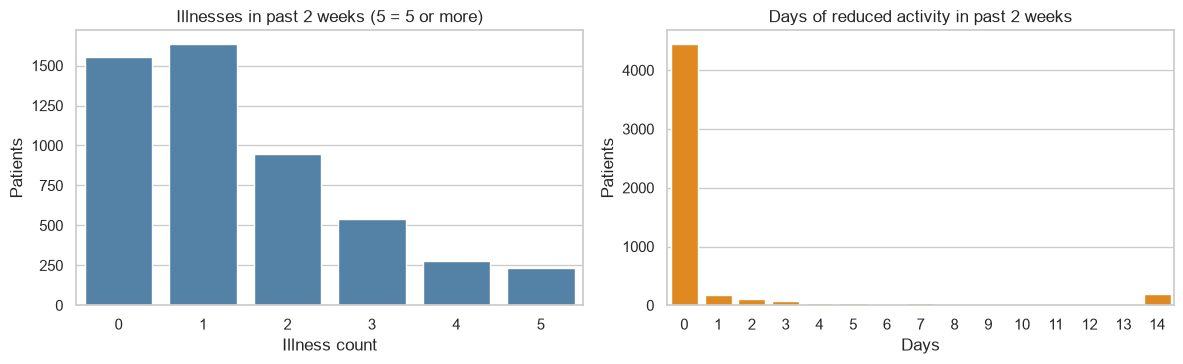

n = 5190
Spearman rho = 0.272 (95% bootstrap CI 0.249 to 0.293), p = 1.83e-88  -> weak (rule of thumb)
Pearson  r   = 0.218, p = 6.19e-57  (for comparison only)

The p-value answers: 'if there were truly no monotonic association, how surprising is a rho this large?'
It does not say how strong or important the association is. Use rho for that.

Supplementary: Spearman between health (higher = worse) and reduced: rho = 0.236, p = 7.74e-67, n = 5190


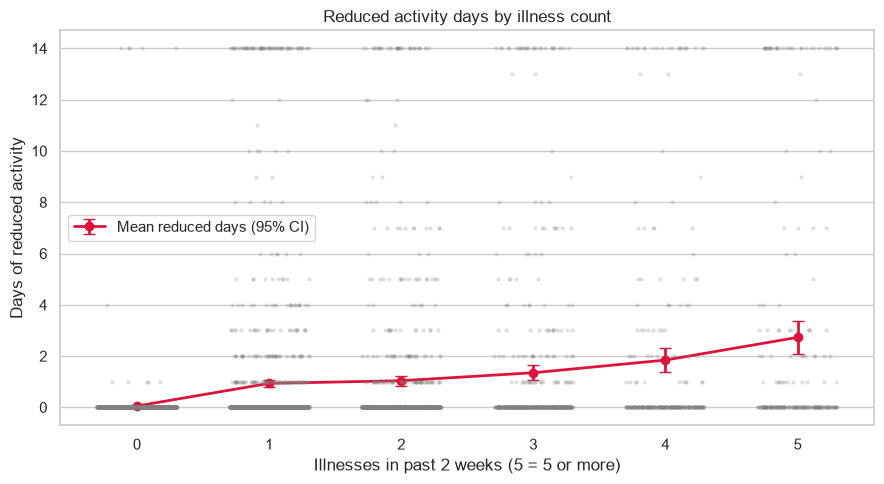

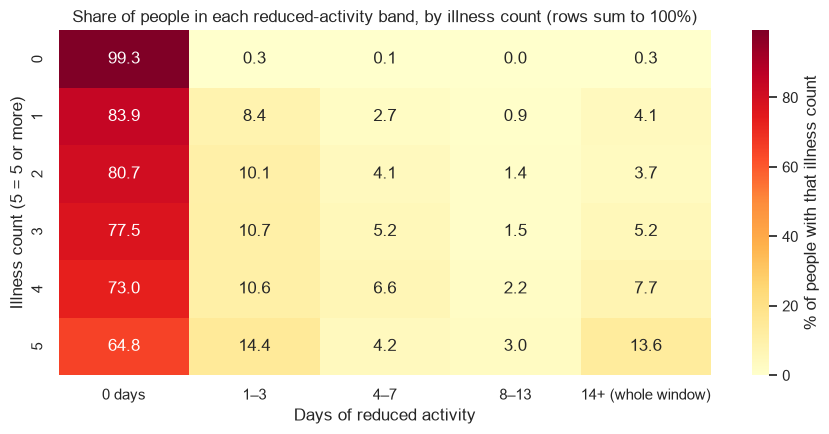

         patients  mean_days  median_days  sd_days  % any reduced days  % 14+ days small group
illness                                                                                       
0            1554      0.051          0.0    0.801               0.708       0.322            
1            1638      0.935          0.0    3.000              16.056       4.090            
2             946      1.038          0.0    3.014              19.345       3.700            
3             542      1.349          0.0    3.447              22.509       5.166            
4             274      1.843          0.0    4.052              27.007       7.664            
5             236      2.729          0.0    4.955              35.169      13.559            

Kruskal-Wallis: H = 415.19, df = 5, p = 1.58e-87; epsilon-squared = 0.079 (medium, rule of thumb)


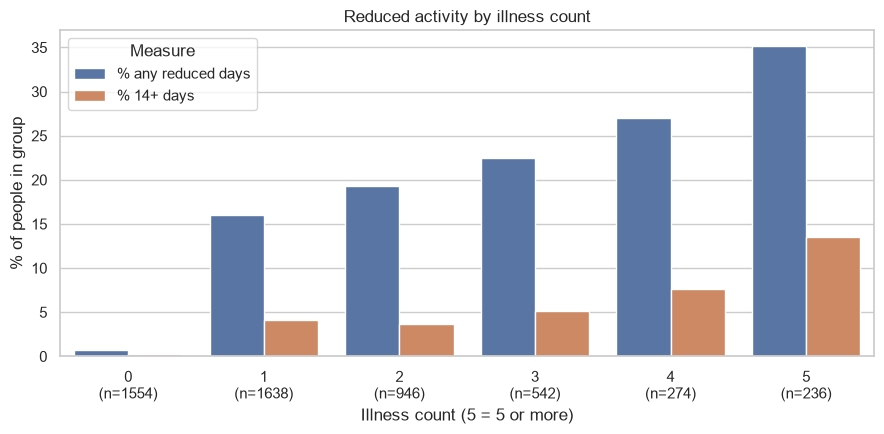

--- by 'lchronic' ---
          patients  mean_days  pct_whole_window
lchronic                                       
no            4585       0.63              2.29
yes            605       2.58             13.72 

--- by 'nchronic' ---
          patients  mean_days  pct_whole_window
nchronic                                       
no            3098       0.87              3.71
yes           2092       0.85              3.49 

What the variables mean: illness = number of illnesses in the past 2 weeks (5 = 5 or more);
reduced = days of reduced activity in the past 2 weeks due to illness or injury (0 to 14).

Descriptives: n = 5190. The average person reports 1.43 illnesses and
0.86 reduced-activity days, but 85.8% report 0 reduced days and 3.6% report the
whole window (14 days). The distribution has two spikes (0 and 14), which is why the mean alone is
misleading and a straight-line (Pearson) summary fits poorly.

Relationship: Spearman rho = 0.27 (95% CI 0.25 to 0.29, p = 1.83e-88), a

In [22]:
# %% [markdown]
# # Illness Burden and Reduced Activity
#
# **Question:** Do people reporting more illnesses also report more days of reduced activity?
#
# ## What the columns mean (checked against published documentation)
# The column names match the Australian Health Survey 1977–78 data (documented in the R packages
# `Ecdat::DoctorAUS` and `faraway::dvisits`, where the original names are `illness`, `actdays`, `hscore`):
#
# | Column | Documented meaning | Notes |
# |---|---|---|
# | `illness` | Number of illnesses in the **past 2 weeks** | **5 or more is coded as 5**, so 5 means "5+" (a top-coded count) |
# | `reduced` | Number of **days of reduced activity in the past 2 weeks** due to **illness or injury** | Two-week window, so the largest possible value is 14 days |
# | `health` | General Health Questionnaire score (Goldberg's method), 0–12 | **Higher score = worse health** |
#
# Two points to keep in mind:
# - `reduced` counts days lost to *illness or injury*, but `illness` counts only illnesses. A person can
#   therefore have reduced activity without a counted illness (for example after an injury).
# - The mapping from the original variable names (`actdays`, `hscore`) to this CSV's names (`reduced`, `health`)
#   rests on matching meaning and value ranges. Check it against your own data dictionary.
#
# The results show **associations**, not proof that illness *caused* reduced activity.

ILLNESS_COL, REDUCED_COL, HEALTH_COL = "illness", "reduced", "health"
ILLNESS_RANGE = (0, 5)     # documented: 5 means "5 or more"
REDUCED_RANGE = (0, 14)    # 2-week window
HEALTH_RANGE = (0, 12)     # documented GHQ range (higher = worse)
MIN_GROUP_N = 30           # warn if a group is smaller than this
N_BOOT, SEED, ALPHA = 2000, 42, 0.05

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)

# %% [markdown]
# ## 1. Inspect the columns and handle missing or unusual values

# %%
for c in (ILLNESS_COL, REDUCED_COL, HEALTH_COL):
    assert c in df.columns, f"Column '{c}' not found. Available: {list(df.columns)}"

raw = df[[ILLNESS_COL, REDUCED_COL, HEALTH_COL]].copy()
print("Data types:\n", raw.dtypes.to_string(), "\n")
print("Missing values before cleaning:\n", raw.isna().sum().to_string(), "\n")

# Convert to numbers; anything that cannot be converted becomes missing (NaN)
for c in raw.columns:
    raw[c] = pd.to_numeric(raw[c], errors="coerce")

# The main analysis needs illness AND reduced; health is only used in a supplementary check
data = raw.dropna(subset=[ILLNESS_COL, REDUCED_COL]).copy()
print(f"Rows in df: {len(raw)} | dropped (missing illness or reduced): {len(raw) - len(data)} | analysed: {len(data)}")

# Range checks: warn, never silently change values
for col, (lo, hi) in {ILLNESS_COL: ILLNESS_RANGE, REDUCED_COL: REDUCED_RANGE, HEALTH_COL: HEALTH_RANGE}.items():
    s = data[col].dropna()
    outside = int(((s < lo) | (s > hi)).sum())
    integer = bool(np.allclose(s, s.round()))
    print(f"{col:<8} observed range {s.min():g} to {s.max():g} | documented {lo} to {hi} | "
          f"outside range: {outside} | whole numbers: {integer}")
    if outside:
        print(f"  WARNING: {outside} '{col}' values are outside the documented range; check coding.")

# %% [markdown]
# ### Unusual patterns worth knowing about before analysing

# %%
full_window = REDUCED_RANGE[1]
n = len(data)
n_zero = int((data[REDUCED_COL] == 0).sum())
n_full = int((data[REDUCED_COL] >= full_window).sum())
n_mid = n - n_zero - n_full
print(f"reduced = 0 days        : {n_zero:>5} ({n_zero / n:.1%})")
print(f"reduced = 1 to {full_window - 1} days    : {n_mid:>5} ({n_mid / n:.1%})")
print(f"reduced = {full_window} days (whole window): {n_full:>5} ({n_full / n:.1%})")

no_illness = data[data[ILLNESS_COL] == 0]
n_ni_red = int((no_illness[REDUCED_COL] > 0).sum())
print(f"\nPeople with illness = 0: {len(no_illness)}; of these, {n_ni_red} "
      f"({n_ni_red / max(len(no_illness), 1):.1%}) report reduced activity days.")
print("Reminder: 'reduced' also covers injury, so this can happen. The data alone cannot tell us why.")
print(f"illness = {ILLNESS_RANGE[1]} is a top-coded group ('{ILLNESS_RANGE[1]} or more').")

# %% [markdown]
# ## 2. Descriptive statistics

# %%
def describe_col(s):
    return pd.Series({
        "n": s.count(), "mean": s.mean(), "median": s.median(), "std": s.std(),
        "min": s.min(), "max": s.max(), "% zeros": (s == 0).mean() * 100,
        "skewness": stats.skew(s), "most common value": s.mode().iloc[0],
    })


desc = pd.DataFrame({
    f"{ILLNESS_COL} (illness count)": describe_col(data[ILLNESS_COL]),
    f"{REDUCED_COL} (days reduced activity)": describe_col(data[REDUCED_COL]),
}).round(3)
print(desc.to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.countplot(x=data[ILLNESS_COL].astype(int), color="steelblue", ax=axes[0])
axes[0].set(title="Illnesses in past 2 weeks (5 = 5 or more)", xlabel="Illness count", ylabel="Patients")
sns.countplot(x=data[REDUCED_COL].astype(int), color="darkorange", ax=axes[1])
axes[1].set(title="Days of reduced activity in past 2 weeks", xlabel="Days", ylabel="Patients")
plt.tight_layout()
plt.show()

# %% [markdown]
# ## 3. Relationship between illness count and reduced activity: correlation
#
# **Which correlation?**
# - **Pearson** measures a *straight-line* relationship and is sensitive to extreme values. `reduced` is mostly
#   zeros with a pile-up at the maximum, and `illness` is a small, top-coded count, so the assumptions behind
#   Pearson are a poor fit.
# - **Spearman** works on ranks and measures whether higher values of one variable tend to go with higher values of
#   the other (a *monotonic* relationship). It does not need normal data or a straight line, and it handles
#   ordered counts, so it is the **primary** measure here.
# - Pearson is shown only for comparison.

# %%
rho, p_rho = stats.spearmanr(data[ILLNESS_COL], data[REDUCED_COL])
r, p_r = stats.pearsonr(data[ILLNESS_COL], data[REDUCED_COL])

# Bootstrap confidence interval for Spearman's rho (resample patients with replacement)
rng = np.random.default_rng(SEED)
a, b = data[ILLNESS_COL].to_numpy(), data[REDUCED_COL].to_numpy()
boot = [stats.spearmanr(a[i], b[i])[0] for i in (rng.integers(0, len(a), len(a)) for _ in range(N_BOOT))]
ci = np.percentile(boot, [100 * ALPHA / 2, 100 * (1 - ALPHA / 2)])


def strength(x):
    x = abs(x)
    return "negligible" if x < 0.1 else "weak" if x < 0.3 else "moderate" if x < 0.5 else "strong"


print(f"n = {len(data)}")
print(f"Spearman rho = {rho:.3f} (95% bootstrap CI {ci[0]:.3f} to {ci[1]:.3f}), p = {p_rho:.3g}  -> {strength(rho)} (rule of thumb)")
print(f"Pearson  r   = {r:.3f}, p = {p_r:.3g}  (for comparison only)")
print(f"\nThe p-value answers: 'if there were truly no monotonic association, how surprising is a rho this large?'")
print("It does not say how strong or important the association is. Use rho for that.")

# Supplementary: reduced activity vs the GHQ health score (higher score = worse health)
sub = raw.dropna(subset=[HEALTH_COL, REDUCED_COL])
rho_h, p_h = stats.spearmanr(sub[HEALTH_COL], sub[REDUCED_COL])
print(f"\nSupplementary: Spearman between {HEALTH_COL} (higher = worse) and {REDUCED_COL}: "
      f"rho = {rho_h:.3f}, p = {p_h:.3g}, n = {len(sub)}")

# %% [markdown]
# ## 4. Visualising the relationship
# Because both variables are whole numbers, plain scatterplot points sit on top of each other. We therefore
# **jitter** the points (shift them slightly) and draw the **average reduced days at each illness count with a 95%
# confidence interval** as the trend line. A straight regression line is deliberately not used, because the
# relationship is not clearly linear and the data pile up at 0 and at the maximum.

# %%
levels = sorted(data[ILLNESS_COL].unique())
by_level = data.groupby(ILLNESS_COL)[REDUCED_COL].agg(n="count", mean="mean", sd="std")
by_level["sem"] = by_level["sd"] / np.sqrt(by_level["n"])
by_level["ci95"] = stats.t.ppf(1 - ALPHA / 2, (by_level["n"] - 1).clip(lower=1)) * by_level["sem"]

fig, ax = plt.subplots(figsize=(9, 5))
sns.stripplot(data=data, x=ILLNESS_COL, y=REDUCED_COL, order=levels, jitter=0.3, alpha=0.25, size=3,
              color="gray", ax=ax)
ax.errorbar(range(len(levels)), by_level["mean"], yerr=by_level["ci95"], fmt="-o", color="crimson",
            capsize=4, lw=2, label="Mean reduced days (95% CI)")
ax.set(title="Reduced activity days by illness count",
       xlabel="Illnesses in past 2 weeks (5 = 5 or more)", ylabel="Days of reduced activity")
ax.legend()
plt.tight_layout()
plt.show()

# %%
# Heatmap: for each illness count, what share of people fall into each band of reduced-activity days?
band_edges = [-np.inf, 0, 3, 7, REDUCED_RANGE[1] - 1, np.inf]
band_labels = ["0 days", "1–3", "4–7", f"8–{REDUCED_RANGE[1] - 1}", f"{REDUCED_RANGE[1]}+ (whole window)"]
data["reduced_band"] = pd.cut(data[REDUCED_COL], bins=band_edges, labels=band_labels)
heat = pd.crosstab(data[ILLNESS_COL], data["reduced_band"], normalize="index") * 100

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(heat, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "% of people with that illness count"}, ax=ax)
ax.set(title="Share of people in each reduced-activity band, by illness count (rows sum to 100%)",
       xlabel="Days of reduced activity", ylabel="Illness count (5 = 5 or more)")
plt.tight_layout()
plt.show()

# %% [markdown]
# ## 5. Comparing reduced activity across illness-count groups
# The table reports sample sizes and several summaries. Because most people report 0 days, the **share with any
# reduced days** and the **share with the whole window affected** are often more informative than the median.
# **Kruskal–Wallis** tests whether the distributions of reduced days differ across the groups (rank-based, so no
# normality is needed). **ε² (epsilon-squared)** is its effect size (about the share of rank variation linked to group).

# %%
g = data.groupby(ILLNESS_COL)[REDUCED_COL]
group_table = pd.DataFrame({
    "patients": g.count(),
    "mean_days": g.mean(),
    "median_days": g.median(),
    "sd_days": g.std(),
    "% any reduced days": g.apply(lambda s: (s > 0).mean() * 100),
    f"% {REDUCED_RANGE[1]}+ days": g.apply(lambda s: (s >= REDUCED_RANGE[1]).mean() * 100),
}).round(3)
group_table["small group"] = np.where(group_table["patients"] < MIN_GROUP_N, f"n<{MIN_GROUP_N}", "")
print(group_table.to_string())
if (group_table["patients"] < MIN_GROUP_N).any():
    print("\nWARNING: some groups are small; interpret their averages with caution.")

samples = [grp[REDUCED_COL].to_numpy() for _, grp in data.groupby(ILLNESS_COL)]
k, n_total = len(samples), len(data)
kw = stats.kruskal(*samples)
eps2 = max(0.0, (kw.statistic - k + 1) / (n_total - k))
eps_label = "negligible" if eps2 < 0.01 else "small" if eps2 < 0.06 else "medium" if eps2 < 0.14 else "large"
print(f"\nKruskal-Wallis: H = {kw.statistic:.2f}, df = {k - 1}, p = {kw.pvalue:.3g}; epsilon-squared = {eps2:.3f} ({eps_label}, rule of thumb)")

# %%
plot_df = group_table[["% any reduced days", f"% {REDUCED_RANGE[1]}+ days"]].reset_index().melt(
    id_vars=ILLNESS_COL, var_name="Measure", value_name="% of group")
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=plot_df, x=ILLNESS_COL, y="% of group", hue="Measure", ax=ax)
ax.set_xticks(range(len(levels)))
ax.set_xticklabels([f"{int(lv)}\n(n={int(group_table.loc[lv, 'patients'])})" for lv in levels])
ax.set(title="Reduced activity by illness count", xlabel="Illness count (5 = 5 or more)", ylabel="% of people in group")
plt.tight_layout()
plt.show()

# %% [markdown]
# ## 6. Optional check on the pile-up at the maximum
# Many people report reduced activity on *every* day of the window. A quick look at whether this is linked
# to the chronic-condition columns (if present) can help explain it. This is descriptive only.

# %%
for chronic_col in ("lchronic", "nchronic"):
    if chronic_col in df.columns:
        tmp = df.loc[data.index, [chronic_col]].join(data[REDUCED_COL])
        tab = tmp.groupby(chronic_col)[REDUCED_COL].agg(
            patients="count", mean_days="mean",
            pct_whole_window=lambda s: (s >= REDUCED_RANGE[1]).mean() * 100).round(2)
        print(f"--- by '{chronic_col}' ---")
        print(tab.to_string(), "\n")

# %% [markdown]
# ## 7. Interpretation (generated from the output above)

# %%
lo_lv, hi_lv = levels[0], levels[-1]
lo, hi = group_table.loc[lo_lv], group_table.loc[hi_lv]
all_medians_zero = bool((group_table["median_days"] == 0).all())
direction = "positive" if rho > 0 else "negative"
steps_down = [f"{levels[i - 1]:g}->{levels[i]:g}" for i in range(1, len(levels))
              if group_table["mean_days"].iloc[i] < group_table["mean_days"].iloc[i - 1]]

print(f"""What the variables mean: illness = number of illnesses in the past 2 weeks (5 = 5 or more);
reduced = days of reduced activity in the past 2 weeks due to illness or injury (0 to {REDUCED_RANGE[1]}).

Descriptives: n = {len(data)}. The average person reports {data[ILLNESS_COL].mean():.2f} illnesses and
{data[REDUCED_COL].mean():.2f} reduced-activity days, but {n_zero / n:.1%} report 0 reduced days and {n_full / n:.1%} report the
whole window ({REDUCED_RANGE[1]} days). The distribution has two spikes (0 and {REDUCED_RANGE[1]}), which is why the mean alone is
misleading and a straight-line (Pearson) summary fits poorly.

Relationship: Spearman rho = {rho:.2f} (95% CI {ci[0]:.2f} to {ci[1]:.2f}, p = {p_rho:.3g}), a {strength(rho)} {direction}
association: people reporting more illnesses tend to report more days of reduced activity. Pearson r = {r:.2f} points the same way.

Groups: average reduced days go from {lo['mean_days']:.2f} (illness = {lo_lv:g}, n = {int(lo['patients'])}) to {hi['mean_days']:.2f}
(illness = {hi_lv:g}, n = {int(hi['patients'])}); the share with any reduced day goes from {lo['% any reduced days']:.1f}% to
{hi['% any reduced days']:.1f}%. {'Averages never fall as illness count rises.' if not steps_down else 'Averages dip at: ' + ', '.join(steps_down) + '.'}
{'The median is 0 in every group, so differences show up in the tail (the share with reduced days), not the typical person.' if all_medians_zero else 'Medians differ across groups; see the table.'}
Kruskal-Wallis p = {kw.pvalue:.3g}, epsilon-squared = {eps2:.3f} ({eps_label}). A small p-value only says the groups are unlikely
to be identical; epsilon-squared and the actual differences in days tell you how much they differ.

Unusual finding: {n_ni_red} of {len(no_illness)} people with 0 counted illnesses still report reduced days. Because 'reduced' includes
injury, this is possible, but the data cannot confirm the reason.

Association is not causation: these results do not show that illness caused the reduced activity. See the notes below.""")

# %% [markdown]
# ## 8. Association does not prove causation
#
# - **Direction is unclear from the data.** Illness may reduce activity, but how people count and report
#   illness may also depend on how much their activity has been affected. Both were reported by the same
#   person for the same 2-week period.
# - **Other factors may drive both.** Age, long-term chronic conditions, and general health can raise both the
#   number of reported illnesses and the days of reduced activity. This analysis does not adjust for them.
# - **Measurement limits.** Both variables are self-reported counts from a short recall window. `illness` is
#   capped at 5, which hides differences among people with many illnesses, and a pile-up at 14 days
#   suggests some people were affected throughout the window (possibly long-term limitation, which the optional
#   check above only hints at).
# - **Illness vs injury.** `reduced` includes injury, but `illness` does not count injuries, so the two
#   measures are not perfectly matched.
# - **Sample.** The survey is from 1977–78, covers single adults, and oversampled young and old people, so
#   unweighted results may not generalise.
# - **Next step.** A count model (for example negative binomial, or a two-part model for "any reduced days" and
#   "how many") adjusting for age, sex, income and chronic conditions would show whether the association remains
#   after accounting for these factors.

## 20. Multiple regression analysis

statsmodels version: 0.14.6
Shape: (5190, 13)

              dtype  n_missing  n_unique                      example_values
Unnamed: 0    int64          0      5190                    1, 2, 3, 4, 5, 6
visits        int64          0        10                    1, 2, 3, 4, 8, 5
gender          str          0         2                        female, male
age         float64          0        12  0.19, 0.22, 0.27, 0.32, 0.37, 0.42
income      float64          0        14   0.55, 0.45, 0.9, 0.15, 0.35, 0.65
illness       int64          0         6                    1, 3, 2, 5, 4, 0
reduced       int64          0        15                   4, 2, 0, 5, 1, 13
health        int64          0        13                    1, 0, 9, 2, 6, 5
private         str          0         2                             yes, no
freepoor        str          0         2                             no, yes
freerepat       str          0         2                             no, yes
nchronic        str          

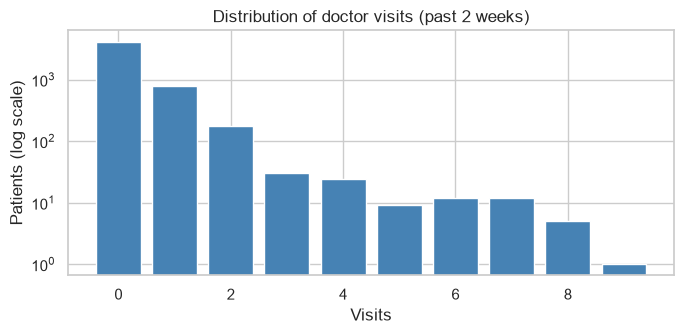

Excluded columns: {'Unnamed: 0': 'row identifier', 'visits': 'target (outcome)'}
Predictors used: ['age', 'gender', 'income', 'illness', 'health', 'reduced', 'private', 'freepoor', 'freerepat', 'nchronic', 'lchronic']
Rows before: 5190 | removed for missing values: 0 | kept: 5190
age (stored as years/100): observed range 0.19 to 0.72
income ($10,000 units): observed range 0.00 to 1.50
Encoded 'gender': reference = 'female', dummy columns = ['gender_male']
Encoded 'private': reference = 'no', dummy columns = ['private_yes']
Encoded 'freepoor': reference = 'no', dummy columns = ['freepoor_yes']
Encoded 'freerepat': reference = 'no', dummy columns = ['freerepat_yes']
Encoded 'nchronic': reference = 'no', dummy columns = ['nchronic_yes']
Encoded 'lchronic': reference = 'no', dummy columns = ['lchronic_yes']

Rows with more than one insurance flag = yes: 0
If 0, the flags are mutually exclusive categories and the reference group is 'none of these' (no private fund and no free government cov

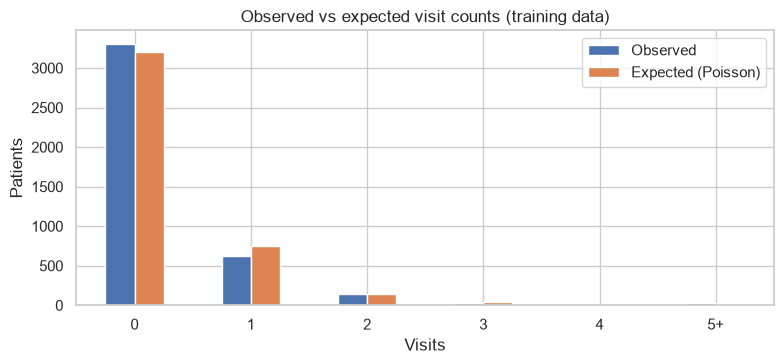

Poisson Pearson residual SD = 1.16 (about 1 expected if the variance is right)


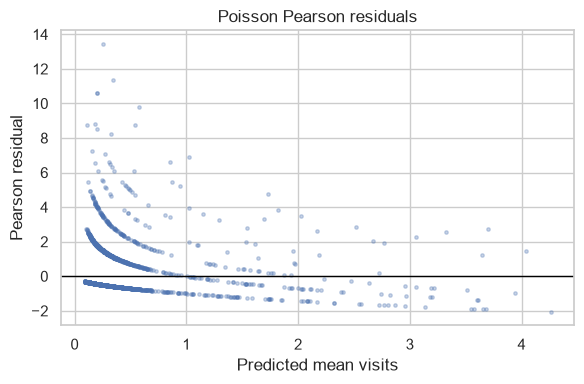

Residuals of count data form bands (because y is a whole number). Look for a funnel shape or a curve, which suggest wrong variance or missing non-linear effects; a few large positive residuals are expected for rare high counts.

Largest Cook's distances (Poisson, training data):
     cooks_d  visits  income  illness  health  reduced  age_decades  gender_male  private_yes  freepoor_yes  freerepat_yes  nchronic_yes  lchronic_yes
114    0.130     7.0    0.00      1.0     1.0     14.0          2.2          1.0          0.0           1.0            0.0           1.0           0.0
629    0.079     8.0    1.50      1.0     1.0     14.0          6.2          0.0          1.0           0.0            0.0           0.0           0.0
598    0.065     8.0    0.01      1.0     4.0      9.0          5.7          1.0          0.0           0.0            0.0           0.0           0.0
197    0.064     5.0    0.45      3.0    10.0      5.0          2.2          0.0          0.0           1.0         

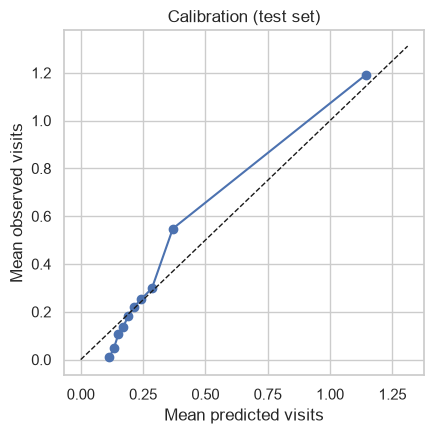

Poisson is the working model but overdispersion was found, so ROBUST standard errors are used for intervals and p-values.
Final table (poisson model, training data), ordered by size of effect on a comparable scale:
                           unit / comparison     IRR  IRR 95% CI low  IRR 95% CI high  p_value  p (Holm-adjusted)  IRR (comparable scale)  |log IRR| rank
reduced                           per +1 day  1.1333          1.1144           1.1526   0.0000             0.0000                  1.4367               1
illness                       per +1 illness  1.2187          1.1574           1.2832   0.0000             0.0000                  1.3155               2
freepoor_yes                       yes vs no  0.8124          0.4629           1.4255   0.4689             1.0000                  0.8124               3
lchronic_yes                       yes vs no  1.2238          0.9532           1.5713   0.1133             0.9060                  1.2238               4
private_yes    

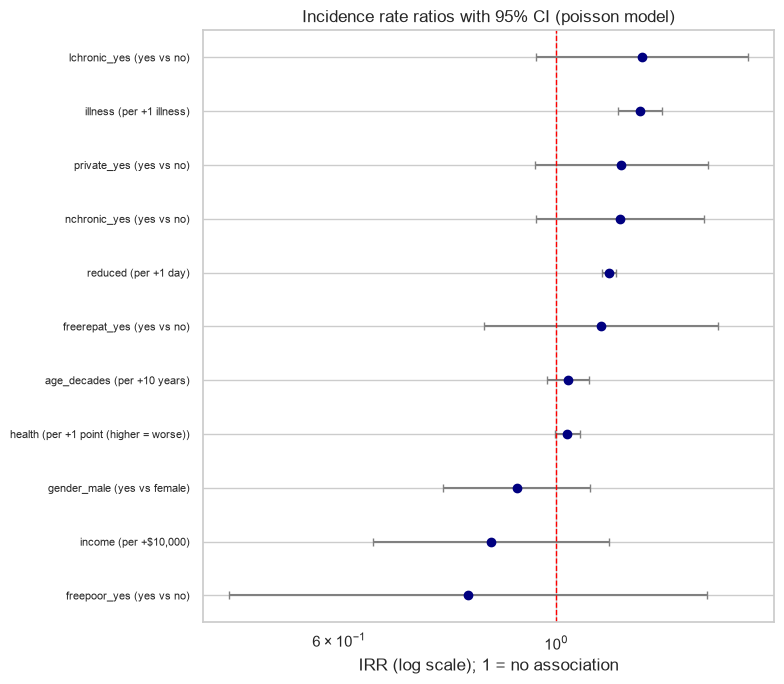

Coefficient stability (train vs all rows):
               IRR train  IRR all rows  p train  p all rows
income            0.8576        0.8291   0.2772      0.1366
illness           1.2187        1.2046   0.0000      0.0000
health            1.0264        1.0312   0.0822      0.0306
reduced           1.1333        1.1351   0.0000      0.0000
age_decades       1.0280        1.0283   0.2669      0.2039
gender_male       0.9116        0.8551   0.2951      0.0484
private_yes       1.1656        1.1348   0.1413      0.1814
freepoor_yes      0.8124        0.6450   0.4689      0.1301
freerepat_yes     1.1113        1.0872   0.4528      0.5049
nchronic_yes      1.1630        1.1245   0.1343      0.1931
lchronic_yes      1.2238        1.1627   0.1133      0.2083

Sensitivity: dropping ['illness', 'health', 'reduced']
               IRR full model  IRR without health-status vars  p full  p without
income                 0.8576                          0.7731  0.2772     0.0839
age_decades        

In [23]:
# %% [markdown]
# # Multivariable Analysis: Which Patient Characteristics Are Associated with Doctor Visits?
#
# **Goal:** estimate how several patient characteristics are *jointly* associated with the number of doctor
# visits (`visits`) in the past 2 weeks, using **Poisson regression** and, if the data call for it,
# **negative binomial regression**.

from scipy import stats
import statsmodels.api as sm

TARGET = "visits"
PREDICTOR_CANDIDATES = ["age", "gender", "income", "illness", "health", "reduced",
                        "private", "freepoor", "freerepat", "nchronic", "lchronic"]
NUMERIC_COLS = ["age", "income", "illness", "health", "reduced"]
# categorical column -> reference level (the group every other group is compared with)
CATEGORICAL_REFERENCE = {"gender": "female", "private": "no", "freepoor": "no",
                         "freerepat": "no", "nchronic": "no", "lchronic": "no"}

ALPHA = 0.05          # significance level
TEST_SIZE = 0.20      # share of rows held out for the final evaluation
SEED = 42             # makes the random split reproducible

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
print("statsmodels version:", sm.__version__)

# %% [markdown]
# ## 1. Inspect the data
# Before modelling we check data types, missing values, unique values and the shape of the target.

# %%
print(f"Shape: {df.shape}\n")
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_missing": df.isna().sum(),
    "n_unique": df.nunique(),
    "example_values": [", ".join(map(str, df[c].dropna().unique()[:6])) for c in df.columns],
})
print(overview.to_string())

missing_cols = [c for c in [TARGET] + PREDICTOR_CANDIDATES if c not in df.columns]
if missing_cols:
    print(f"\nWARNING: these expected columns are NOT in df and will be skipped: {missing_cols}")

print("\nUnique values of the categorical columns:")
for c in CATEGORICAL_REFERENCE:
    if c in df.columns:
        print(f"  {c}: {df[c].value_counts(dropna=False).to_dict()}")

print(f"\nExact duplicate rows (ignoring any ID column): {int(df.drop(columns=[c for c in df.columns if str(c).startswith('Unnamed')], errors='ignore').duplicated().sum())}")
print("(Duplicates are expected when many people share the same small set of answers; they are not removed.)")

# %% [markdown]
# ### Target distribution
# A count outcome should be a non-negative whole number. For a **Poisson** model the mean and variance should be about equal.

# %%
y_all = pd.to_numeric(df[TARGET], errors="coerce")
print("Missing / non-numeric target values:", int(y_all.isna().sum()))
assert (y_all.dropna() >= 0).all() and np.allclose(y_all.dropna(), y_all.dropna().round()), \
    "Target must be non-negative whole numbers for count models."

print(f"mean = {y_all.mean():.3f}, variance = {y_all.var():.3f}, variance/mean = {y_all.var() / y_all.mean():.2f}")
print(f"% zeros = {(y_all == 0).mean() * 100:.1f}%, max = {int(y_all.max())}")
print("(variance/mean above 1 before adjusting for any predictors already hints at overdispersion.)")

vc = y_all.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(vc.index.astype(int), vc.values, color="steelblue")
ax.set(title="Distribution of doctor visits (past 2 weeks)", xlabel="Visits", ylabel="Patients")
ax.set_yscale("log")
ax.set_ylabel("Patients (log scale)")
plt.tight_layout()
plt.show()

# %% [markdown]
# ## 2. Choose predictors: exclude identifiers and non-informative columns
# Row identifiers (for example an unnamed index column), constant columns and the target itself must not be
# used as predictors. An ID is just a row number; using it would add noise and could even create spurious patterns.

# %%
def looks_like_identifier(s: pd.Series, name) -> bool:
    name_l = str(name).strip().lower()
    if name_l in {"", "id", "index", "rownames", "row", "row_id"} or name_l.startswith("unnamed"):
        return True
    if pd.api.types.is_integer_dtype(s) and s.is_unique and (s.is_monotonic_increasing or s.is_monotonic_decreasing):
        return True  # a unique, sorted integer column behaves like a row number
    return False


excluded = {}
for c in df.columns:
    if c == TARGET:
        excluded[c] = "target (outcome)"
    elif looks_like_identifier(df[c], c):
        excluded[c] = "row identifier"
    elif df[c].nunique(dropna=True) <= 1:
        excluded[c] = "constant (no information)"
print("Excluded columns:", excluded if excluded else "none")

predictors = [c for c in PREDICTOR_CANDIDATES if c in df.columns and c not in excluded]
other_unused = [c for c in df.columns if c not in predictors and c not in excluded]
print("Predictors used:", predictors)
if other_unused:
    print("Columns present but not in the predictor list (ignored):", other_unused)
assert TARGET not in predictors, "The target must never be a predictor."

# %% [markdown]
# ## 3. Prepare the predictors
# - **Numeric** predictors are converted to numbers. `age` is converted to decades so that one unit is meaningful;
#   `income` is already in $10,000 units.
# - **Categorical** predictors are cleaned (trimmed, lower-case) and turned into **0/1 dummy variables**. One group is
#   the **reference** (coded 0), and each coefficient compares a group with that reference.
# - Rows with a missing value in any used column are removed (**complete-case analysis**), and the count is reported.

# %%
work = df[[TARGET] + predictors].copy()
work[TARGET] = pd.to_numeric(work[TARGET], errors="coerce")

for c in [c for c in NUMERIC_COLS if c in predictors]:
    work[c] = pd.to_numeric(work[c], errors="coerce")

for c in [c for c in CATEGORICAL_REFERENCE if c in predictors]:
    s = work[c].astype("object")
    work[c] = s.where(s.isna(), s.astype(str).str.strip().str.lower())

n_before = len(work)
work = work.dropna()
print(f"Rows before: {n_before} | removed for missing values: {n_before - len(work)} | kept: {len(work)}")

# Sanity checks on units described in the documentation
if "age" in predictors:
    print(f"age (stored as years/100): observed range {work['age'].min():.2f} to {work['age'].max():.2f}")
    if work["age"].max() > 1.5:
        print("WARNING: age looks like it is already in years; the decade conversion below may be wrong.")
    work["age_decades"] = work["age"] * 10   # years/100 * 10 = decades
    work = work.drop(columns="age")
if "income" in predictors:
    print(f"income ($10,000 units): observed range {work['income'].min():.2f} to {work['income'].max():.2f}")

# Dummy-encode categorical predictors
dummy_cols = []
for c, ref in CATEGORICAL_REFERENCE.items():
    if c not in predictors:
        continue
    levels = sorted(work[c].unique())
    if ref not in levels:
        raise ValueError(f"Reference level '{ref}' not found in '{c}'. Levels present: {levels}")
    for lv in levels:
        if lv == ref:
            continue
        name = f"{c}_{lv}"
        work[name] = (work[c] == lv).astype(float)
        dummy_cols.append(name)
    work = work.drop(columns=c)
    print(f"Encoded '{c}': reference = '{ref}', dummy columns = {[d for d in dummy_cols if d.startswith(c + '_')]}")

# Check how the insurance and chronic-condition flags overlap (affects how coefficients are read)
cov_flags = [c for c in ("private_yes", "freepoor_yes", "freerepat_yes") if c in work]
chr_flags = [c for c in ("nchronic_yes", "lchronic_yes") if c in work]
if len(cov_flags) > 1:
    print(f"\nRows with more than one insurance flag = yes: {int((work[cov_flags].sum(axis=1) > 1).sum())}")
    print("If 0, the flags are mutually exclusive categories and the reference group is 'none of these' "
          "(no private fund and no free government cover).")
if len(chr_flags) > 1:
    print(f"Rows with both chronic flags = yes: {int((work[chr_flags].sum(axis=1) > 1).sum())}")
    print("If 0, the reference group is 'no chronic condition' and each flag compares that type of condition with none.")

feature_cols = [c for c in work.columns if c != TARGET]
X_all = work[feature_cols].astype(float)
y_all = work[TARGET].astype(float)
print(f"\nFinal feature columns ({len(feature_cols)}): {feature_cols}")

# %% [markdown]
# ## 4. Train/test split (done BEFORE any model is fitted)
# The model is learned from the **training** rows only. The **test** rows are untouched until the final check,
# which gives an honest estimate of how well the model predicts new people. No statistics from the test rows
# are used for any choice (no scaling, no variable selection), which avoids leakage.

# %%
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(X_all))
n_test = int(round(TEST_SIZE * len(X_all)))
test_idx, train_idx = perm[:n_test], perm[n_test:]
X_train, X_test = X_all.iloc[train_idx], X_all.iloc[test_idx]
y_train, y_test = y_all.iloc[train_idx], y_all.iloc[test_idx]
print(f"Train: {len(X_train)} rows, mean visits {y_train.mean():.3f} | Test: {len(X_test)} rows, mean visits {y_test.mean():.3f}")

# Rare binary groups give unstable estimates; check their sizes in the training data
bin_cols = [c for c in feature_cols if set(X_train[c].unique()) <= {0.0, 1.0}]
rare = {c: int(X_train[c].sum()) for c in bin_cols if X_train[c].sum() < 100}
print("Binary predictors with fewer than 100 'yes' rows in the training set (wide intervals expected):", rare or "none")

# %% [markdown]
# ### Multicollinearity check (variance inflation factors)
# If predictors are strongly related, their individual coefficients become unstable. A common rule of thumb is that
# a VIF above about 5–10 is a concern.

# %%
def vif_table(X: pd.DataFrame) -> pd.Series:
    """VIF_j = 1 / (1 - R^2) from regressing predictor j on all the other predictors."""
    out = {}
    A = X.to_numpy(float)
    for j, c in enumerate(X.columns):
        others = np.delete(A, j, axis=1)
        Z = np.column_stack([np.ones(len(A)), others])
        coef, *_ = np.linalg.lstsq(Z, A[:, j], rcond=None)
        resid = A[:, j] - Z @ coef
        r2 = 1 - resid.var() / A[:, j].var() if A[:, j].var() > 0 else np.nan
        out[c] = 1 / (1 - r2) if r2 < 1 else np.inf
    return pd.Series(out, name="VIF").round(2)


print(vif_table(X_train).to_string())

# %% [markdown]
# ## 5. Baseline model: Poisson regression
# **Model:** `log(expected visits) = b0 + b1*x1 + b2*x2 + ...`
#
# - Each coefficient `b` is a change in the **log** of the expected number of visits.
# - `exp(b)` is the **incidence rate ratio (IRR)**: the multiplicative change in the expected visit count for a
#   1-unit increase in a numeric predictor (or for "yes" versus the reference group), *holding the other predictors fixed*.
#   IRR = 1 means no association, IRR = 1.20 means 20% higher, IRR = 0.80 means 20% lower.
# - Poisson assumes the variance of visits equals its mean (given the predictors). We test this next.

# %%
def add_const(X):
    return sm.add_constant(X, has_constant="add")


def fit_poisson(y, X, cov_type=None):
    model = sm.GLM(y, add_const(X), family=sm.families.Poisson())
    return model.fit() if cov_type is None else model.fit(cov_type=cov_type)


def irr_table(res, drop=("const", "alpha")):
    """Coefficients -> incidence rate ratios with confidence intervals and p-values."""
    ci = res.conf_int()
    out = pd.DataFrame({
        "coef (log scale)": res.params,
        "std_err": res.bse,
        "IRR": np.exp(res.params),
        "IRR 95% CI low": np.exp(ci.iloc[:, 0]),
        "IRR 95% CI high": np.exp(ci.iloc[:, 1]),
        "% change": (np.exp(res.params) - 1) * 100,
        "p_value": res.pvalues,
    })
    return out.drop(index=[d for d in drop if d in out.index])


try:
    pois_res = fit_poisson(y_train, X_train)
except Exception as exc:  # the baseline is required, so stop with a clear message
    raise RuntimeError(f"The Poisson model could not be fitted: {exc}. Check for constant columns, "
                       "perfect separation or non-finite values in the predictors.") from exc

pois_tab = irr_table(pois_res)
print("Poisson regression (training data), model-based standard errors:")
print(pois_tab.round(4).to_string())

# %% [markdown]
# ## 6. Check for overdispersion
# **Overdispersion** means the visits vary more than a Poisson model allows. The consequence is that Poisson standard errors are
# too small, so confidence intervals are too narrow and p-values too optimistic. Three checks:
# 1. **Pearson chi-square / residual df**: about 1 if Poisson fits; clearly above 1 signals overdispersion.
# 2. **Cameron–Trivedi test**: regress ((y − mu)² − y)/mu on mu; a significantly positive slope signals overdispersion.
# 3. **Likelihood-ratio test** of Poisson against negative binomial (next step).

# %%
mu_tr = np.asarray(pois_res.predict(add_const(X_train)), float)
y_tr = y_train.to_numpy(float)
n_obs, n_par = len(y_tr), X_train.shape[1] + 1
df_resid = n_obs - n_par

pearson_chi2 = float(np.sum((y_tr - mu_tr) ** 2 / mu_tr))
dispersion = pearson_chi2 / df_resid
print(f"Pearson chi-square / df = {pearson_chi2:.1f} / {df_resid} = {dispersion:.3f}  (1.0 expected if Poisson holds)")

aux_y = ((y_tr - mu_tr) ** 2 - y_tr) / mu_tr
aux = sm.OLS(aux_y, mu_tr).fit()          # no intercept, as in the Cameron-Trivedi test
t_ct = float(np.asarray(aux.tvalues)[0])
p_ct = float(stats.t.sf(t_ct, aux.df_resid))  # one-sided: overdispersion means a positive slope
print(f"Cameron-Trivedi overdispersion test: slope t = {t_ct:.2f}, one-sided p = {p_ct:.3g}")

# %% [markdown]
# ## 7. Negative binomial regression (NB2)
# The negative binomial model adds a parameter **alpha** so that `variance = mu + alpha * mu²`.
# alpha = 0 reduces to Poisson; larger alpha means more extra-Poisson variation. Coefficients are still read as IRRs.
# The Poisson-vs-NB likelihood-ratio test uses a 50:50 chi-square mixture because alpha = 0 lies on the boundary of its range.

# %%
def fit_negbin(y, X):
    """Fit NB2; try more than one optimiser because count models sometimes fail to converge."""
    model = sm.NegativeBinomial(y, add_const(X))
    last_error = "unknown error"
    for method in ("bfgs", "newton"):
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                res = model.fit(method=method, maxiter=500, disp=False)
            converged = res.mle_retvals.get("converged", True) if hasattr(res, "mle_retvals") else True
            if converged and np.isfinite(res.llf):
                return res
            last_error = f"'{method}' did not converge"
        except Exception as exc:
            last_error = f"'{method}' failed: {exc}"
    raise RuntimeError(last_error)


nb_res, nb_error = None, None
try:
    nb_res = fit_negbin(y_train, X_train)
except Exception as exc:
    nb_error = str(exc)
    print(f"Negative binomial model could NOT be fitted ({nb_error}). Falling back to Poisson with robust standard errors.")

pois_llf = float(np.sum(stats.poisson.logpmf(y_tr, mu_tr)))
pois_aic = -2 * pois_llf + 2 * n_par
pois_bic = -2 * pois_llf + np.log(n_obs) * n_par

if nb_res is not None:
    alpha_hat = float(nb_res.params["alpha"])
    nb_llf = float(nb_res.llf)
    k_nb = n_par + 1
    nb_aic = -2 * nb_llf + 2 * k_nb
    nb_bic = -2 * nb_llf + np.log(n_obs) * k_nb
    lr = max(0.0, 2 * (nb_llf - pois_llf))
    p_lr = 0.5 * stats.chi2.sf(lr, 1)
    print(f"NB2 alpha = {alpha_hat:.3f}")
    print(pd.DataFrame({"log-likelihood": [pois_llf, nb_llf], "AIC": [pois_aic, nb_aic], "BIC": [pois_bic, nb_bic]},
                       index=["Poisson", "Negative binomial"]).round(1).to_string())
    print(f"Likelihood-ratio test (Poisson vs NB): LR = {lr:.1f}, p = {p_lr:.3g}")
    nb_tab = irr_table(nb_res)
    print("\nNegative binomial IRRs (training data):")
    print(nb_tab.round(4).to_string())

# Rule used to choose the working model (stated openly so it can be challenged)
overdispersed = (dispersion > 1.2) and (p_ct < ALPHA)
if nb_res is not None and overdispersed and (p_lr < ALPHA) and (nb_aic < pois_aic):
    CHOSEN = "negative binomial"
    chosen_res = nb_res
else:
    CHOSEN = "poisson"
    chosen_res = pois_res
print(f"\nWorking model chosen: {CHOSEN.upper()}  "
      f"(rule: dispersion > 1.2, Cameron-Trivedi p < {ALPHA}, LR p < {ALPHA} and lower AIC for NB)")
if CHOSEN == "poisson" and overdispersed:
    print("Overdispersion is present but NB was unavailable or not preferred; interpret Poisson with robust standard errors.")

# %% [markdown]
# ### How much do the standard errors change?
# If Poisson is overdispersed, its model-based confidence intervals are too narrow. **Robust (sandwich) standard errors** correct
# for this without changing the coefficients. Compare the two Poisson versions with the NB results.

# %%
try:
    pois_rob = fit_poisson(y_train, X_train, cov_type="HC0")
    rob_tab = irr_table(pois_rob)
    cmp = pd.DataFrame({
        "IRR (Poisson)": pois_tab["IRR"],
        "p Poisson (model SE)": pois_tab["p_value"],
        "p Poisson (robust SE)": rob_tab["p_value"],
    })
    if nb_res is not None:
        cmp["IRR (NB)"] = nb_tab["IRR"]
        cmp["p NB"] = nb_tab["p_value"]
    print(cmp.round(4).to_string())
except Exception as exc:
    pois_rob, rob_tab = None, None
    print(f"Robust standard errors could not be computed: {exc}")

# %% [markdown]
# ## 8. Goodness of fit and diagnostics
# For count data, residuals do not look normal, so we judge fit by **comparing predicted with observed counts**
# (especially zeros), by calibration, and by residual patterns. Remember: a model can fit well on average and still
# predict individual visits poorly, because visits are rare and noisy.

# %%
def poisson_deviance(y, mu):
    y, mu = np.asarray(y, float), np.asarray(mu, float)
    term = np.where(y > 0, y * np.log(np.where(y > 0, y, 1.0) / mu), 0.0)
    return 2 * (term - (y - mu))


dev = float(poisson_deviance(y_tr, mu_tr).sum())
null_dev = float(poisson_deviance(y_tr, np.full_like(y_tr, y_tr.mean())).sum())
print(f"Poisson residual deviance = {dev:.1f} on {df_resid} df (deviance/df = {dev / df_resid:.3f})")
print("Note: deviance/df is unreliable when most counts are 0 or 1 (it can sit below 1 even when the data are overdispersed); "
      "Pearson chi-square/df above is the more trustworthy dispersion measure here.")
print(f"Poisson Pearson chi-square p-value = {stats.chi2.sf(pearson_chi2, df_resid):.3g}  "
      "(a small p means a poor fit; treat with caution because most counts are 0 or 1)")
print(f"Deviance-based pseudo R-squared (training) = {1 - dev / null_dev:.3f}  (share of deviance explained vs. intercept-only)")

# --- Observed vs expected counts ---------------------------------------------------------------
ks = np.arange(0, 6)
labels = [str(k) for k in ks[:-1]] + ["5+"]
obs = np.array([(y_tr == k).sum() for k in ks[:-1]] + [(y_tr >= 5).sum()], float)
exp_p = np.array([stats.poisson.pmf(k, mu_tr).sum() for k in ks[:-1]], float)
exp_p = np.append(exp_p, n_obs - exp_p.sum())
rows = {"Observed": obs, "Expected (Poisson)": exp_p}
if nb_res is not None:
    mu_nb_tr = np.asarray(nb_res.predict(add_const(X_train)), float)
    a = alpha_hat
    exp_nb = np.array([stats.nbinom.pmf(k, 1 / a, 1 / (1 + a * mu_nb_tr)).sum() for k in ks[:-1]], float)
    exp_nb = np.append(exp_nb, n_obs - exp_nb.sum())
    rows["Expected (NB)"] = exp_nb
count_check = pd.DataFrame(rows, index=labels).round(1)
print("\nObserved vs expected number of patients at each visit count (training data):")
print(count_check.to_string())
print(f"Zero-visit check: observed {int(obs[0])}, Poisson expects {exp_p[0]:.0f}"
      + (f", NB expects {exp_nb[0]:.0f}" if nb_res is not None else "") + ".")
print("Large gaps (especially at 0 or at high counts) suggest the model is missing something, such as extra zeros.")

count_check.plot(kind="bar", figsize=(8, 3.8), rot=0)
plt.title("Observed vs expected visit counts (training data)")
plt.xlabel("Visits"); plt.ylabel("Patients")
plt.tight_layout()
plt.show()

# %%
# --- Residual plots ------------------------------------------------------------------------------
def pearson_resid(y, mu, alpha_nb=0.0):
    return (np.asarray(y, float) - mu) / np.sqrt(mu + alpha_nb * mu ** 2)


fig, axes = plt.subplots(1, 2 if nb_res is not None else 1, figsize=(11 if nb_res is not None else 6, 4), squeeze=False)
r_p = pearson_resid(y_tr, mu_tr)
axes[0, 0].scatter(mu_tr, r_p, s=6, alpha=0.3)
axes[0, 0].axhline(0, color="black", lw=1)
axes[0, 0].set(title="Poisson Pearson residuals", xlabel="Predicted mean visits", ylabel="Pearson residual")
print(f"Poisson Pearson residual SD = {r_p.std():.2f} (about 1 expected if the variance is right)")
if nb_res is not None:
    r_n = pearson_resid(y_tr, mu_nb_tr, alpha_hat)
    axes[0, 1].scatter(mu_nb_tr, r_n, s=6, alpha=0.3, color="darkorange")
    axes[0, 1].axhline(0, color="black", lw=1)
    axes[0, 1].set(title="Negative binomial Pearson residuals", xlabel="Predicted mean visits", ylabel="Pearson residual")
    print(f"NB Pearson residual SD = {r_n.std():.2f}")
plt.tight_layout()
plt.show()
print("Residuals of count data form bands (because y is a whole number). Look for a funnel shape or a curve, "
      "which suggest wrong variance or missing non-linear effects; a few large positive residuals are expected for rare high counts.")

# --- Influential observations (Cook's distance) -------------------------------------------------
try:
    infl = pois_res.get_influence()
    cooks = np.asarray(infl.cooks_distance[0], float)
    top = pd.Series(cooks, index=X_train.index).sort_values(ascending=False).head(5)
    print("\nLargest Cook's distances (Poisson, training data):")
    print(pd.concat([top.rename("cooks_d"), y_train.loc[top.index].rename(TARGET),
                     X_train.loc[top.index]], axis=1).round(3).to_string())
    print("Cook's distance flags rows that move the coefficients most. Check whether any are data errors; do not delete rows just because they are influential.")
except Exception as exc:
    print(f"\nCook's distance not available for this model/version ({type(exc).__name__}); skipped.")

# %% [markdown]
# ## 9. Honest test: predict the held-out patients
# The test rows were not used to fit anything. We compare the model(s) with a **baseline that always predicts the
# training mean**. Lower **mean Poisson deviance** is better; **D²** is the share of deviance explained relative to the baseline.

# %%
y_te = y_test.to_numpy(float)
mu_base = np.full_like(y_te, y_train.mean())
mu_pois_te = np.asarray(pois_res.predict(add_const(X_test)), float)

results = {"Baseline (train mean)": mu_base, "Poisson": mu_pois_te}
if nb_res is not None:
    results["Negative binomial"] = np.asarray(nb_res.predict(add_const(X_test)), float)

base_dev = poisson_deviance(y_te, mu_base).mean()
rows = []
for name, mu in results.items():
    d = poisson_deviance(y_te, mu).mean()
    if name == "Negative binomial":
        ll = stats.nbinom.logpmf(y_te, 1 / alpha_hat, 1 / (1 + alpha_hat * mu)).sum()
    else:
        ll = stats.poisson.logpmf(y_te, mu).sum()
    rows.append({"model": name, "mean Poisson deviance": d, "D2 vs baseline": 1 - d / base_dev,
                 "MAE (visits)": np.abs(y_te - mu).mean(), "test log-likelihood": ll})
test_tab = pd.DataFrame(rows).set_index("model").round(4)
print(test_tab.to_string())
print("\n(Log-likelihoods are each model's own distribution, so Poisson and NB values are comparable as predictive scores.)")

# Calibration on the test set: do predicted averages match observed averages in each risk group?
best_mu = results["Negative binomial"] if (CHOSEN == "negative binomial" and "Negative binomial" in results) else mu_pois_te
groups = pd.qcut(pd.Series(best_mu), 10, duplicates="drop")
cal = pd.DataFrame({"predicted": best_mu, "observed": y_te}).groupby(groups, observed=True).mean()
cal.index = range(1, len(cal) + 1)
print(f"\nCalibration by decile of predicted visits ({CHOSEN}, test set):")
print(cal.round(3).to_string())

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot(cal["predicted"], cal["observed"], "o-")
lim = max(cal.max()) * 1.1
ax.plot([0, lim], [0, lim], "k--", lw=1)
ax.set(title="Calibration (test set)", xlabel="Mean predicted visits", ylabel="Mean observed visits")
plt.tight_layout()
plt.show()

# %% [markdown]
# ## 10. Interpreting the chosen model
# Each IRR compares expected visits **holding all other predictors fixed**. A forest plot shows IRRs with 95% confidence intervals;
# an interval that crosses 1 is consistent with no association. Because the predictors are on different scales, the table also
# gives **IRR per 1 SD (numeric predictors) or "yes" vs reference (binary predictors)**, which allows a fair ranking.

# %%
def holm_adjust(p):
    """Holm step-down correction for multiple testing (controls the chance of any false positive)."""
    p = np.asarray(p, float)
    order = np.argsort(p)
    adj, running = np.empty(len(p)), 0.0
    for rank, idx in enumerate(order):
        running = max(running, min(1.0, (len(p) - rank) * p[idx]))
        adj[idx] = running
    return adj


final = irr_table(chosen_res).copy()
if CHOSEN == "poisson" and rob_tab is not None and overdispersed:
    print("Poisson is the working model but overdispersion was found, so ROBUST standard errors are used for intervals and p-values.")
    final = rob_tab.copy()

sd_train = X_train.std()
is_binary = {c: set(X_train[c].unique()) <= {0.0, 1.0} for c in final.index}
final["effect scale"] = ["yes vs reference" if is_binary[c] else "per 1 SD" for c in final.index]
final["IRR (comparable scale)"] = [final.loc[c, "IRR"] if is_binary[c] else float(np.exp(final.loc[c, "coef (log scale)"] * sd_train[c]))
                                   for c in final.index]
final["p (Holm-adjusted)"] = holm_adjust(final["p_value"])
final["significant (raw p<0.05)"] = np.where(final["p_value"] < ALPHA, "yes", "no")
final["significant (Holm)"] = np.where(final["p (Holm-adjusted)"] < ALPHA, "yes", "no")
final["|log IRR| rank"] = np.abs(np.log(final["IRR (comparable scale)"])).rank(ascending=False).astype(int)

units = {"age_decades": "per +10 years", "income": "per +$10,000", "illness": "per +1 illness",
         "health": "per +1 point (higher = worse)", "reduced": "per +1 day"}
final["unit / comparison"] = [units.get(c, "yes vs " + (CATEGORICAL_REFERENCE.get(c.rsplit('_', 1)[0], "reference")))
                              for c in final.index]
show_cols = ["unit / comparison", "IRR", "IRR 95% CI low", "IRR 95% CI high", "p_value", "p (Holm-adjusted)",
             "IRR (comparable scale)", "|log IRR| rank"]
final_sorted = final.sort_values("|log IRR| rank")
print(f"Final table ({CHOSEN} model, training data), ordered by size of effect on a comparable scale:")
print(final_sorted[show_cols].round(4).to_string())

# Forest plot
fp = final.sort_values("IRR")
fig, ax = plt.subplots(figsize=(8, 0.5 * len(fp) + 1.5))
ypos = np.arange(len(fp))
ax.errorbar(fp["IRR"], ypos, xerr=[fp["IRR"] - fp["IRR 95% CI low"], fp["IRR 95% CI high"] - fp["IRR"]],
            fmt="o", color="navy", ecolor="gray", capsize=3)
ax.axvline(1, color="red", ls="--", lw=1)
ax.set_yticks(ypos)
ax.set_yticklabels([f"{c} ({fp.loc[c, 'unit / comparison']})" for c in fp.index], fontsize=8)
ax.set_xscale("log")
ax.set(title=f"Incidence rate ratios with 95% CI ({CHOSEN} model)", xlabel="IRR (log scale); 1 = no association")
plt.tight_layout()
plt.show()

# %% [markdown]
# ### Sensitivity checks
# 1. **Coefficient stability:** refit the same model type on *all* complete rows; the estimates should be similar to the training-only fit.
# 2. **Health-status variables:** `illness`, `health` and `reduced` are measured in the same period as `visits` and may partly *result from*
#    visits. Refitting **without** them shows how the other coefficients change. This is a robustness check, not proof of which model is "right".

# %%
def fit_chosen(y, X):
    if CHOSEN == "negative binomial":
        return fit_negbin(y, X)
    return fit_poisson(y, X, cov_type="HC0" if overdispersed else None)


try:
    full_res = fit_chosen(y_all, X_all)
    full_tab = irr_table(full_res)
    stab = pd.DataFrame({"IRR train": final["IRR"], "IRR all rows": full_tab["IRR"],
                         "p train": final["p_value"], "p all rows": full_tab["p_value"]})
    print("Coefficient stability (train vs all rows):")
    print(stab.round(4).to_string())
except Exception as exc:
    print(f"Full-data refit failed: {exc}")

status_vars = [c for c in ("illness", "health", "reduced") if c in X_train.columns]
if status_vars:
    try:
        X_tr_b = X_train.drop(columns=status_vars)
        res_b = fit_negbin(y_train, X_tr_b) if CHOSEN == "negative binomial" else fit_poisson(
            y_train, X_tr_b, cov_type="HC0" if overdispersed else None)
        tab_b = irr_table(res_b)
        comp = pd.DataFrame({"IRR full model": final["IRR"], "IRR without health-status vars": tab_b["IRR"],
                             "p full": final["p_value"], "p without": tab_b["p_value"]}).loc[tab_b.index]
        print(f"\nSensitivity: dropping {status_vars}")
        print(comp.round(4).to_string())
    except Exception as exc:
        print(f"Sensitivity model failed: {exc}")

# %% [markdown]
# ## 11. Summary of important predictors (generated from the fitted model above)

# %%
sig = final[final["significant (Holm)"] == "yes"].sort_values("|log IRR| rank")
not_sig = final[final["significant (Holm)"] == "no"]


def describe_term(c, row):
    direction = "higher" if row["IRR"] > 1 else "lower"
    return (f"- {c} ({row['unit / comparison']}): IRR {row['IRR']:.2f} (95% CI {row['IRR 95% CI low']:.2f}"
            f" to {row['IRR 95% CI high']:.2f}), i.e. about {abs(row['% change']):.0f}% {direction} expected visits, "
            f"holding the other variables fixed; Holm-adjusted p = {row['p (Holm-adjusted)']:.3g}.")


print(f"Model used: {CHOSEN} regression on {len(X_train)} training patients; alpha = {ALPHA}.")
print(f"Overdispersion: Pearson chi2/df = {dispersion:.2f}, Cameron-Trivedi p = {p_ct:.3g}"
      + (f", NB alpha = {alpha_hat:.2f}, LR p = {p_lr:.3g}" if nb_res is not None else "") + ".")
print(f"Held-out D2 vs baseline ({'NB' if CHOSEN == 'negative binomial' else 'Poisson'}): "
      f"{test_tab.loc['Negative binomial' if CHOSEN == 'negative binomial' else 'Poisson', 'D2 vs baseline']:.3f} "
      "(small values mean most of the variation in visits is NOT explained by these variables).\n")

print("Predictors with statistically detectable associations (after Holm correction), strongest first:")
print("\n".join(describe_term(c, r) for c, r in sig.iterrows()) if len(sig) else "- none")
print("\nPredictors without clear evidence of an association in this model (not proof of no effect):")
print("\n".join(f"- {c} (IRR {r['IRR']:.2f}, 95% CI {r['IRR 95% CI low']:.2f} to {r['IRR 95% CI high']:.2f})"
                for c, r in not_sig.iterrows()) if len(not_sig) else "- none")
wide = final[(final["IRR 95% CI high"] / final["IRR 95% CI low"]) > 2.5]
if len(wide):
    print(f"\nVery wide intervals (estimate is imprecise, often a small group): {list(wide.index)}")
print("\nReminder: IRRs describe associations between characteristics and visit counts, not causes.")

# %% [markdown]
# ## 12. Limitations and how to read these results
#
# - **Association, not causation.** Observational survey data cannot show that a characteristic changes visits. Unmeasured
#   factors (for example access to a doctor, attitudes, occupation) may drive both a characteristic and visits.
# - **Same-period measures.** `illness`, `reduced` and `health` are reported for the same period as `visits`. Illness may lead to
#   visits, but seeing a doctor may also change how people report illness or health, so these coefficients are hard to interpret causally.
#   They are also *mediators* of other effects: for example, a chronic condition may raise visits partly through illness count. The sensitivity
#   model above shows how much coefficients shift without them.
# - **Insurance and chronic-condition groups.** The coverage flags and the two chronic-condition flags appear to be mutually exclusive categories,
#   so each IRR compares a group with the reference group ("none of these"), not with everyone else.
# - **Coding limits.** `illness` is capped at 5, `age` and `income` are group mid-points, and each is assumed to act linearly on the
#   log scale. Non-linear effects or interactions (for example age × chronic condition) were not examined.
# - **Excess zeros.** If the observed-versus-expected table shows far more zeros than the model expects, a zero-inflated or hurdle model
#   (`statsmodels.discrete`) may fit better; those were not fitted here.
# - **Prediction vs explanation.** Even a well-fitting count model predicts individual visits poorly because most people have 0 or 1.
#   Judge the model by the held-out D² and calibration, not by significance alone.
# - **Multiple testing.** With about eleven coefficients, some raw p-values below 0.05 could occur by chance. Holm-adjusted p-values are shown.
# - **Dated sample.** The data are from 1977–78, cover single adults, and oversampled young and old people. Unweighted results may not
#   generalise to other populations or the present-day health system.
# - **Standard errors.** Observations are assumed independent. If people were clustered (for example by household), standard errors could be too small.

## 21. Exploring patient groups

Shape: (5190, 13)

              dtype  n_missing  n_unique                      example_values
Unnamed: 0    int64          0      5190                    1, 2, 3, 4, 5, 6
visits        int64          0        10                    1, 2, 3, 4, 8, 5
gender          str          0         2                        female, male
age         float64          0        12  0.19, 0.22, 0.27, 0.32, 0.37, 0.42
income      float64          0        14   0.55, 0.45, 0.9, 0.15, 0.35, 0.65
illness       int64          0         6                    1, 3, 2, 5, 4, 0
reduced       int64          0        15                   4, 2, 0, 5, 1, 13
health        int64          0        13                    1, 0, 9, 2, 6, 5
private         str          0         2                             yes, no
freepoor        str          0         2                             no, yes
freerepat       str          0         2                             no, yes
nchronic        str          0         2                 

  File "C:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "C:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\ProgramData\anaconda3\Lib\subprocess.py", line 555, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                     

     inertia  silhouette  silhouette (shuffled ref.)  smallest cluster share  stability ARI (mean)  stability ARI (sd)
k                                                                                                                     
2  27320.732       0.310                       0.161                   0.252                 0.934               0.041
3  22458.677       0.249                       0.182                   0.108                 0.991               0.004
4  19885.589       0.257                       0.191                   0.086                 0.981               0.010
5  17809.116       0.209                       0.201                   0.084                 0.990               0.004
6  16345.777       0.216                       0.202                   0.078                 0.988               0.002
7  15307.300       0.213                       0.196                   0.066                 0.934               0.048
8  14507.839       0.222                       0

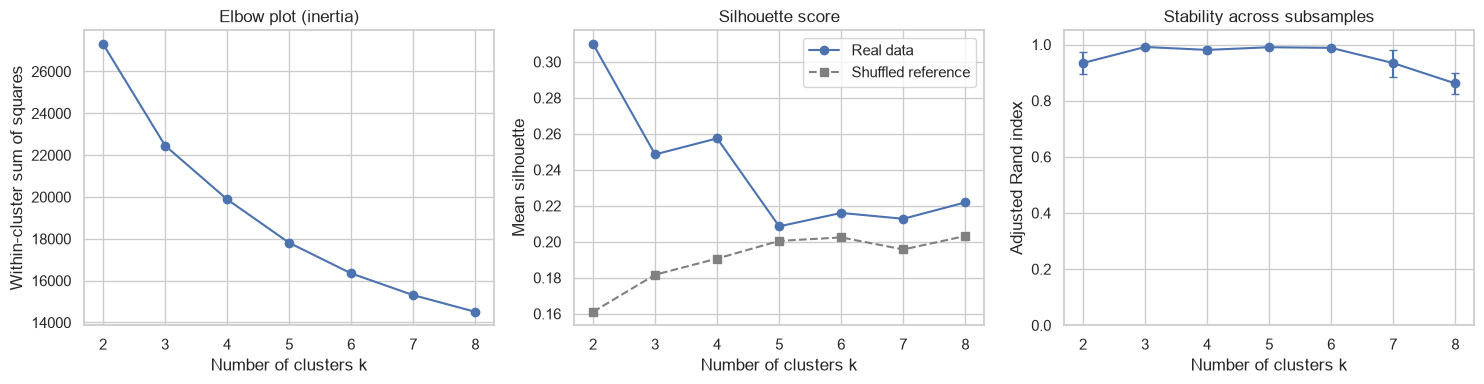

Selected k = 2 (highest silhouette among k with smallest cluster >= 5%).
Silhouette = 0.310 -> weak structure by the rule of thumb; shuffled-data reference = 0.161; stability ARI = 0.93.
Use these groups to explore patterns, not as proven categories.
         patients  % of patients  mean silhouette  % negative silhouette
cluster                                                                 
1            3884           74.8            0.413                    0.0
2            1306           25.2            0.004                   53.1

A low mean silhouette or a high % of negative silhouettes means that cluster overlaps its neighbours (its boundary is blurry).
                               1        2  All patients
patients                 3884.00  1306.00       5190.00
age_mean                   37.37    50.37         40.64
age_median                 27.00    57.00         32.00
income_mean                 0.63     0.46          0.58
illness_mean                0.94     2.88        

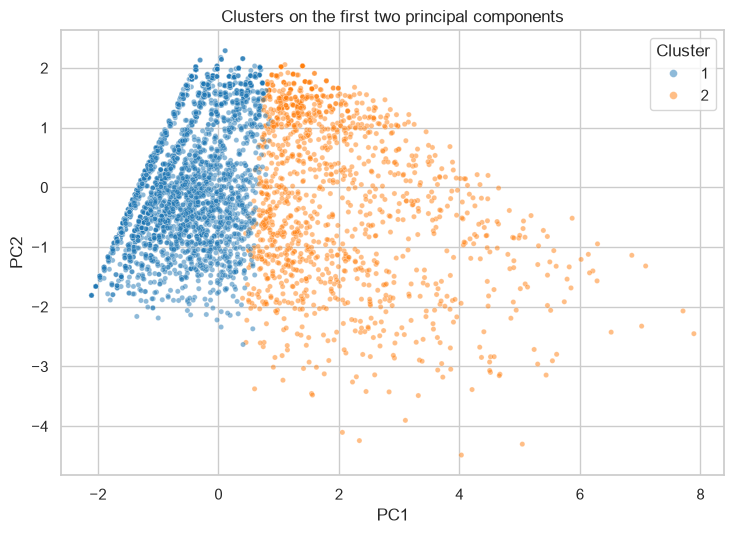

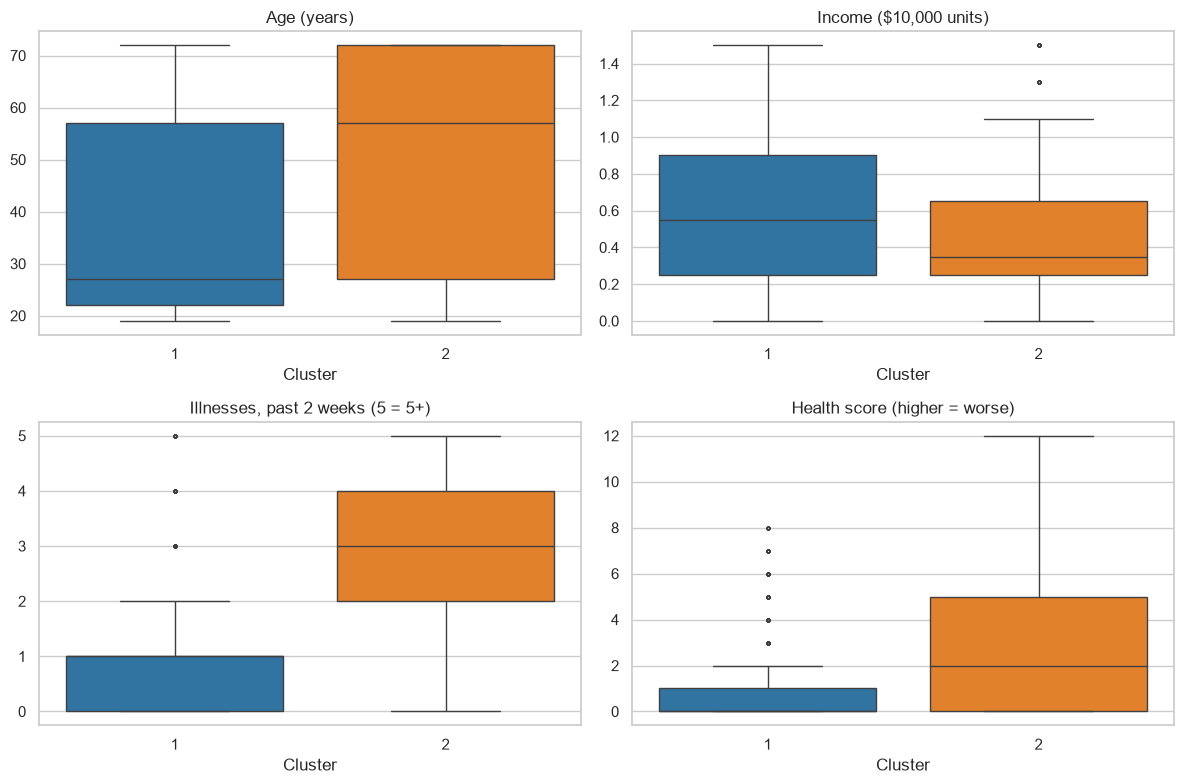

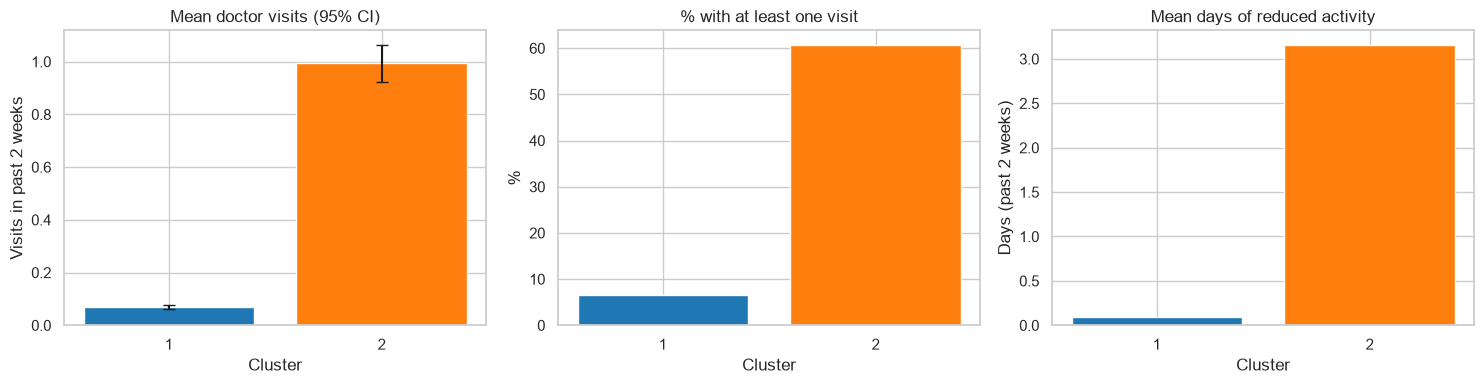

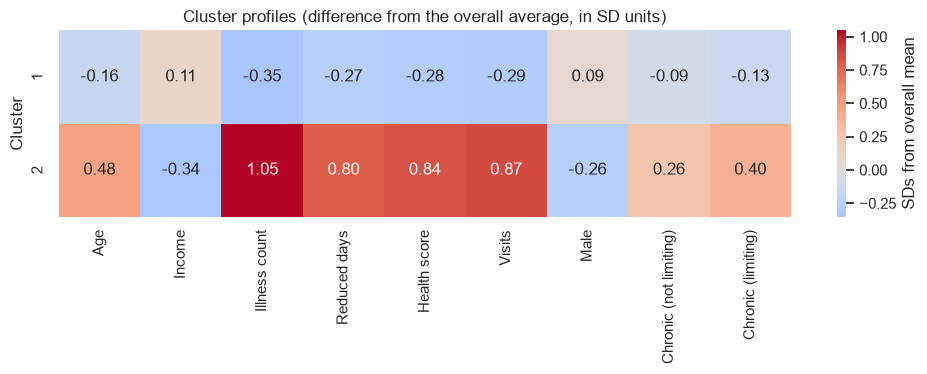

Cluster 1: 3884 patients (74.8%); mean silhouette 0.41
  Visits: mean 0.07, median 0, 7% with at least one visit (overall mean 0.30).
  Age 37 yrs, income 0.63, illnesses 0.94, reduced days 0.09, health score 0.62, 52% male, 7% limiting chronic condition.
  Stands out for: Illness count lower (-0.35 SD).

Cluster 2: 1306 patients (25.2%); mean silhouette 0.00
  Visits: mean 0.99, median 1, 61% with at least one visit (overall mean 0.30).
  Age 50 yrs, income 0.46, illnesses 2.88, reduced days 3.16, health score 2.99, 35% male, 24% limiting chronic condition.
  Stands out for: Illness count higher (+1.05 SD), Visits higher (+0.87 SD), Health score higher (+0.84 SD), Reduced days higher (+0.80 SD), Age higher (+0.48 SD), Chronic (limiting) higher (+0.40 SD), Income lower (-0.34 SD).

ARI between the main clustering and the clustering without visits: 0.26 (1 = identical)

Visits across clusters formed WITHOUT using visits:
                   patients  visits_mean  pct_any_visit  illness_m

In [26]:
# %% [markdown]
# # Exploratory Patient Segmentation (K-means)
#
# **Goal:** explore whether patients fall into groups that are similar in demographics, illness burden,
# health status and doctor-visit frequency.
#
# **How to read this section**
# - Clustering is **exploratory and unsupervised**. It always returns groups, whether or not real groups exist.
#   Part of the job here is to check how much structure there actually is.
# - The clusters are **statistical groupings only**. They are not diagnoses, clinical categories or validated
#   patient types, and the cluster numbers carry no meaning.
# - We do **not assume** a "correct" number of clusters. Several are compared with the elbow method, silhouette
#   scores and a stability check, and the choice is left to you.
#
# ## What the columns mean (checked against published documentation)
# The columns match the Australian Health Survey 1977–78 data (R packages `Ecdat::DoctorAUS`, `faraway::dvisits`,
# `AER::DoctorVisits`; 5,190 single adults, young and old oversampled).
#
# | Column | Meaning | Role here |
# |---|---|---|
# | `Unnamed: 0` | Row number | **Excluded** (identifier) |
# | `visits` | Doctor consultations in the past 2 weeks | Clustering feature |
# | `age` | Age in years **÷ 100** (mid-points of age bands) | Clustering feature (converted to years for display) |
# | `gender` | Female / male | Clustering feature (encoded 0/1) |
# | `income` | Annual income in **$10,000** units (mid-points of bands) | Clustering feature |
# | `illness` | Illnesses in past 2 weeks (**5 means 5 or more**) | Clustering feature |
# | `reduced` | Days of reduced activity in past 2 weeks due to illness or injury (0–14) | Clustering feature |
# | `health` | General Health Questionnaire score, 0–12, **higher = worse** | Clustering feature |
# | `nchronic` / `lchronic` | Chronic condition **not limiting** / **limiting** activity | Clustering features (encoded 0/1) |
# | `private`, `freepoor`, `freerepat` | Insurance/coverage type | **Not used to cluster**; used afterwards to *describe* clusters |
#
# *Caveat:* the documentation uses the original variable names (`sex`, `actdays`, `hscore`, …), so the mapping to
# this CSV rests on matching meaning and value ranges. Confirm it against your own data dictionary.

# %%
import warnings
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

assert "df" in globals(), "Please load your data into a DataFrame named `df` first."

SEED = 42                      # reproducibility: every random step uses this seed
K_RANGE = range(2, 9)          # candidate numbers of clusters to compare
N_INIT = 10                    # K-means restarts (reduces the risk of a poor local solution)
MISSING_STRATEGY = "drop"      # "drop" removes rows with missing feature values; "impute" fills them
LOG_TRANSFORM = ["visits", "reduced"]   # heavily right-skewed counts; log(1 + x) limits the pull of extreme values
K_FINAL = None                 # set an integer (e.g. 4) to choose your own k; None = use the rule in section 6
MIN_CLUSTER_SHARE = 0.05       # rule of thumb: ignore k if its smallest cluster is below 5% of patients

NUMERIC_FEATURES = ["age", "income", "illness", "reduced", "health", "visits"]
BINARY_CATEGORICAL = {"gender": "male", "nchronic": "yes", "lchronic": "yes"}   # column -> level coded as 1
PROFILE_ONLY = ["private", "freepoor", "freerepat"]   # described after clustering, not used to cluster

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
np.random.seed(SEED)

# %% [markdown]
# ## 1. Inspect the columns
# Check types, missing values and unique values before choosing features.

# %%
print(f"Shape: {df.shape}\n")
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_missing": df.isna().sum(),
    "n_unique": df.nunique(),
    "example_values": [", ".join(map(str, df[c].dropna().unique()[:6])) for c in df.columns],
})
print(overview.to_string())

expected = NUMERIC_FEATURES + list(BINARY_CATEGORICAL) + PROFILE_ONLY
absent = [c for c in expected if c not in df.columns]
if absent:
    print(f"\nWARNING: expected columns not found and skipped: {absent}")
    NUMERIC_FEATURES = [c for c in NUMERIC_FEATURES if c in df.columns]
    BINARY_CATEGORICAL = {c: v for c, v in BINARY_CATEGORICAL.items() if c in df.columns}
    PROFILE_ONLY = [c for c in PROFILE_ONLY if c in df.columns]

# %% [markdown]
# ## 2. Choose features and handle redundancy
# - **Row identifiers** (such as an unnamed index column) carry no information about patients and are excluded.
# - **Redundant variables** distort distance-based methods because they count the same information twice. We check pairwise correlations.
# - `nchronic` and `lchronic` are checked for overlap. If a person is never "yes" on both, together they are one
#   three-level variable (no chronic condition / not limiting / limiting), and two 0/1 columns represent it correctly.
# - Insurance columns describe *coverage*, not the demographic/illness/health/visits themes requested, so they are
#   kept aside to describe the clusters afterwards (an independent check).

# %%
def looks_like_identifier(s, name):
    n = str(name).strip().lower()
    if n in {"", "id", "index", "rownames", "row_id"} or n.startswith("unnamed"):
        return True
    return bool(pd.api.types.is_integer_dtype(s) and s.is_unique and (s.is_monotonic_increasing or s.is_monotonic_decreasing))


id_cols = [c for c in df.columns if looks_like_identifier(df[c], c)]
print("Identifier columns excluded:", id_cols)
assert not set(id_cols) & set(NUMERIC_FEATURES + list(BINARY_CATEGORICAL)), "An identifier was selected as a feature."

# Prepare a working copy with numeric versions of every feature
work = df[NUMERIC_FEATURES + list(BINARY_CATEGORICAL) + PROFILE_ONLY].copy()
for c in NUMERIC_FEATURES:
    work[c] = pd.to_numeric(work[c], errors="coerce")

for c, level in BINARY_CATEGORICAL.items():
    s = work[c].astype("object")
    s = s.where(s.isna(), s.astype(str).str.strip().str.lower())
    levels = sorted(s.dropna().unique())
    print(f"{c}: levels = {levels}; coded 1 where value == '{level}'")
    if level not in levels or len(levels) != 2:
        raise ValueError(f"Expected two levels including '{level}' for '{c}', found {levels}.")
    work[f"{c}_{level}"] = np.where(s.isna(), np.nan, (s == level).astype(float))
    work = work.drop(columns=c)
BINARY_FEATURES = [f"{c}_{lv}" for c, lv in BINARY_CATEGORICAL.items()]

if {"nchronic_yes", "lchronic_yes"} <= set(work.columns):
    both = int(((work["nchronic_yes"] == 1) & (work["lchronic_yes"] == 1)).sum())
    print(f"\nRows with BOTH chronic flags = yes: {both} "
          "(0 means the two flags are separate categories, so keeping both is not redundant).")

corr = work[NUMERIC_FEATURES].corr(method="spearman")
print("\nSpearman correlations among numeric features:")
print(corr.round(2).to_string())
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(corr.columns) for b in corr.columns[i + 1:] if abs(corr.loc[a, b]) > 0.7]
print("Pairs with |correlation| > 0.7 (candidate redundancy):", pairs if pairs else "none, so all numeric features are kept")

# %% [markdown]
# ## 3. Missing and unusual values
# Rows missing any clustering feature are removed (or imputed if you set `MISSING_STRATEGY = "impute"`).
# Documented value ranges are checked, and unusual values are reported rather than silently changed.

# %%
feature_cols = NUMERIC_FEATURES + BINARY_FEATURES
print("Missing values in clustering features:\n", work[feature_cols].isna().sum().to_string(), "\n")

n0 = len(work)
if MISSING_STRATEGY == "drop":
    work = work.dropna(subset=feature_cols).copy()
    print(f"Dropped {n0 - len(work)} of {n0} rows with missing feature values; {len(work)} remain.")
else:
    from sklearn.impute import SimpleImputer
    work[NUMERIC_FEATURES] = SimpleImputer(strategy="median").fit_transform(work[NUMERIC_FEATURES])
    work[BINARY_FEATURES] = SimpleImputer(strategy="most_frequent").fit_transform(work[BINARY_FEATURES])
    print(f"Imputed missing feature values (median for numeric, most frequent for binary); {len(work)} rows kept.")

documented = {"age": (0.19, 0.72), "income": (0, 1.5), "illness": (0, 5), "reduced": (0, 14), "health": (0, 12)}
for c, (lo, hi) in documented.items():
    if c in work:
        out = int(((work[c] < 0) | (work[c] > 1.5 * hi + 1)).sum()) if c != "age" else int((work[c] > 1.5).sum())
        print(f"{c:<8} observed {work[c].min():g} to {work[c].max():g} (typical documented range {lo} to {hi}); implausible values: {out}")
print("visits: observed", work["visits"].min(), "to", work["visits"].max(), "| % zeros:", round((work['visits'] == 0).mean() * 100, 1))
print("reduced: % zeros:", round((work['reduced'] == 0).mean() * 100, 1), "| % at the 14-day maximum:",
      round((work['reduced'] >= 14).mean() * 100, 1))
print("\nNote: visits and reduced are zero-heavy with a long right tail; K-means uses squared distances, so a few extreme values "
      f"can dominate. We apply log(1 + x) to {LOG_TRANSFORM} before scaling.")

work["age_years"] = work["age"] * 100   # documented as years / 100; used for display and profiling

# %% [markdown]
# ## 4. Build the feature matrix: transform, scale, encode
# - Skewed counts get `log(1 + x)`.
# - **Numeric features are standardised** (mean 0, SD 1) so that a variable with large numbers, such as `reduced`,
#   does not outweigh one with small numbers, such as `income`. K-means uses straight-line distance, so scale matters.
# - **Binary (0/1) categorical features** are left as 0/1; they are already on a comparable scale.
# - Because five of the nine features relate to illness or chronic status (`illness`, `reduced`, `health`, `nchronic`, `lchronic`),
#   any grouping will tend to be driven by illness burden. That is a consequence of the chosen features.

# %%
model_df = work[feature_cols].copy()
for c in LOG_TRANSFORM:
    if c in model_df:
        model_df[c] = np.log1p(model_df[c])

preprocess = ColumnTransformer(
    [("scale_numeric", StandardScaler(), NUMERIC_FEATURES),
     ("keep_binary", "passthrough", BINARY_FEATURES)],
    verbose_feature_names_out=False,
)
X = pd.DataFrame(preprocess.fit_transform(model_df), columns=NUMERIC_FEATURES + BINARY_FEATURES, index=model_df.index)
print("Feature matrix shape:", X.shape)
print(X.describe().loc[["mean", "std", "min", "max"]].round(2).to_string())

# %% [markdown]
# ## 5. Compare cluster counts
# For each candidate *k* we record:
# - **Inertia** (within-cluster sum of squares): always falls as *k* rises; the **elbow method** looks for where the improvement flattens.
# - **Silhouette score** (−1 to 1): how well each point sits in its own cluster compared with the nearest other cluster.
#   Rough guide (Kaufman & Rousseeuw): above 0.5 reasonable structure, 0.26–0.5 weak, 0.25 or below no substantial structure.
# - **Smallest cluster share**: tiny clusters are often just outliers.
# - **Stability:** adjusted Rand index (ARI, 1 = identical grouping) between the full-data clustering and clusterings from random 80% subsamples. Low values mean the groups are not reproducible.
# - **Reference silhouette on shuffled data:** each column is shuffled independently, which destroys relationships between variables while
#   keeping each column's distribution. If the real silhouette is not clearly above this reference, the data show little structure beyond the individual variables.

# %%
rng = np.random.default_rng(SEED)
X_np = X.to_numpy()
X_shuffled = np.column_stack([rng.permutation(X_np[:, j]) for j in range(X_np.shape[1])])


def stability_ari(X_arr, k, n_rep=10, frac=0.8):
    base = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(X_arr)
    base_labels = base.labels_
    scores = []
    for r in range(n_rep):
        idx = rng.choice(len(X_arr), int(frac * len(X_arr)), replace=False)
        sub = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED + r + 1).fit(X_arr[idx])
        scores.append(adjusted_rand_score(base_labels, sub.predict(X_arr)))
    return float(np.mean(scores)), float(np.std(scores))


rows = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(X_np)
        sil = silhouette_score(X_np, km.labels_)
        km_sh = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(X_shuffled)
        sil_sh = silhouette_score(X_shuffled, km_sh.labels_)
        ari_m, ari_s = stability_ari(X_np, k)
        rows.append({"k": k, "inertia": km.inertia_, "silhouette": sil, "silhouette (shuffled ref.)": sil_sh,
                     "smallest cluster share": np.bincount(km.labels_).min() / len(X_np),
                     "stability ARI (mean)": ari_m, "stability ARI (sd)": ari_s})
eval_df = pd.DataFrame(rows).set_index("k")
print(eval_df.round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(eval_df.index, eval_df["inertia"], "o-")
axes[0].set(title="Elbow plot (inertia)", xlabel="Number of clusters k", ylabel="Within-cluster sum of squares")
axes[1].plot(eval_df.index, eval_df["silhouette"], "o-", label="Real data")
axes[1].plot(eval_df.index, eval_df["silhouette (shuffled ref.)"], "s--", color="gray", label="Shuffled reference")
axes[1].set(title="Silhouette score", xlabel="Number of clusters k", ylabel="Mean silhouette")
axes[1].legend()
axes[2].errorbar(eval_df.index, eval_df["stability ARI (mean)"], yerr=eval_df["stability ARI (sd)"], fmt="o-", capsize=3)
axes[2].set(title="Stability across subsamples", xlabel="Number of clusters k", ylabel="Adjusted Rand index", ylim=(0, 1.05))
plt.tight_layout()
plt.show()

# %% [markdown]
# ## 6. Choose k (transparently)
# There is no objectively "correct" *k*. The rule below is only a default: among candidate values whose smallest
# cluster holds at least `MIN_CLUSTER_SHARE` of patients, take the highest silhouette. **Override it with `K_FINAL`** if the elbow plot,
# the stability results or your subject knowledge point elsewhere. Always read the score against the shuffled reference and the guide above.

# %%
eligible = eval_df[eval_df["smallest cluster share"] >= MIN_CLUSTER_SHARE]
if K_FINAL is not None:
    k_final, how = int(K_FINAL), "set manually by K_FINAL"
elif len(eligible):
    k_final, how = int(eligible["silhouette"].idxmax()), (f"highest silhouette among k with smallest cluster >= {MIN_CLUSTER_SHARE:.0%}")
else:
    k_final, how = int(eval_df["silhouette"].idxmax()), "highest silhouette (no k met the minimum-size rule)"

best = eval_df.loc[k_final]
sil_label = ("reasonable structure" if best["silhouette"] > 0.5 else "weak structure" if best["silhouette"] > 0.25
             else "no substantial structure")
print(f"Selected k = {k_final} ({how}).")
print(f"Silhouette = {best['silhouette']:.3f} -> {sil_label} by the rule of thumb; "
      f"shuffled-data reference = {best['silhouette (shuffled ref.)']:.3f}; stability ARI = {best['stability ARI (mean)']:.2f}.")
print("Use these groups to explore patterns, not as proven categories.")

# %% [markdown]
# ## 7. Fit the final model and relabel clusters by size
# Clusters are renumbered 1, 2, 3, … from largest to smallest so the numbers are reproducible and imply no ranking of health or severity.

# %%
final_km = KMeans(n_clusters=k_final, n_init=N_INIT, random_state=SEED).fit(X_np)
raw_labels = pd.Series(final_km.labels_, index=X.index)
order = raw_labels.value_counts().index.tolist()                    # largest first
relabel = {old: new for new, old in enumerate(order, start=1)}
work["cluster"] = raw_labels.map(relabel).astype(int)
X["cluster"] = work["cluster"]
cluster_order = sorted(work["cluster"].unique())

sil_samples = silhouette_samples(X_np, work["cluster"].to_numpy())
sil_by_cluster = pd.DataFrame({
    "patients": work["cluster"].value_counts().sort_index(),
    "% of patients": (work["cluster"].value_counts(normalize=True).sort_index() * 100).round(1),
    "mean silhouette": pd.Series(sil_samples, index=work.index).groupby(work["cluster"]).mean().round(3),
    "% negative silhouette": pd.Series(sil_samples < 0, index=work.index).groupby(work["cluster"]).mean().mul(100).round(1),
})
print(sil_by_cluster.to_string())
print("\nA low mean silhouette or a high % of negative silhouettes means that cluster overlaps its neighbours (its boundary is blurry).")

# %% [markdown]
# ## 8. Describe the clusters with actual summary statistics
# All values are computed from your data in original units (not the scaled values). Visits was one of the clustering
# features, so differences in visits between clusters are partly built in; the sensitivity check in section 11 re-clusters without it.

# %%
work["any_visit"] = (work["visits"] > 0).astype(float)
work["reduced_any"] = (work["reduced"] > 0).astype(float)

summary = work.groupby("cluster").agg(
    patients=("visits", "size"),
    age_mean=("age_years", "mean"), age_median=("age_years", "median"),
    income_mean=("income", "mean"),
    illness_mean=("illness", "mean"), illness_median=("illness", "median"),
    reduced_mean=("reduced", "mean"), pct_any_reduced=("reduced_any", lambda s: s.mean() * 100),
    health_mean=("health", "mean"), health_median=("health", "median"),
    visits_mean=("visits", "mean"), visits_median=("visits", "median"), pct_any_visit=("any_visit", lambda s: s.mean() * 100),
    pct_male=("gender_male", lambda s: s.mean() * 100),
    pct_nonlimiting_chronic=("nchronic_yes", lambda s: s.mean() * 100),
    pct_limiting_chronic=("lchronic_yes", lambda s: s.mean() * 100),
)
overall = pd.Series({
    "patients": len(work), "age_mean": work["age_years"].mean(), "age_median": work["age_years"].median(),
    "income_mean": work["income"].mean(), "illness_mean": work["illness"].mean(), "illness_median": work["illness"].median(),
    "reduced_mean": work["reduced"].mean(), "pct_any_reduced": work["reduced_any"].mean() * 100,
    "health_mean": work["health"].mean(), "health_median": work["health"].median(),
    "visits_mean": work["visits"].mean(), "visits_median": work["visits"].median(), "pct_any_visit": work["any_visit"].mean() * 100,
    "pct_male": work["gender_male"].mean() * 100, "pct_nonlimiting_chronic": work["nchronic_yes"].mean() * 100,
    "pct_limiting_chronic": work["lchronic_yes"].mean() * 100,
}, name="All patients")
summary_table = pd.concat([summary, overall.to_frame().T]).round(2)
print(summary_table.T.to_string())

# Insurance / coverage profile (NOT used to form the clusters)
if PROFILE_ONLY:
    ins = pd.DataFrame({c: work.groupby("cluster")[c].apply(lambda s: (s.astype(str).str.lower() == "yes").mean() * 100)
                        for c in PROFILE_ONLY}).round(1)
    ins.loc["All patients"] = [(work[c].astype(str).str.lower() == "yes").mean() * 100 for c in PROFILE_ONLY]
    print("\n% with each coverage type (not used for clustering):")
    print(ins.to_string())

# %% [markdown]
# ## 9. Visual comparison of clusters

# %%
# (a) PCA map: squeezes the 9 features into 2 axes ONLY for display (clusters were found in the full 9-D space)
pca = PCA(n_components=2, random_state=SEED)
coords = pca.fit_transform(X_np)
print(f"PCA explains {pca.explained_variance_ratio_.sum():.1%} of the variance in 2 dimensions "
      f"({pca.explained_variance_ratio_[0]:.1%} + {pca.explained_variance_ratio_[1]:.1%}); overlap in this picture does not prove overlap in the full data.")
load = pd.DataFrame(pca.components_.T, index=X.columns[:-1], columns=["PC1", "PC2"]).round(2)
print("\nWhat the two axes mainly reflect (loadings):")
print(load.to_string())

fig, ax = plt.subplots(figsize=(7.5, 5.5))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=work["cluster"], palette="tab10", s=14, alpha=0.5, ax=ax)
ax.set(title="Clusters on the first two principal components", xlabel="PC1", ylabel="PC2")
ax.legend(title="Cluster", markerscale=1.5)
plt.tight_layout()
plt.show()

# %%
# (b) Distribution of age, income, illness count and health score by cluster
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (col, title) in zip(axes.ravel(), [("age_years", "Age (years)"), ("income", "Income ($10,000 units)"),
                                          ("illness", "Illnesses, past 2 weeks (5 = 5+)"), ("health", "Health score (higher = worse)")]):
    sns.boxplot(data=work, x="cluster", y=col, hue="cluster", palette="tab10", legend=False, fliersize=2, ax=ax)
    ax.set(title=title, xlabel="Cluster", ylabel="")
plt.tight_layout()
plt.show()

# %%
# (c) Doctor visits and reduced activity: counts are mostly 0, so bars of means and % with any are clearer than boxplots
def mean_ci(s):
    n = len(s)
    return s.mean(), 1.96 * s.std(ddof=1) / np.sqrt(n) if n > 1 else np.nan


fig, axes = plt.subplots(1, 3, figsize=(15, 4))
stats_v = work.groupby("cluster")["visits"].apply(mean_ci)
axes[0].bar([str(c) for c in cluster_order], [stats_v[c][0] for c in cluster_order],
            yerr=[stats_v[c][1] for c in cluster_order], capsize=4, color=sns.color_palette("tab10", len(cluster_order)))
axes[0].set(title="Mean doctor visits (95% CI)", xlabel="Cluster", ylabel="Visits in past 2 weeks")
axes[1].bar([str(c) for c in cluster_order], summary["pct_any_visit"], color=sns.color_palette("tab10", len(cluster_order)))
axes[1].set(title="% with at least one visit", xlabel="Cluster", ylabel="%")
axes[2].bar([str(c) for c in cluster_order], summary["reduced_mean"], color=sns.color_palette("tab10", len(cluster_order)))
axes[2].set(title="Mean days of reduced activity", xlabel="Cluster", ylabel="Days (past 2 weeks)")
plt.tight_layout()
plt.show()

# %%
# (d) Heatmap: how far each cluster's average is from the overall average, in standard-deviation units
profile_cols = {"age_years": "Age", "income": "Income", "illness": "Illness count", "reduced": "Reduced days",
                "health": "Health score", "visits": "Visits", "gender_male": "Male", "nchronic_yes": "Chronic (not limiting)",
                "lchronic_yes": "Chronic (limiting)"}
z = (work.groupby("cluster")[list(profile_cols)].mean() - work[list(profile_cols)].mean()) / work[list(profile_cols)].std()
z.columns = list(profile_cols.values())
fig, ax = plt.subplots(figsize=(10, 0.7 * len(z) + 2.5))
sns.heatmap(z, annot=True, fmt=".2f", cmap="coolwarm", center=0, cbar_kws={"label": "SDs from overall mean"}, ax=ax)
ax.set(title="Cluster profiles (difference from the overall average, in SD units)", ylabel="Cluster")
plt.tight_layout()
plt.show()

# %% [markdown]
# ## 10. Plain-language description of each cluster (generated from the numbers)
# Only features that differ notably from the overall average (about 0.3 SD or more) are listed.
# The names are just numbers. They describe statistical similarity, not medical categories.

# %%
THRESH = 0.3
for c in cluster_order:
    row, n = summary.loc[c], int(summary.loc[c, "patients"])
    feats = z.loc[c].sort_values(key=np.abs, ascending=False)
    notable = feats[np.abs(feats) >= THRESH]
    print(f"Cluster {c}: {n} patients ({n / len(work):.1%}); mean silhouette {sil_by_cluster.loc[c, 'mean silhouette']:.2f}")
    print(f"  Visits: mean {row['visits_mean']:.2f}, median {row['visits_median']:.0f}, {row['pct_any_visit']:.0f}% with at least one visit "
          f"(overall mean {overall['visits_mean']:.2f}).")
    print(f"  Age {row['age_mean']:.0f} yrs, income {row['income_mean']:.2f}, illnesses {row['illness_mean']:.2f}, "
          f"reduced days {row['reduced_mean']:.2f}, health score {row['health_mean']:.2f}, "
          f"{row['pct_male']:.0f}% male, {row['pct_limiting_chronic']:.0f}% limiting chronic condition.")
    if len(notable):
        txt = ", ".join(f"{name} {'higher' if v > 0 else 'lower'} ({v:+.2f} SD)" for name, v in notable.items())
        print(f"  Stands out for: {txt}.")
    else:
        print("  No feature differs from the overall average by 0.3 SD or more.")
    if n / len(work) < 0.02:
        print("  Note: very small cluster; it may mainly collect unusual or extreme records.")
    print()

# %% [markdown]
# ## 11. Sensitivity checks
# 1. **Re-cluster without `visits`.** If groups formed from demographics, illness and health alone still differ in visits, that pattern is
#    not simply built in. Compare with the main solution using ARI.
# 2. **Different random seeds.** The same *k* with another seed should give a similar grouping (ARI near 1).

# %%
no_visits_cols = [c for c in X.columns if c not in ("cluster", "visits")]
Xnv = X[no_visits_cols].to_numpy()
km_nv = KMeans(n_clusters=k_final, n_init=N_INIT, random_state=SEED).fit(Xnv)
work["cluster_no_visits"] = pd.Series(km_nv.labels_, index=X.index).map(
    {old: new for new, old in enumerate(pd.Series(km_nv.labels_).value_counts().index, start=1)}).astype(int)

print(f"ARI between the main clustering and the clustering without visits: "
      f"{adjusted_rand_score(work['cluster'], work['cluster_no_visits']):.2f} (1 = identical)")
nv = work.groupby("cluster_no_visits").agg(patients=("visits", "size"), visits_mean=("visits", "mean"),
                                           pct_any_visit=("any_visit", lambda s: s.mean() * 100),
                                           illness_mean=("illness", "mean"), health_mean=("health", "mean"),
                                           age_mean=("age_years", "mean")).round(2)
print("\nVisits across clusters formed WITHOUT using visits:")
print(nv.to_string())

other = KMeans(n_clusters=k_final, n_init=N_INIT, random_state=SEED + 99).fit(X_np)
print(f"\nARI between two random seeds at k = {k_final}: {adjusted_rand_score(final_km.labels_, other.labels_):.2f}")

# %% [markdown]
# ## 12. Limitations: how to use these clusters
#
# - **Clustering always produces groups.** K-means will split any data into *k* parts. The silhouette scores, the shuffled reference
#   and the stability check show how much real structure there is; low values mean the "groups" are slices of a continuous spread.
# - **Not diagnoses.** The clusters are not medical categories and are not clinically validated. Do not use them to diagnose, triage,
#   or make decisions about individual patients.
# - **K-means assumptions.** It prefers roughly round, similar-sized groups and uses straight-line distance. The binary and discrete
#   features, the zero-heavy counts and the top-coded `illness` (5 = 5 or more) do not suit this well, so boundaries are approximate.
# - **Choices shape results.** Which features are included, the log transform, scaling, and *k* all change the groups. Five of nine features
#   concern illness/chronic status, so illness burden dominates. Try other settings at the top of the section and see what changes.
# - **Circularity.** Visits was a clustering input, so visit differences between clusters are partly built in. The check without visits (section 11) is more informative.
# - **Outliers.** A small cluster may simply collect unusual records (for example many reduced-activity days).
# - **Cross-sectional, self-reported data.** The 2-week window is short, and the sample is from 1977–78 (single adults; young and old oversampled).
#   Findings may not generalise, and no causal conclusions follow from cluster differences.
# - **Next steps.** Examine other algorithms (for example Gaussian mixtures or hierarchical clustering), check stability on new data, and have a
#   clinical or domain expert review whether any grouping is meaningful before using it for any purpose.

## 22. Outliers and data quality

Shape: (5190, 13)

              dtype  n_missing  % missing  n_unique
Unnamed: 0    int64          0        0.0      5190
visits        int64          0        0.0        10
gender          str          0        0.0         2
age         float64          0        0.0        12
income      float64          0        0.0        14
illness       int64          0        0.0         6
reduced       int64          0        0.0        15
health        int64          0        0.0        13
private         str          0        0.0         2
freepoor        str          0        0.0         2
freerepat       str          0        0.0         2
nchronic        str          0        0.0         2
lchronic        str          0        0.0         2

Exact duplicate rows: 0 (for survey data with few possible answers, duplicates can be legitimate and are not removed).

Categorical columns and their levels:
  gender: {'female': 2702, 'male': 2488}
  private: {'no': 2892, 'yes': 2298}
  freepoor: {'no

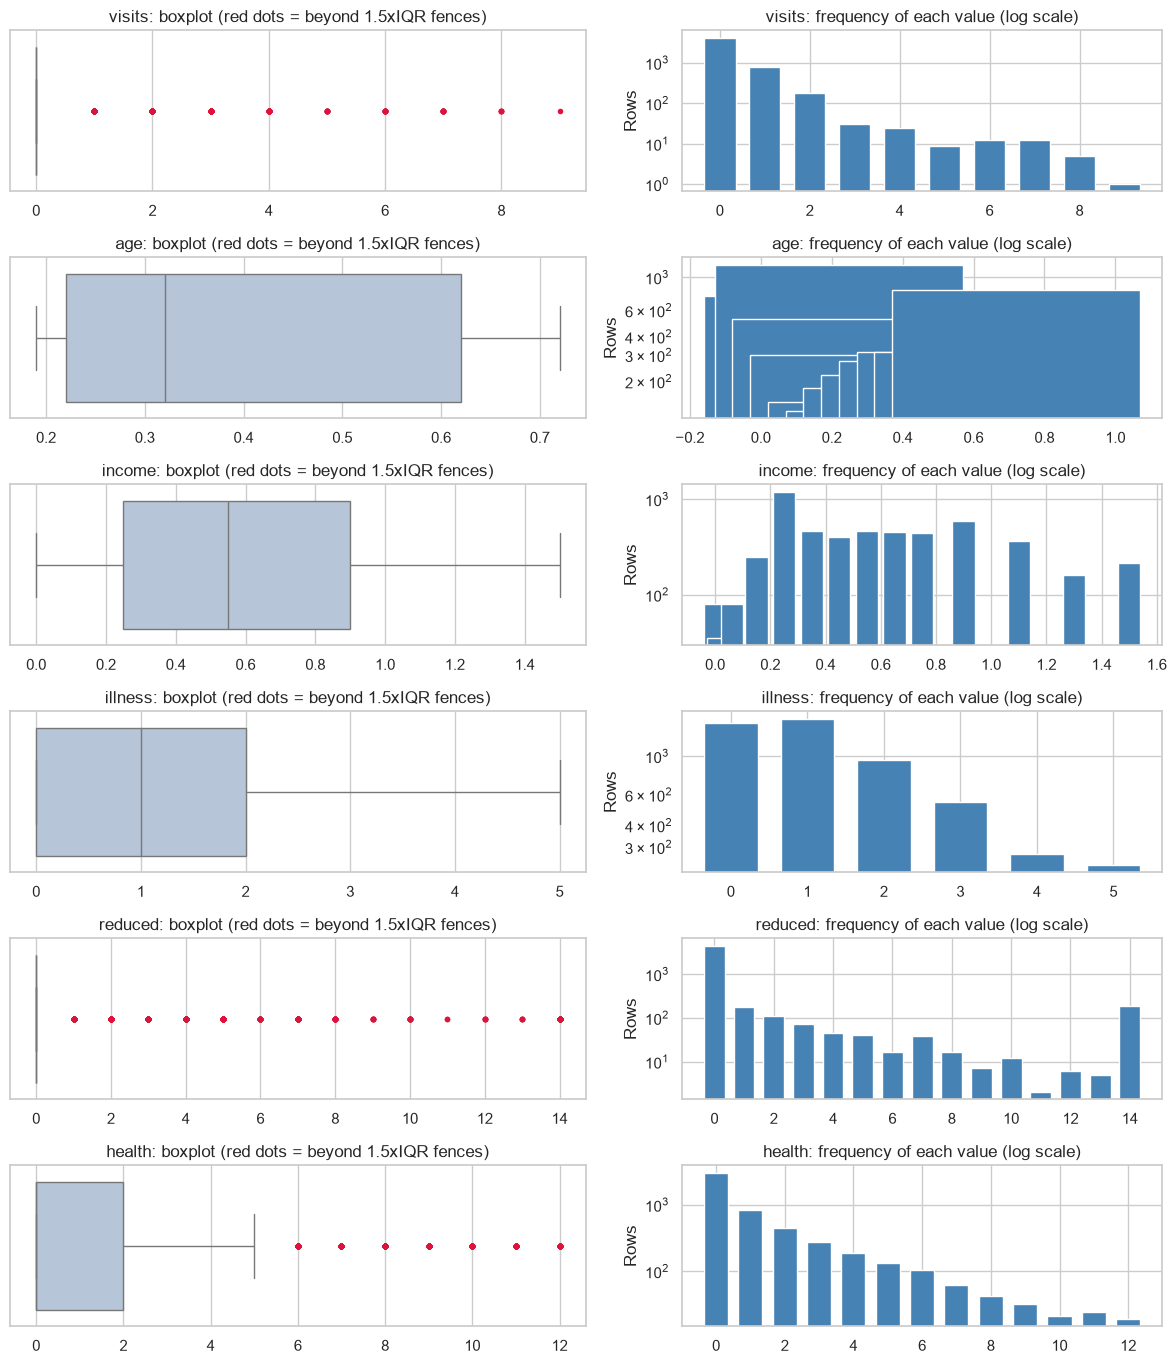

          flagged  flagged AND outside documented range  flagged AND within documented range  rows at documented maximum                             flagged values (value: count)
variable                                                                                                                                                                          
visits       1049                                     0                                 1049                         NaN    1: 782, 2: 174, 3: 30, 4: 24, 5: 9, 6: 12, 7: 12, 8: 5
age             0                                     0                                    0                       822.0                                                          
income          0                                     0                                    0                       215.0                                                          
illness         0                                     0                                    0             

In [27]:
# %% [markdown]
# # Outlier Detection and Data Quality Assessment
#
# **Purpose:** find values that are statistically unusual, check whether they are *valid* or *impossible*, and see how much
# they matter, **without removing or changing anything automatically**.
#
# **Three different things are kept apart throughout**
# | Category | Meaning | What to do |
# |---|---|---|
# | **Impossible / invalid** | Breaks a rule of the data (negative count, value above a documented limit, wrong type) | Investigate and correct against the source; may be set to missing or removed *with a documented reason* |
# | **Statistically unusual but valid** | Far from most values but allowed (for example a patient with 9 doctor visits) | Usually **keep**; these can be exactly the patients of interest |
# | **Implausible, needs review** | Allowed by the rules but surprising | Review manually; keep unless there is evidence of error |
#
# **Value limits used for validity checks** (from published documentation of the Australian Health Survey 1977–78 data;
# `Ecdat::DoctorAUS`, `faraway::dvisits`): `illness` is a count in the past 2 weeks with 5 or more coded as 5; `reduced` is days of reduced activity
# in the past 2 weeks, so at most 14; `health` is a 0–12 questionnaire score; `age` is years ÷ 100 (mid-points, 70+ coded as 72);
# `income` is in $10,000 units with the top band coded as $15,000 (so at most 1.5); `visits` is a non-negative count of consultations in the past 2 weeks.
# Check these limits against your own data dictionary. The original `df` is never modified; any treatment is applied to **separate, labelled copies**.

# %%
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

assert "df" in globals(), "Please load your data into a DataFrame named `df` first."

IQR_K = 1.5            # standard multiplier for "potential outliers"
IQR_K_EXTREME = 3.0    # stricter multiplier often used for "extreme" values
WINSOR_PCT = 0.99      # used only in the sensitivity analysis

# Documented limits: (lowest valid, highest valid, must_be_whole_number)
DOCUMENTED_LIMITS = {
    "visits":  (0, None, True),     # no documented maximum; a separate plausibility rule is used below
    "illness": (0, 5, True),        # 5 means "5 or more"
    "reduced": (0, 14, True),       # 2-week window
    "health":  (0, 12, True),       # GHQ score, 0-12
    "income":  (0, 1.5, False),     # $10,000 units; top band coded as $15,000
    "age":     (0.15, 0.72, False), # years / 100; 70+ coded as 72
}
PLAUSIBILITY_MAX_VISITS = 14   # assumption (NOT documented): more than one visit per day in 2 weeks deserves a manual look

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

# Fingerprint of df so we can prove at the end that it was not changed
df_fingerprint = int(pd.util.hash_pandas_object(df, index=True).sum())

# %% [markdown]
# ## 1. Basic data quality checks

# %%
print(f"Shape: {df.shape}\n")
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_missing": df.isna().sum(),
    "% missing": (df.isna().mean() * 100).round(2),
    "n_unique": df.nunique(),
})
print(quality.to_string())
dups = int(df.duplicated().sum())
print(f"\nExact duplicate rows: {dups} (for survey data with few possible answers, duplicates can be legitimate and are not removed).")

# Categorical columns: are the levels what we expect?
cat_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
print("\nCategorical columns and their levels:")
for c in cat_cols:
    print(f"  {c}: {df[c].value_counts(dropna=False).to_dict()}")

# %% [markdown]
# ## 2. Which numeric columns are suitable for outlier analysis?
# Outlier rules make sense for measured or count variables with a spread of values. They do not make sense for
# **row identifiers** (just numbers) or **binary** variables (only two possible values). Variables with very few
# distinct values are analysed *with caution*, because quartile-based rules are coarse for them.

# %%
def looks_like_identifier(s, name):
    n = str(name).strip().lower()
    if n in {"", "id", "index", "rownames", "row_id"} or n.startswith("unnamed"):
        return True
    return bool(pd.api.types.is_integer_dtype(s) and s.is_unique and (s.is_monotonic_increasing or s.is_monotonic_decreasing))


rows = []
for c in df.select_dtypes(include="number").columns:
    s = df[c].dropna()
    nun = s.nunique()
    whole = bool(np.allclose(s, s.round())) if len(s) else False
    if looks_like_identifier(df[c], c):
        use, why = "no", "row identifier"
    elif nun <= 1:
        use, why = "no", "constant"
    elif nun == 2:
        use, why = "no", "binary (only two values)"
    elif whole and nun <= 10:
        use, why = "yes, with caution", "few distinct whole-number values"
    else:
        use, why = "yes", "numeric with a spread of values"
    rows.append({"column": c, "n_unique": nun, "min": s.min(), "max": s.max(), "% zeros": round((s == 0).mean() * 100, 1),
                 "skewness": round(s.skew(), 2), "outlier analysis?": use, "reason": why})
inspect = pd.DataFrame(rows).set_index("column")
print(inspect.to_string())

analysis_vars = [c for c in inspect.index if inspect.loc[c, "outlier analysis?"].startswith("yes")]
requested = ["income", "visits", "illness", "reduced"]
for c in requested:
    if c not in df.columns:
        print(f"\nNote: requested variable '{c}' does not exist in df and is skipped.")
    elif c not in analysis_vars:
        print(f"\nNote: requested variable '{c}' was judged unsuitable ({inspect.loc[c, 'reason']}).")
print("\nVariables analysed:", analysis_vars)

# %% [markdown]
# ## 3. Impossible values (checked separately from unusual values)
# These checks use **rules**, not the data's own spread. A value can be far from the rest and still be perfectly valid; a value can also sit
# in the middle of the data and still be impossible.

# %%
check_rows = []
for c in analysis_vars:
    s = pd.to_numeric(df[c], errors="coerce")
    lo, hi, must_be_whole = DOCUMENTED_LIMITS.get(c, (None, None, False))
    n_missing = int(df[c].isna().sum())
    n_nonnumeric = int(s.isna().sum() - n_missing)
    n_below = int((s < lo).sum()) if lo is not None else np.nan
    n_above = int((s > hi).sum()) if hi is not None else np.nan
    n_fraction = int((s.dropna() % 1 != 0).sum()) if must_be_whole else np.nan
    check_rows.append({"variable": c, "documented range": f"{lo} to {hi if hi is not None else 'no upper limit'}",
                       "missing": n_missing, "non-numeric": n_nonnumeric, "below minimum": n_below,
                       "above maximum": n_above, "non-whole (count vars)": n_fraction})
impossible = pd.DataFrame(check_rows).set_index("variable")
print(impossible.to_string())

total_impossible = int(impossible[["below minimum", "above maximum", "non-whole (count vars)", "non-numeric"]].fillna(0).sum().sum())
print(f"\nTotal rule violations found: {total_impossible}")

# Cross-field consistency rules (logic that must hold between columns)
print("\nCross-field consistency checks:")
if {"nchronic", "lchronic"} <= set(df.columns):
    both = int(((df["nchronic"].astype(str).str.lower() == "yes") & (df["lchronic"].astype(str).str.lower() == "yes")).sum())
    print(f"  chronic condition flagged as both limiting and non-limiting: {both}")
if {"freepoor", "freerepat"} <= set(df.columns):
    both = int(((df["freepoor"].astype(str).str.lower() == "yes") & (df["freerepat"].astype(str).str.lower() == "yes")).sum())
    print(f"  both kinds of free government cover: {both}")
if {"private", "freepoor", "freerepat"} <= set(df.columns):
    n_yes = sum((df[c].astype(str).str.lower() == "yes").astype(int) for c in ("private", "freepoor", "freerepat"))
    print(f"  more than one coverage type flagged: {int((n_yes > 1).sum())}")
if "visits" in df.columns:
    print(f"  visits above the plausibility rule of {PLAUSIBILITY_MAX_VISITS} (assumption, not documented): "
          f"{int((df['visits'] > PLAUSIBILITY_MAX_VISITS).sum())}")
if {"illness", "reduced"} <= set(df.columns):
    n_inj = int(((df["illness"] == 0) & (df["reduced"] > 0)).sum())
    print(f"  reduced activity with zero counted illnesses: {n_inj} (plausible, because 'reduced' also covers injury; shown for transparency)")

# %% [markdown]
# ## 4. IQR method: potential outliers
# **How it works:** Q1 and Q3 are the 25th and 75th percentiles and IQR = Q3 − Q1. Values below `Q1 − 1.5×IQR` or above `Q3 + 1.5×IQR`
# are flagged as *potential* outliers (using 3×IQR flags only the most extreme). "Potential" matters: the rule only says a value is far from the middle 50%, not that it is wrong.
#
# **Known weakness:** for variables where most values are identical (for example mostly 0), Q1 = Q3 = 0 so IQR = 0 and *every* non-zero value is flagged. The
# code warns when this happens.

# %%
def iqr_flags(s: pd.Series, k: float):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - k * iqr, q3 + k * iqr
    return q1, q3, iqr, lo, hi, (s < lo) | (s > hi)


out_rows, flag_masks = [], {}
for c in analysis_vars:
    s = pd.to_numeric(df[c], errors="coerce").dropna()
    q1, q3, iqr, lo, hi, m = iqr_flags(s, IQR_K)
    *_, m_ext = iqr_flags(s, IQR_K_EXTREME)
    flag_masks[c] = m
    out_rows.append({"variable": c, "n": len(s), "Q1": q1, "Q3": q3, "IQR": iqr, "lower fence": lo, "upper fence": hi,
                     "n below": int((s < lo).sum()), "n above": int((s > hi).sum()),
                     "n potential outliers": int(m.sum()), "% potential outliers": round(m.mean() * 100, 2),
                     f"n beyond {IQR_K_EXTREME}xIQR": int(m_ext.sum()),
                     "IQR = 0 warning": "YES" if iqr == 0 else ""})
outliers = pd.DataFrame(out_rows).set_index("variable")
print(outliers.to_string())

zero_iqr = outliers.index[outliers["IQR = 0 warning"] == "YES"].tolist()
if zero_iqr:
    print(f"\nWARNING: IQR = 0 for {zero_iqr}. More than half of the values are identical, so the fences collapse onto that value and every other value "
          "is flagged. For these variables the IQR flag mostly shows that the variable is zero-heavy, NOT that those values are errors.")

# %% [markdown]
# ## 5. Boxplots before any treatment
# Top: boxplot of the raw values (dots beyond the whiskers are the IQR-flagged values). Bottom: the frequency of each value, because for
# discrete or zero-heavy variables the box can collapse to a line and hide what is going on.

# %%
n = len(analysis_vars)
fig, axes = plt.subplots(n, 2, figsize=(12, 2.3 * n), gridspec_kw={"width_ratios": [1.2, 1]})
axes = np.atleast_2d(axes)
for i, c in enumerate(analysis_vars):
    s = pd.to_numeric(df[c], errors="coerce").dropna()
    sns.boxplot(x=s, ax=axes[i, 0], color="lightsteelblue", fliersize=3, flierprops={"markerfacecolor": "crimson", "markeredgecolor": "crimson"})
    axes[i, 0].set(title=f"{c}: boxplot (red dots = beyond {IQR_K}xIQR fences)", xlabel="")
    if s.nunique() <= 15:
        vc = s.value_counts().sort_index()
        axes[i, 1].bar(vc.index.astype(float), vc.values, color="steelblue", width=0.7 if c != "income" else 0.08)
        axes[i, 1].set_yscale("log")
        axes[i, 1].set(title=f"{c}: frequency of each value (log scale)", xlabel="", ylabel="Rows")
    else:
        axes[i, 1].hist(s, bins=30, color="steelblue", edgecolor="white")
        axes[i, 1].set(title=f"{c}: histogram", xlabel="", ylabel="Rows")
plt.tight_layout()
plt.show()

# %% [markdown]
# ## 6. Are the flagged values valid? (Extreme does not mean wrong)
# For every flagged value we check (a) whether it lies within the documented limits, and (b) whether it is a **ceiling value** that is expected by design
# (top-coded `illness` = 5, `income` = 1.5, `reduced` = 14 meaning every day of the window).

# %%
verify_rows = []
for c in analysis_vars:
    s = pd.to_numeric(df[c], errors="coerce")
    m = flag_masks[c].reindex(s.index, fill_value=False)
    flagged = s[m]
    lo, hi, _ = DOCUMENTED_LIMITS.get(c, (None, None, False))
    outside = 0
    if lo is not None:
        outside += int((flagged < lo).sum())
    if hi is not None:
        outside += int((flagged > hi).sum())
    ceiling = hi if hi is not None else None
    n_at_ceiling = int((s == ceiling).sum()) if ceiling is not None else np.nan
    verify_rows.append({"variable": c, "flagged": int(m.sum()), "flagged AND outside documented range": outside,
                        "flagged AND within documented range": int(m.sum()) - outside,
                        "rows at documented maximum": n_at_ceiling,
                        "flagged values (value: count)": ", ".join(f"{v:g}: {k}" for v, k in flagged.value_counts().sort_index().head(8).items())})
verify = pd.DataFrame(verify_rows).set_index("variable")
print(verify.to_string())
print("\nIf 'flagged AND outside documented range' is 0, every flagged value is statistically unusual but allowed by the rules.")

if "visits" in df.columns:
    ctx = [c for c in ("visits", "illness", "reduced", "health", "age", "income", "lchronic") if c in df.columns]
    print("\nManual review sample: the 5 rows with the most visits")
    print(df.loc[df["visits"].nlargest(5).index, ctx].to_string())
    print("Look for consistency (for example do heavy users also report illness or reduced activity?) rather than assuming error.")

# %% [markdown]
# ## 7. When is it appropriate to keep outliers?
# **Keep** (the default) when a value:
# - is within the allowed range and logically consistent with other fields;
# - reflects real variation, for example a patient with many visits in a study of healthcare use. These are often the high-need patients the analysis is about;
# - comes from a variable that is naturally skewed, such as counts of events;
# - is a ceiling/top-coded value that was recorded by design.
#
# **Correct or remove only when** a value is impossible or demonstrably a recording error, and you can document the reason and the source check.
#
# **Otherwise** keep the data and use methods that are robust to extreme values (medians, rank-based tests, count models) and run a
# *sensitivity analysis* to see whether conclusions change. That is what the next section does. The treatments there are **not recommendations**.

# %% [markdown]
# ## 8. Sensitivity analysis on separate copies (clearly labelled, NOT a cleaning step)
# Three alternative versions of the data are built from `df.copy()` and compared with the original:
# - **S1: Winsorised at the 99th percentile** (values above it are set to it) for the count variables.
# - **S2: Capped at the IQR upper fence**, applied only where IQR > 0 (otherwise the fence would flatten the variable).
# - **S3: Rows with IQR-flagged values removed**, only for variables where IQR > 0.
#
# The question is not "which version is right?" but "do the summary statistics and relationships change enough to matter?"

# %%
sens_vars = [c for c in ("visits", "reduced", "illness", "health") if c in analysis_vars]
informative_iqr = [c for c in sens_vars if outliers.loc[c, "IQR"] > 0]
print("Variables where an IQR fence is informative (IQR > 0):", informative_iqr)
print("Variables skipped for S2/S3 because IQR = 0:", [c for c in sens_vars if c not in informative_iqr])

scenarios = {"Original": df.copy()}          # explicit copies: df itself is never touched

s1 = df.copy()
for c in sens_vars:
    cap = s1[c].quantile(WINSOR_PCT)
    s1[c] = s1[c].clip(upper=cap)
scenarios[f"S1 winsorised at {WINSOR_PCT:.0%}"] = s1

s2 = df.copy()
for c in informative_iqr:
    s2[c] = s2[c].clip(upper=outliers.loc[c, "upper fence"], lower=outliers.loc[c, "lower fence"])
scenarios["S2 capped at IQR fence"] = s2

s3 = df.copy()
keep = pd.Series(True, index=s3.index)
for c in informative_iqr:
    keep &= ~flag_masks[c].reindex(s3.index, fill_value=False)
scenarios["S3 flagged rows removed"] = s3[keep].copy()

caps = {c: round(float(df[c].quantile(WINSOR_PCT)), 2) for c in sens_vars}
print(f"\n99th-percentile caps used in S1: {caps}")
print(f"Rows in each scenario: " + ", ".join(f"{k}: {len(v)}" for k, v in scenarios.items()))

# %%
stat_rows = []
for name, d in scenarios.items():
    for c in sens_vars:
        s = d[c]
        stat_rows.append({"scenario": name, "variable": c, "n": len(s), "mean": s.mean(), "std": s.std(),
                          "median": s.median(), "max": s.max()})
compare = pd.DataFrame(stat_rows).pivot(index="variable", columns="scenario")
compare = compare.reorder_levels([1, 0], axis=1).sort_index(axis=1, level=0)
print("Summary statistics under each scenario:")
print(compare.round(3).to_string())

# Effect on relationships: does the visits ~ other-variable association change?
others = [c for c in ("illness", "reduced", "health", "income", "age") if c in df.columns]
if "visits" in df.columns:
    corr_rows = []
    for name, d in scenarios.items():
        for method in ("pearson", "spearman"):
            r = d[["visits"] + others].corr(method=method)["visits"].drop("visits")
            corr_rows.append(pd.Series(r, name=(name, method)))
    corr_table = pd.DataFrame(corr_rows)
    corr_table.index = pd.MultiIndex.from_tuples(corr_table.index, names=["scenario", "method"])
    print("\nCorrelation of visits with other variables under each scenario:")
    print(corr_table.round(3).to_string())
    print("Spearman (rank-based) is largely unaffected by capping because ranks barely change; Pearson is more sensitive to extreme values.")

# %% [markdown]
# ## 9. Interpretation (generated from the output above)

# %%
n_rows = len(df)
print("DATA QUALITY")
print(f"- Missing values in numeric analysis variables: {int(df[analysis_vars].isna().sum().sum())}; "
      f"rule violations (impossible values): {total_impossible}; duplicate rows: {dups}.")
print("\nPOTENTIAL OUTLIERS (IQR rule, k = %.1f)" % IQR_K)
for c in analysis_vars:
    r = outliers.loc[c]
    flag = " (IQR = 0, so this is a zero-heavy variable rather than evidence of bad data)" if r["IQR = 0 warning"] == "YES" else ""
    print(f"- {c}: {int(r['n potential outliers'])} of {int(r['n'])} ({r['% potential outliers']:.1f}%) flagged{flag}.")
none_flagged = [c for c in analysis_vars if outliers.loc[c, "n potential outliers"] == 0]
if none_flagged:
    print(f"- No potential outliers by this rule: {none_flagged}.")

all_valid = int(verify["flagged AND outside documented range"].sum()) == 0
print("\nVALIDITY OF FLAGGED VALUES")
print(f"- Flagged values outside documented limits: {int(verify['flagged AND outside documented range'].sum())}. "
      + ("All flagged values are statistically unusual but valid, so none should be removed on this evidence." if all_valid
         else "Some flagged values violate the documented limits; investigate these against the source before any change."))
at_max = {c: int(verify.loc[c, 'rows at documented maximum']) for c in analysis_vars if not pd.isna(verify.loc[c, 'rows at documented maximum'])}
print(f"- Rows sitting exactly at the documented maximum (ceiling values, valid by design): {at_max}.")

if "visits" in df.columns:
    o_mean = scenarios["Original"]["visits"].mean()
    w_mean = scenarios[f"S1 winsorised at {WINSOR_PCT:.0%}"]["visits"].mean()
    print("\nSENSITIVITY")
    print(f"- Mean visits: {o_mean:.3f} originally vs {w_mean:.3f} when winsorised at the {WINSOR_PCT:.0%} percentile "
          f"(a change of {100 * (w_mean - o_mean) / o_mean:+.1f}%); the median is unchanged at {scenarios['Original']['visits'].median():g}.")
    if "reduced" in df.columns:
        print(f"- Mean reduced days: {scenarios['Original']['reduced'].mean():.3f} originally vs "
              f"{scenarios[f'S1 winsorised at {WINSOR_PCT:.0%}']['reduced'].mean():.3f} winsorised.")
    if "health" in informative_iqr:
        print(f"- S3 removes {len(df) - len(scenarios['S3 flagged rows removed'])} rows ({100 * (1 - len(scenarios['S3 flagged rows removed']) / n_rows):.1f}%) flagged on "
              f"{informative_iqr}; mean health score changes from {scenarios['Original']['health'].mean():.2f} to "
              f"{scenarios['S3 flagged rows removed']['health'].mean():.2f}, a substantial shift caused by deleting the patients with the worst scores.")
print("\nRECOMMENDATION: retain all rows. The unusual values are valid (within documented limits), and high counts are part of what the project studies. "
      "Use rank-based or count-model methods (already used in earlier sections) rather than deleting data, and report these sensitivity results if extreme values could affect a conclusion.")

# %%
# Proof that the original DataFrame was never changed
assert int(pd.util.hash_pandas_object(df, index=True).sum()) == df_fingerprint, "df was modified!"
print("Check passed: the original `df` is unchanged. All treatments were applied to separate copies.")

# %% [markdown]
# ## 10. Limitations
# - **IQR is a rule of thumb**, not a test of correctness. It assumes a roughly symmetric, continuous variable. For zero-heavy or top-coded counts it flags
#   ordinary values (or too few), so the results must be read with the data's meaning in mind.
# - **Validity limits come from documentation**, and the CSV's column names differ from the documented originals. Confirm the limits with your data dictionary. The
#   14-visit plausibility rule is an assumption, not a documented limit.
# - **Not all errors are extreme.** A wrong value in the middle of the range (for example a mis-keyed age) is invisible to outlier rules; only consistency checks and source verification can find it.
# - **Univariate rules only.** Each variable is examined on its own; unusual *combinations* of values are not systematically searched.
# - **Sensitivity scenarios are illustrations**, not cleaning recommendations. Capping or removing rows changes the population described, and removing flagged rows here deletes the sickest patients.
# - **The sample is dated and specific** (1977–78 survey of single adults, young and old oversampled), so "usual" values may differ from other populations.